# La dinámica del lazo de oxígeno — versión limpia

**PTAR de Tunja**

Selección de `analisis_dinamica.ipynb` (y de su copia, para §4) con solo las
secciones que van a la tesis. Las referencias a secciones que no están aquí
apuntan al cuaderno completo.

## Índice

| § | Qué se responde |
|---|---|
| 1 | Dos días de operación manual en lazo abierto |
| 2 | El mapa de operación: qué hacía cada módulo, día a día |
| 3 | La identificación: de dónde salen τ y K · histogramas · las tres poblaciones de τ y de K (M2 y M3) · validación escalón por escalón |
| 4 | Dos métodos con supuestos de ruido distintos, sobre las mismas ventanas |
| 5 | La ganancia de la planta no es un número: es función del oxígeno |
| 6 | La asimetría, vista sobre los 532 escalones |
| 7 | El retardo, medido en M1 a 50 ms |
| 8 | Los caudales de cada módulo y su acople con el oxígeno |
| 9 | Los mejores arranques del PID, limpios y en versión oscilatoria |
| 10 | El ensayo del 12 de marzo en el SCADA: subida y bajada, contexto y el escalón que asienta en 3 mg/L |
| 11 | Cómo se obtiene `f(t)` de los datos de Tunja |
| 12 | El ruido del sensor, medido a 50 ms |
| 13 | La planta nominal de diseño: de dónde salen τ, k_dc y θ, y su respuesta al escalón |
| 14 | Un escalón alrededor de la referencia (M3, 13-jun-2025) y su ganancia Δy/Δu |

In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import datos, hidraulica as H, identificacion as ID, cruce

pd.set_option('display.width', 190); pd.set_option('display.max_columns', 40)
AZUL, NARANJA, VERDE, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#a8a69e'
COL = {'M1': '#7a5bb5', 'M2': AZUL, 'M3': NARANJA}
plt.rcParams.update({
    'figure.facecolor':'white','axes.facecolor':'white',
    'axes.spines.top':False,'axes.spines.right':False,
    'axes.grid':True,'grid.alpha':.3,'grid.linewidth':.8,
    'font.size':11,'axes.titlesize':12,'axes.titleweight':'bold','figure.dpi':110})

# Estilo comun de las figuras de escalones del capitulo 2 (entrada arriba en negro, OD abajo en azul)
import matplotlib.dates as mdates
NEGRO = '#0b0b0b'
def figura_escalon(titulo, entrada, h_ratio=(1, 2.2)):
    fig = plt.figure(figsize=(11.5, 5.6))
    gs = fig.add_gridspec(2, 1, height_ratios=h_ratio, hspace=.32)
    ax = fig.add_subplot(gs[0]); bx = fig.add_subplot(gs[1], sharex=ax)
    ax.set_title('a · ' + entrada); bx.set_title('b · Oxígeno disuelto')
    plt.setp(ax.get_xticklabels(), visible=False)
    if titulo:
        fig.suptitle(titulo, fontsize=13.5, fontweight='bold', y=.99)
    return fig, ax, bx
coma = lambda v, f='%.2f': (f % v).replace('.', ',')

d   = cruce.maestra()     # 1 min: OD, sensores, consigna, potencia
h   = cruce.horas()       # 1 h : caudales, niveles, presiones
reg = cruce.regimen()     # regimen de operacion dia a dia
T   = pd.read_csv('arx_ventanas.csv', parse_dates=['inicio'])
T['b0'] = T.K / (T.tau/60)
ab  = T[T.lazo == 'abierto']
print('todo cargado ·  1 min:', f'{len(d):,}', 'filas ·  ventanas ARX:', f'{len(T):,}')

todo cargado ·  1 min: 734,183 filas ·  ventanas ARX: 4,492


---
# 1. Dos días de operación manual en lazo abierto

Tres módulos idénticos. De cada uno: dos sensores de oxígeno, el promedio que
calcula el PLC (**esa es la variable controlada**) y la consigna, a 1 min.
De M2 y M3 además la **potencia eléctrica del tablero de aireación** — el único
rastro que quedó de la señal de control. **M1 no tiene medidor de potencia.**

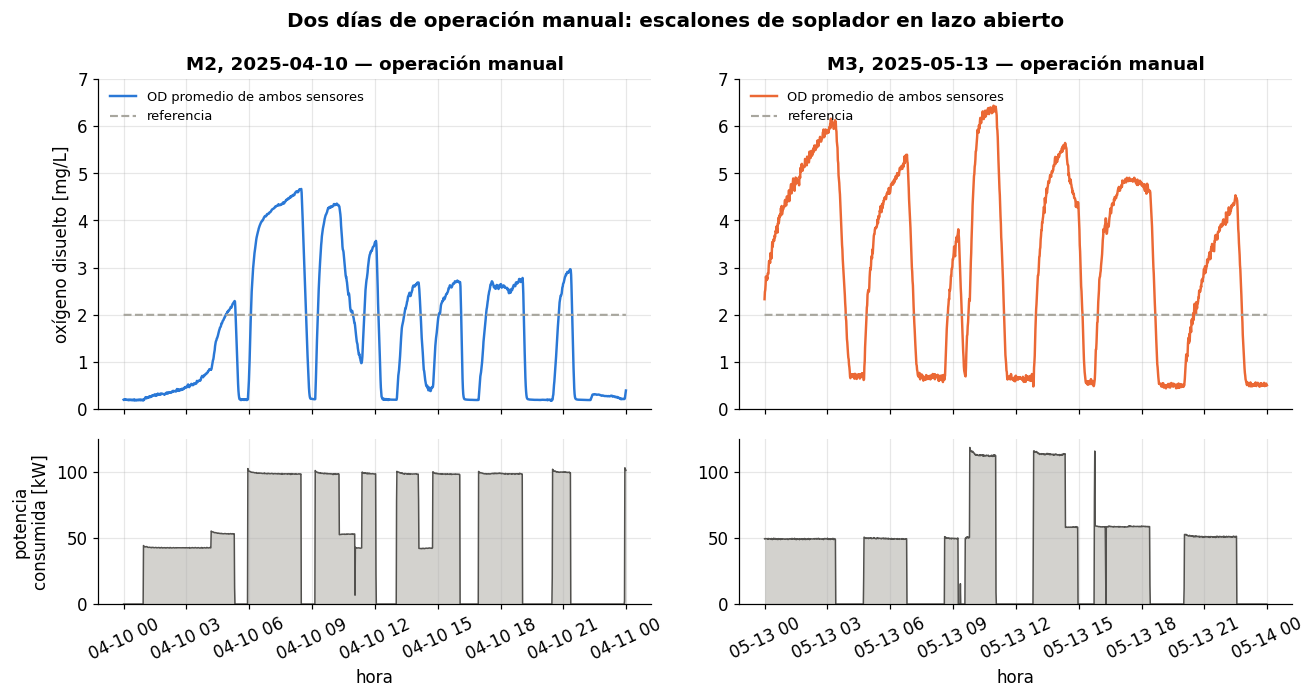

M2  2025-04-10  OD: min 0.18  mediana 1.12  máx 4.67 mg/L  |  soplador: 7 arranques, 66 % del día encendido
M3  2025-05-13  OD: min 0.44  mediana 3.57  máx 6.43 mg/L  |  soplador: 8 arranques, 62 % del día encendido

M2 2025-04-10, pulso a pulso:

pulso    OD ini    OD pico    t63 subida  t63 bajada
1        0.19      2.29            213 min         8 min
2        0.21      4.66             17 min        16 min
3        0.21      3.57             10 min        10 min
4        0.20      2.69             18 min         7 min
5        0.20      2.76             21 min         8 min
6        0.19      2.97             19 min         8 min

mediana:  subir al 63 % = 18 min   ·   bajar al 63 % = 8 min   ->  factor 2.3


In [2]:
# Dos dias de LAZO ABIERTO, uno por modulo. El regimen no lo decido yo:
# lo dice regimenes_diarios.csv.  (M2 el 13-may estaba en PID, por eso no sale aqui.)
DIAS_MAN = {'M2': '2025-04-10', 'M3': '2025-05-13'}
for m, dd in DIAS_MAN.items():
    assert reg[(reg.modulo==m) & (reg.dia==dd)].regimen.iloc[0].startswith('manual'), m

fig, ax = plt.subplots(2, 2, figsize=(14, 6.2), sharex='col',
                       gridspec_kw={'height_ratios':[2,1], 'hspace':.12, 'wspace':.16})
for j, mod in enumerate(('M2','M3')):
    dia = DIAS_MAN[mod]
    w = d.loc[dia, [mod+'_od', mod+'_sp', mod+'_pot']]
    ax[0,j].plot(w.index, w[mod+'_od'], lw=1.6, color=COL[mod], label='OD promedio de ambos sensores')
    ax[0,j].plot(w.index, w[mod+'_sp'], lw=1.4, ls='--', color=GRIS,
                 label='referencia')
    ax[0,j].set(ylabel='oxígeno disuelto [mg/L]' if j==0 else '', ylim=(0,7),
                title=f'{mod}, {dia} — operación manual')
    ax[0,j].legend(frameon=False, fontsize=8.5, loc='upper left')
    ax[1,j].fill_between(w.index, 0, w[mod+'_pot'], color=GRIS, alpha=.5, lw=0)
    ax[1,j].plot(w.index, w[mod+'_pot'], lw=1, color='#52514e')
    ax[1,j].set(ylabel='potencia\nconsumida [kW]' if j==0 else '', xlabel='hora', ylim=(0,125))
    ax[1,j].tick_params(axis='x', rotation=25)
fig.suptitle('Dos días de operación manual: escalones de soplador en lazo abierto',
             fontsize=13, fontweight='bold', y=.98)
fig.savefig('../../Latex/Tesis/figuras/ident_01_dos_dias_manual.pdf', bbox_inches='tight')
plt.show()

for mod, dia in DIAS_MAN.items():
    w = d.loc[dia, [mod+'_od', mod+'_pot']]
    print('%s  %s  OD: min %.2f  mediana %.2f  máx %.2f mg/L  |  soplador: %d arranques, %.0f %% del día encendido'
          % (mod, dia, w[mod+'_od'].min(), w[mod+'_od'].median(), w[mod+'_od'].max(),
             int(((w[mod+'_pot'].shift(1)<3) & (w[mod+'_pot']>10)).sum()),
             100*(w[mod+'_pot']>3).mean()))

# subir cuesta mas que bajar: medido pulso a pulso sobre el dia de M2
w = d.loc[DIAS_MAN['M2'], ['M2_od','M2_pot']]
y = w.M2_od.to_numpy(); P = w.M2_pot.to_numpy(); on = P > 5
tr = np.diff(on.astype(int)); su = np.flatnonzero(tr==1); ba = np.flatnonzero(tr==-1)
print('\nM2 %s, pulso a pulso:\n' % DIAS_MAN['M2'])
print('%-8s %-9s %-9s %11s %11s' % ('pulso','OD ini','OD pico','t63 subida','t63 bajada'))
subs, bajs = [], []
for k, a in enumerate(su):
    b = ba[ba > a]
    if not len(b): continue
    b = b[0]; fin = su[su > b][0] if len(su[su > b]) else len(y)-1
    dy = y[b] - y[a]
    if dy < .5: continue
    ks = np.flatnonzero(y[a:b] >= y[a] + .63*dy)
    kb = np.flatnonzero(y[b:fin] <= y[b] - .63*dy)
    if not len(ks) or not len(kb): continue
    subs.append(ks[0]); bajs.append(kb[0])
    print('%-8d %-9.2f %-9.2f %9d min %9d min' % (k+1, y[a], y[b], ks[0], kb[0]))
print('\nmediana:  subir al 63 %% = %d min   ·   bajar al 63 %% = %d min   ->  factor %.1f'
      % (np.median(subs), np.median(bajs), np.median(subs)/max(np.median(bajs),1)))

Los operarios suben y bajan el soplador a mano. **Sin saberlo, eso es un ensayo
de identificación**: hay excitación en la entrada y respuesta en la salida. En M2
son siete pulsos de 0 a ~100 % en un día, con el oxígeno recorriendo de 0,2 a
4,7 mg/L; en M3, seis ciclos que llegan a 6,4.

**Fíjate en que subir cuesta mucho más tiempo que bajar** — la tabla de abajo lo
mide pulso a pulso: 18 minutos para subir al 63 %, 8 para bajar. Esa asimetría
reaparece en §6 sobre los 532 escalones y es una de las cosas que un modelo
lineal de primer orden **no puede** representar.

> **Por qué estos dos días y no el mismo para los dos módulos.** Hace falta que
> el operario mande y el lazo no. El 13-may-2025 M3 estaba en `manual`, pero M2
> estaba en `pid` (65 cruces de la consigna ese día): con el lazo cerrado la
> potencia se mueve *porque* el oxígeno se movió, y esa realimentación sesga
> cualquier ajuste. Así que para M2 se toma el
> 10-abr-2025, que sí es manual.

---
# 2. El mapa de operación: qué hacía cada módulo, día a día

**De dónde sale.** De `regimenes_diarios.csv` (1.617 filas = 3 módulos × 539
días), que produce `regimenes.py`. Cada día se clasifica en PID / manual /
manual al máximo a partir de tres huellas calculadas sobre el minuto a minuto:

1. el **error de seguimiento** y cuántas veces la medida cruza la consigna,
2. cuánto se aleja el oxígeno **por encima** de ella,
3. si el soplador **modula** o está clavado.

En la figura, «manual» agrupa también los días de soplador al máximo; la
tabla de abajo los sigue separando.

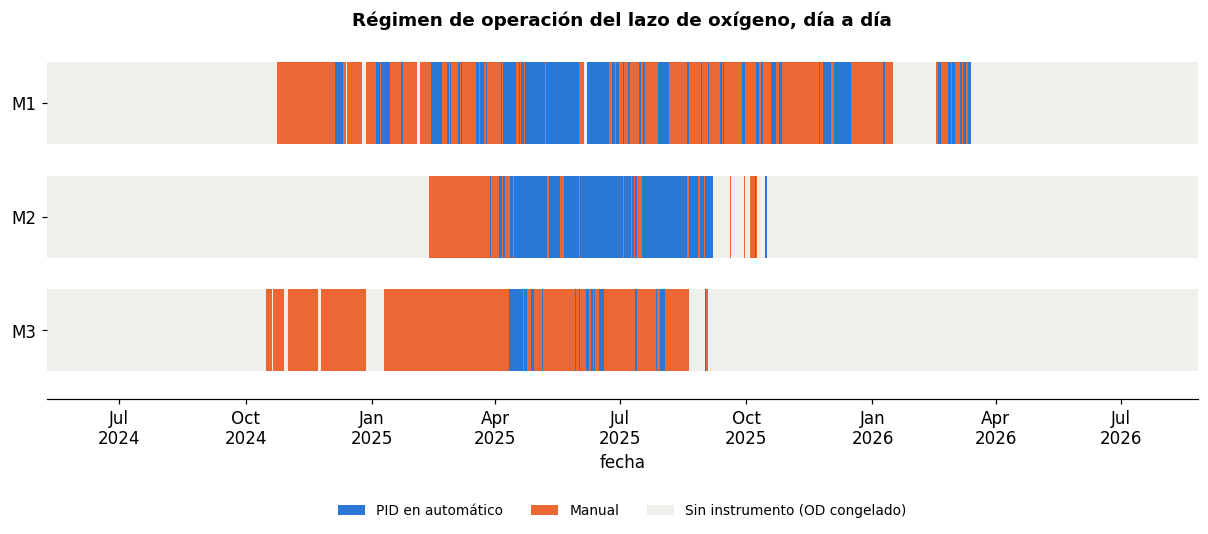

regimen  manual  manual_fijo  manual_maximo  od_cero  pid  soplador_apagado
modulo                                                                     
M1          286            0             16       41  165                 0
M2           68            5              4        0  138                 0
M3          249            1              6        0   31                 4


In [3]:
import matplotlib.dates as mdates
from matplotlib.patches import Patch as _Patch

mods = ['M1','M2','M3']
dias = pd.date_range(reg.dia.min(), reg.dia.max(), freq='D')
fig, ax = plt.subplots(figsize=(13.5, 4.3))
for i, mod in enumerate(mods):
    s = reg[reg.modulo==mod].set_index('dia').regimen.reindex(dias)
    yy = len(mods) - 1 - i
    for dia, r_ in s.items():
        if pd.isna(r_) or r_ in ('sin_datos','od_cero'):  col = '#f0efec'
        elif r_ == 'pid':                                  col = AZUL
        else:                                              col = NARANJA   # manual, incluido el soplador al maximo
        ax.add_patch(plt.Rectangle((mdates.date2num(dia), yy-0.36), 1.0, 0.72,
                     facecolor=col, edgecolor='none', linewidth=0.0))
ax.set_xlim(mdates.date2num(dias[0]), mdates.date2num(dias[-1])); ax.set_ylim(-0.6, 2.6)
ax.xaxis_date(); ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,4,7,10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
ax.set(yticks=range(len(mods)), yticklabels=mods[::-1])
ax.set_title('Régimen de operación del lazo de oxígeno, día a día')
ax.set_xlabel('fecha')
ax.grid(False); ax.spines['left'].set_visible(False)
ax.legend(handles=[_Patch(fc=AZUL, label='PID en automático'),
                   _Patch(fc=NARANJA, label='Manual'),
                   _Patch(fc='#f0efec', label='Sin instrumento (OD congelado)')],
          loc='lower center', bbox_to_anchor=(.5,-.36), ncol=3, frameon=False, fontsize=9)
fig.savefig('../../Latex/Tesis/figuras/ident_02_mapa_operacion.pdf', bbox_inches='tight')
plt.show()
print(reg[reg.regimen!='sin_datos'].groupby(['modulo','regimen']).size().unstack(fill_value=0).to_string())

**La clasificación reproduce sola las fechas de los informes**, que no
intervinieron en ella: M1 no tiene ni un día de PID antes del 27-nov-2024, y M2
y M3 ninguno antes del 14-abr-2025. Dos fuentes independientes —los binarios del
historiador y unos PDF de servicio— coinciden en las fechas.

Lo gris no es «sin registro»: es **instrumento congelado**. Sin ese filtro, M3
aparentaría 119 días de manual al máximo en nov-2025/feb-2026 que en realidad
son el sensor trabado en 9,17 mg/L.

---
# 3. La identificación: de dónde salen τ y K

La salida es tomar **ventanas cortas** (3 h) y preguntar, dentro de cada una:
*«cuando la potencia cambió, ¿cómo respondió el oxígeno?»*. Ahí la
realimentación del operario ya no importa: dentro de la ventana la entrada ya
está dada y solo se estima la respuesta.

El modelo es un primer orden en tiempo discreto:

$$y[k+1] = \varphi\, y[k] + \gamma\, u[k] + \delta$$

y de sus tres coeficientes salen los números que buscamos:

$$\boxed{\;\tau = \frac{-T_s}{\ln \varphi}\;}\qquad
  \boxed{\;K = \frac{\gamma}{1-\varphi}\;}\qquad
  \boxed{\;b_0 = \frac{K}{\tau}\;}$$

que es lo mismo que el modelo continuo $\dot y = (K u - y)/\tau$.

**Qué es `u` aquí.** La consigna de 0 a 100 % que el PLC manda a los variadores
no quedó en el histórico; lo que sí está es la potencia del tablero. Por eso `u`
es la potencia en **% de plena carga**, `u = 100·P/PMAX` (`cruce.pct`, con PMAX =
106,3 kW en M2 y 110,1 kW en M3), y se toma **como si fuera la misma señal de
control**. La diferencia entre las dos —la cadena variador → motor → soplador,
que no es exactamente lineal— no se modela aparte: queda dentro de la
perturbación total `f`, igual que el error al elegir `b₀`, y el ESO la estima
junto con lo demás.

**La validación es exigente a propósito:** se toma *solo* `y[0]` y la `u` real, se
**simula el modelo a ciegas** las 3 horas, y se compara con lo medido. No es
predicción a un paso (que siempre sale optimista), es **simulación libre**.

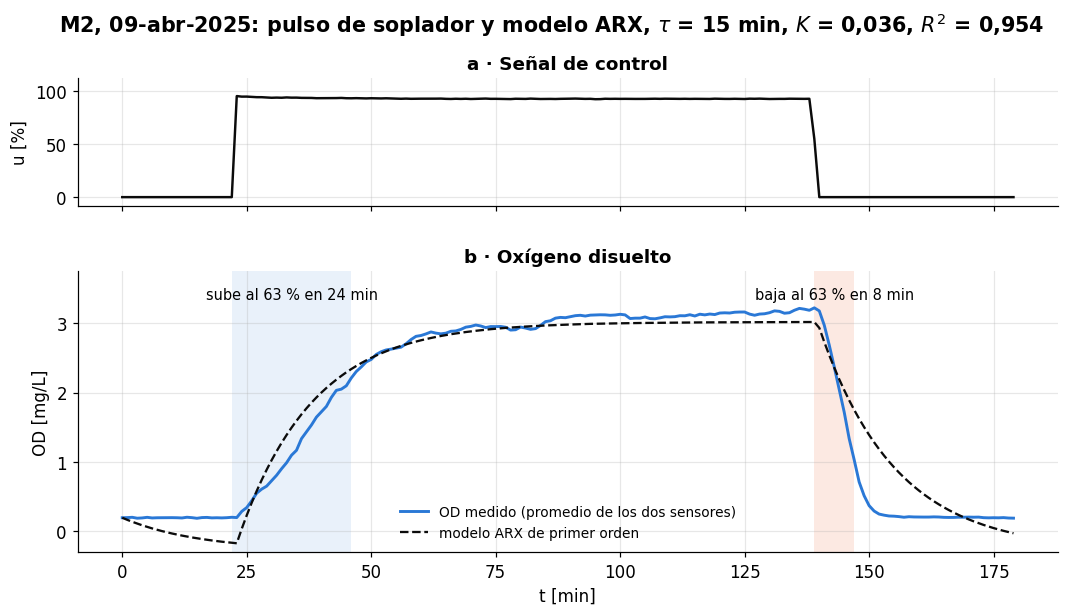

{'phi': np.float64(0.9366), 'tau': np.float64(15.2595), 'K': np.float64(0.0357), 'delta': np.float64(-0.0175), 'r2_sim': np.float64(0.9539), 'n': 180}

la asimetría, medida sobre esta misma ventana:
  el pulso dura 117 min y el OD va de 0.20 a 3.22 mg/L
  pendiente en los últimos 15 min del pulso: +0.26 mg/(L·h)  -> prácticamente asentado
  sube al 63 %: 24 min   ·   baja al 63 %:  8 min   ->  factor 3.0
  el modelo, con un solo τ, tarda lo mismo en las dos: 15 min (= τ)


In [4]:
coma = lambda v, f='%.2f': (f % v).replace('.', ',')
# Ventana de LAZO ABIERTO con un pulso completo: sube, se asienta arriba, y cae.
MOD_EJ, INI_EJ = 'M2', pd.Timestamp('2025-04-09 20:40')
dias_ej = cruce.dias_de(reg, MOD_EJ, 'manual','manual_maximo','manual_fijo')
src_ej = pd.concat([cruce.filtrar_dias(d[MOD_EJ+'_od'], dias_ej).rename('y'),
                    cruce.filtrar_dias(cruce.pct(MOD_EJ, d[MOD_EJ+'_pot']), dias_ej).rename('u')],
                   axis=1)
w = src_ej.loc[INI_EJ:INI_EJ+pd.Timedelta(minutes=179)]
r = ID.arx1(w.y.to_numpy(), w.u.to_numpy())

ys = np.empty(len(w)); ys[0] = w.y.iloc[0]; uu = w.u.to_numpy()
for k in range(len(w)-1):
    ys[k+1] = r['phi']*ys[k] + r['K']*(1-r['phi'])*uu[k] + r['delta']

t = np.arange(len(w)); y = w.y.to_numpy()
on = uu > 5; tr = np.diff(on.astype(int))
a = int(np.flatnonzero(tr==1)[0]); b = int(np.flatnonzero(tr==-1)[np.flatnonzero(tr==-1) > a][0])
dyp = y[b] - y[a]
t63s = int(np.flatnonzero(y[a:b] >= y[a] + .63*dyp)[0])
t63b = int(np.flatnonzero(y[b:] <= y[b] - .63*dyp)[0])

fig, ax, bx = figura_escalon('%s, %s: pulso de soplador y modelo ARX, $\\tau$ = %.0f min, $K$ = %s, $R^2$ = %s'
                             % (MOD_EJ, '%02d-%s-%d' % (INI_EJ.day, ['ene','feb','mar','abr','may','jun','jul','ago','sep','oct','nov','dic'][INI_EJ.month-1], INI_EJ.year), r['tau'], coma(r['K'], '%.3f'), coma(r['r2_sim'], '%.3f')),
                             'Señal de control')
ax.plot(t, uu, lw=1.6, color=NEGRO); ax.set(ylim=(-8, 112), yticks=[0, 50, 100], ylabel='u [%]')
bx.axvspan(a, a+t63s, color=AZUL, alpha=.10, lw=0); bx.axvspan(b, b+t63b, color=NARANJA, alpha=.14, lw=0)
bx.plot(t, y, lw=1.9, color=AZUL, label='OD medido (promedio de los dos sensores)')
bx.plot(t, ys, lw=1.5, ls='--', color=NEGRO, label='modelo ARX de primer orden')
bx.text(a + t63s/2, 3.35, 'sube al 63 %% en %d min' % t63s, ha='center', fontsize=9.5)
bx.text(b + t63b/2, 3.35, 'baja al 63 %% en %d min' % t63b, ha='center', fontsize=9.5)
bx.set(ylabel='OD [mg/L]', xlabel='t [min]', ylim=(-0.3, 3.75))
bx.legend(frameon=False, fontsize=9, loc='lower center')
fig.savefig('../../Latex/Tesis/figuras/ident_03_pulso_arx.pdf', bbox_inches='tight'); plt.show()

print({k:(round(v,4) if isinstance(v,float) else v) for k,v in r.items()
       if k in ('phi','tau','K','delta','r2_sim','n')})
print()
print('la asimetría, medida sobre esta misma ventana:')
print('  el pulso dura %d min y el OD va de %.2f a %.2f mg/L' % (b-a, y[a], y[b]))
print('  pendiente en los últimos 15 min del pulso: %+.2f mg/(L·h)  -> prácticamente asentado'
      % (np.polyfit(np.arange(15), y[b-15:b], 1)[0]*60))
print('  sube al 63 %%: %2d min   ·   baja al 63 %%: %2d min   ->  factor %.1f'
      % (t63s, t63b, t63s/max(t63b,1)))
print('  el modelo, con un solo τ, tarda lo mismo en las dos: %d min (= τ)' % round(r['tau']))

Un solo par (τ, K) reproduce el arranque, la meseta de arriba y el orden de
magnitud de la caída, **sin volver a mirar el oxígeno medido** después del primer
minuto. Eso es lo que autoriza a usar esos dos números.

**Pero fíjate en dónde falla, porque importa.** El oxígeno real cae al 63 % en
8 minutos y el modelo tarda unos 15: un primer orden tiene **un solo τ**, así que
sube y baja con la misma constante de tiempo por construcción. La planta no. Ya
estaba en la figura de §1 (subir cuesta tres veces más que bajar) y se mide
sobre los 532 escalones en §6.

> **Esa discrepancia no es un defecto del ajuste, es el argumento del ADRC.** Todo
> lo que el modelo lineal no captura —la asimetría, la respiración que cambia con
> la carga, la banda muerta del actuador— es exactamente lo que el ESO agrupa en
> `f` y estima en línea. Por eso el diseño no necesita un modelo mejor: necesita
> `b₀` y un observador.

Se repite sobre ventanas deslizantes de 3 h con paso de 1 h. Se descarta una
ventana si la potencia casi no se movió, si el oxígeno casi no se movió, si el
R² de simulación es < 0,5, o si τ cae fuera de 1–300 min.

In [5]:
print('ventanas por módulo y régimen:')
print(T.groupby(['modulo','lazo']).size().to_string()); print()
T.groupby(['modulo','lazo']).agg(n=('K','size'),tau=('tau','median'),K=('K','median'),
    b0=('b0','median'),R2=('r2_sim','median'),
    K_positiva_pct=('K',lambda x:100*(x>0).mean())).round(4)

ventanas por módulo y régimen:
modulo  lazo   
M2      abierto    1225
        cerrado    1108
M3      abierto    1822
        cerrado     337



n      tau       K      b0      R2  K_positiva_pct
modulo lazo                                                          
M2     abierto  1225  16.9033  0.0201  0.0586  0.8422         99.9184
       cerrado  1108  17.7387  0.0402  0.1480  0.8803         98.9170
M3     abierto  1822  24.3736  0.0649  0.1486  0.9002         99.0670
       cerrado   337  20.3513  0.0540  0.1748  0.8952         99.7033

**La ganancia sale positiva en el 99–100 % de las ventanas.** Ese es el primer
resultado: el signo, que la característica estática no conseguía dar.

Los valores de lazo cerrado (días de PID) salen más altos: es el sesgo esperable
de identificar con realimentación activa. **Para diseñar se usan los de lazo
abierto.**

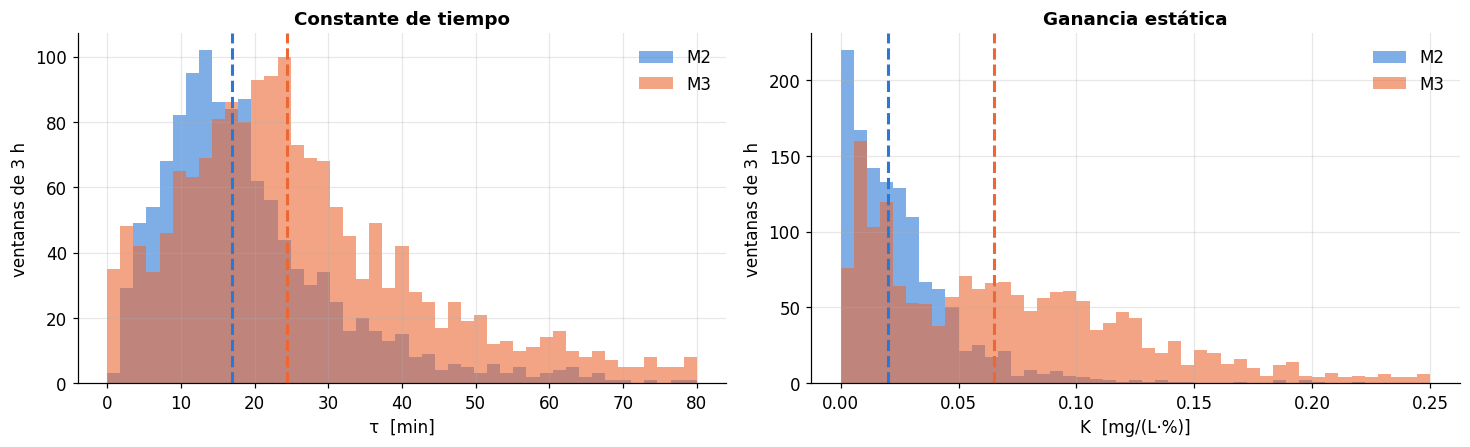

In [6]:
fig,ax=plt.subplots(1,2,figsize=(13.5,4.2))
for i,(v,lab,lim) in enumerate([('tau','τ  [min]',(0,80)),
                                ('K','K  [mg/(L·%)]',(0,.25))]):
    for m in ('M2','M3'):
        s2=ab[ab.modulo==m][v]
        ax[i].hist(s2,bins=45,range=lim,color=COL[m],alpha=.6,label=m)
        ax[i].axvline(s2.median(),color=COL[m],lw=2,ls='--')
    ax[i].set(xlabel=lab,ylabel='ventanas de 3 h'); ax[i].legend(frameon=False)
ax[0].set_title('Constante de tiempo'); ax[1].set_title('Ganancia estática')
plt.tight_layout()
fig.savefig('../../Latex/Tesis/figuras/ident_04_histogramas_tau_K.pdf', bbox_inches='tight')
plt.show()

### Cómo leer estos histogramas, y qué distribución hay detrás

**Qué es una barra.** Un ajuste. Cada ventana de 3 h que pasó los filtros produjo
un par (τ, K) propio, y la barra cuenta cuántas ventanas cayeron en ese intervalo.
No son mediciones repetidas de una misma cantidad: **son la misma planta medida en
3.047 momentos distintos**, cada uno con su carga, su caudal y su punto de
operación.

**De dónde sale cada número, columna por columna.** De `arx_ventanas.csv`, que
produce `identificacion.barrido()`:

| columna | qué es | cómo se obtiene |
|---|---|---|
| `tau` | constante de tiempo [min] | `−Ts/ln φ`, con `Ts` = 1 min |
| `K` | ganancia estática | `γ/(1−φ)` |
| `phi`, `gamma`, `delta` | coeficientes del ARX | mínimos cuadrados sobre las 180 muestras |
| `r2_sim` | R² de **simulación libre** | se simula el modelo desde `y[0]` y se compara |
| `y_med` | punto de operación | media del OD dentro de la ventana |
| `lazo` | abierto / cerrado | del régimen del día en `regimenes_diarios.csv` |

En los histogramas entran **solo las de `lazo == abierto`**: 1.225 de M2 y 1.822
de M3. Los ejes están recortados (0–80 min y 0–0,25) para que se vea el cuerpo de
la distribución; lo que queda fuera es cola, no otro modo.

### Qué distribución se supone: ninguna

Los histogramas son **empíricos**: no hay ninguna densidad ajustada ni ningún
supuesto de normalidad detrás de las cifras del informe. Eso importa porque la
forma **no es normal**, y de ahí viene una decisión que atraviesa todo el trabajo:
**se reporta la mediana y el rango intercuartílico, nunca media ± σ.**

En crudo las cuatro distribuciones están
fuertemente sesgadas a la derecha (asimetría entre +3,5 y +7,5; la media queda un
28–44 % por encima de la mediana). **En logaritmos el sesgo casi desaparece** y el
estadístico de Shapiro sube de 0,49–0,70 a 0,94–0,98: son aproximadamente
**lognormales**, que es lo natural para magnitudes que sólo pueden ser positivas y
que se comparan por cocientes, no por diferencias — «τ el doble» significa algo,
«τ más 20 minutos» no.

## 3.1 Las tres poblaciones de τ en M2: por qué no coinciden con la asimetría (§6)

Es la pregunta correcta y conviene resolverla aquí, porque las dos cifras
conviven en el documento y no coinciden:

| | ARX, ventanas de 3 h | escalón que SUBE | escalón que BAJA |
|---|---|---|---|
| M2 | **16,9 min** | 43,3 min | 3,8 min |
| M3 | **24,4 min** | 35,7 min | 7,2 min |

La reacción natural es *«al menos la subida debería coincidir»*. No coincide, y
**no es por el método**. La celda de abajo lo comprueba de tres maneras.

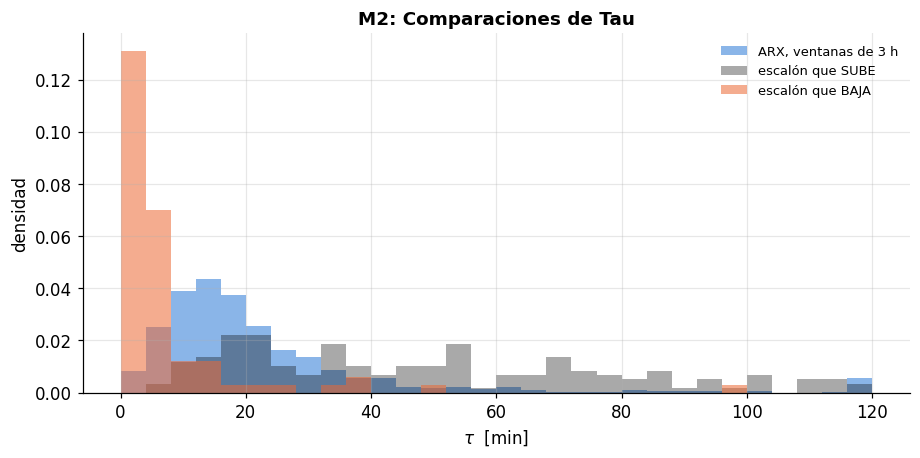

PRUEBA 1 · el mismo tramo, ajustado por los dos métodos
  M2  n= 82   FOPTD  41.8 min  vs  ARX  37.7 min   ->  razón 1.11, corr +0.76
  M3  n=118   FOPTD  36.4 min  vs  ARX  35.4 min   ->  razón 1.03, corr +0.68
  => sobre los MISMOS datos los dos métodos dan lo mismo. No es el método.

PRUEBA 2 · ¿la bajada dentro de la ventana tira de τ hacia abajo?
  M2  ventanas con SOLO subida: n=131  τ= 22.4   |  con subida y bajada: n= 774  τ= 16.3  (-27 %)
  M3  ventanas con SOLO subida: n=260  τ= 26.6   |  con subida y bajada: n=1058  τ= 24.5  (-8 %)
  => sí, pero poco: explica un 8-27 %, no un factor 2.

PRUEBA 3 · ¿de dónde arrancan los escalones que SUBEN?
  M2  el 79 % arranca por debajo de 0,4 mg/L
      arranca en (0.0, 0.4] n=117   τ =  47.6 min
      arranca en (0.4, 0.8] n= 16   τ =  56.9 min
      arranca en (0.8, 1.5] n= 14   τ =  18.6 min
  M3  el 32 % arranca por debajo de 0,4 mg/L
      arranca en (0.0, 0.4] n= 44   τ =  53.2 min
      arranca en (0.4, 0.8] n= 59   τ =  32.1 min


In [7]:
esc42 = pd.read_csv('escalones_limpios.csv', parse_dates=['inicio'])
esc42['y_bar'] = (esc42.y_ini + esc42.y_fin)/2
SUB = esc42[esc42.tipo=='sube']; BAJ = esc42[esc42.tipo=='baja']

# --- prueba 1: EL MISMO TRAMO, ajustado por los dos metodos -----------------
PAR = {}
for m in ('M2','M3'):
    dias42 = cruce.dias_de(reg, m, 'manual','manual_maximo','manual_fijo')
    src42 = pd.concat([cruce.filtrar_dias(d[m+'_od'],dias42).rename('y'),
                       cruce.filtrar_dias(cruce.pct(m,d[m+'_pot']),dias42).rename('u')],axis=1)
    p = []
    for _, rr in SUB[SUB.modulo==m].iterrows():
        w42 = src42.loc[rr.inicio:rr.inicio+pd.Timedelta(minutes=int(rr.n)-1)]
        if len(w42) < int(rr.n)*.9 or w42.isna().any().any(): continue
        a42 = ID.arx1(w42.y.to_numpy(), w42.u.to_numpy())
        if a42 is None or not (1 <= a42['tau'] <= 300): continue
        p.append((rr.tau, a42['tau']))
    PAR[m] = np.array(p)

# --- prueba 2: ventanas ARX que solo contienen subida ------------------------
SOLO = {}
for m in ('M2','M3'):
    dias42 = cruce.dias_de(reg, m, 'manual','manual_maximo','manual_fijo')
    src42 = pd.concat([cruce.filtrar_dias(d[m+'_od'],dias42).rename('y'),
                       cruce.filtrar_dias(cruce.pct(m,d[m+'_pot']),dias42).rename('u')],axis=1)
    ss, aa = [], []
    for _, rr in ab[ab.modulo==m].iterrows():
        w42 = src42.loc[rr.inicio:rr.inicio+pd.Timedelta(minutes=179)]
        if len(w42) < 180 or w42.isna().any().any(): continue
        on42 = w42.u.to_numpy() > 5; tr42 = np.diff(on42.astype(int))
        if (tr42==1).sum() >= 1 and (tr42==-1).sum() == 0: ss.append(rr.tau)
        elif (tr42==1).sum() >= 1: aa.append(rr.tau)
    SOLO[m] = (np.array(ss), np.array(aa))

fig, ax = plt.subplots(figsize=(8.5, 4.3))
bb = np.linspace(0, 120, 31)
ax.hist(ab[ab.modulo=='M2'].tau.clip(0,120), bins=bb, color=AZUL, alpha=.55,
        density=True, label='ARX, ventanas de 3 h')
ax.hist(SUB[SUB.modulo=='M2'].tau.clip(0,120), bins=bb, color='#0b0b0b', alpha=.35,
        density=True, label='escalón que SUBE')
ax.hist(BAJ[BAJ.modulo=='M2'].tau.clip(0,120), bins=bb, color=NARANJA, alpha=.55,
        density=True, label='escalón que BAJA')
ax.set(xlabel=r'$\tau$  [min]', ylabel='densidad', title='M2: Comparaciones de Tau')
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

cor42 = [0,.4,.8,1.5,6]      # tramos de OD de arranque, para la prueba 3

print('PRUEBA 1 · el mismo tramo, ajustado por los dos métodos')
for m in ('M2','M3'):
    p = PAR[m]
    print('  %s  n=%3d   FOPTD %5.1f min  vs  ARX %5.1f min   ->  razón %.2f, corr %+.2f'
          % (m, len(p), np.median(p[:,0]), np.median(p[:,1]),
             np.median(p[:,0])/np.median(p[:,1]), np.corrcoef(p[:,0],p[:,1])[0,1]))
print('  => sobre los MISMOS datos los dos métodos dan lo mismo. No es el método.\n')

print('PRUEBA 2 · ¿la bajada dentro de la ventana tira de τ hacia abajo?')
for m in ('M2','M3'):
    ss, aa = SOLO[m]
    print('  %s  ventanas con SOLO subida: n=%3d  τ=%5.1f   |  con subida y bajada: n=%4d  τ=%5.1f  (%+.0f %%)'
          % (m, len(ss), np.median(ss), len(aa), np.median(aa), 100*(np.median(aa)/np.median(ss)-1)))
print('  => sí, pero poco: explica un 8-27 %, no un factor 2.\n')

print('PRUEBA 3 · ¿de dónde arrancan los escalones que SUBEN?')
for m in ('M2','M3'):
    s = SUB[SUB.modulo==m]
    print('  %s  el %.0f %% arranca por debajo de 0,4 mg/L' % (m, 100*(s.y_ini < .4).mean()))
    g = s.groupby(pd.cut(s.y_ini, cor42), observed=True).agg(n=('tau','size'), tau=('tau','median'))
    for k, r_ in g.iterrows():
        if r_.n >= 8:
            print('      arranca en %-10s n=%3d   τ = %5.1f min' % (str(k), r_.n, r_.tau))
print('  OD medio de las ventanas ARX:  M2 %.2f  ·  M3 %.2f mg/L'
      % (ab[ab.modulo=='M2'].y_med.median(), ab[ab.modulo=='M3'].y_med.median()))

### Las mismas tres poblaciones, ahora para la ganancia estática K

Mismo ejercicio que la figura de τ, con `K` en mg/L por % de plena carga en las
tres fuentes:

- **ARX**: `K = γ/(1−φ)` de cada ventana de 3 h de lazo abierto (`arx_ventanas.csv`).
- **Escalones** (`escalones_limpios.csv`): `K = Δy / (100·Δu/PMAX)`, con Δu en kW
  y el **PMAX corregido** (techo sostenido, 106,3 kW en M2), el mismo `cruce.PMAX` que usa todo el cuaderno.

Las líneas verticales son las medianas.

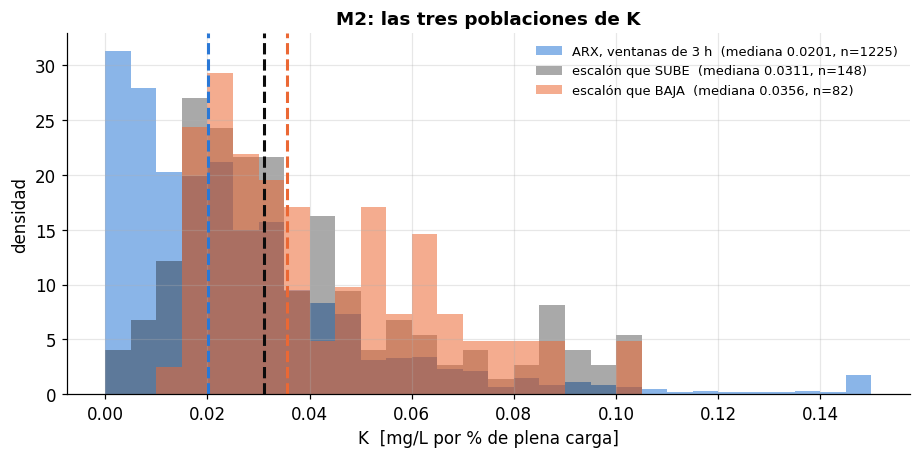

población                  n   mediana       q25       q75    OD típico
ARX, ventanas de 3 h    1225    0.0201    0.0077    0.0342   y_med 0.81
escalón que SUBE         148    0.0311    0.0198    0.0488  0.23 → 2.69
escalón que BAJA          82    0.0356    0.0240    0.0572  2.57 → 0.25


In [8]:
escK = pd.read_csv('escalones_limpios.csv')
escK = escK[escK.modulo == 'M2'].copy()
escK['K_dc'] = [r.dy/(100*r.du/cruce.PMAX[r.modulo]) for _, r in escK.iterrows()]
POB_K = {'ARX, ventanas de 3 h': (ab[ab.modulo == 'M2'].K, AZUL, .55),
         'escalón que SUBE':     (escK[escK.tipo == 'sube'].K_dc, '#0b0b0b', .35),
         'escalón que BAJA':     (escK[escK.tipo == 'baja'].K_dc, NARANJA, .55)}

fig, ax = plt.subplots(figsize=(8.5, 4.3))
bbK = np.linspace(0, .15, 31)
for lab, (s_, c_, al) in POB_K.items():
    ax.hist(s_.clip(0, .15), bins=bbK, color=c_, alpha=al, density=True,
            label='%s  (mediana %.4f, n=%d)' % (lab, s_.median(), len(s_)))
    ax.axvline(s_.median(), color=c_, lw=2, ls='--')
ax.set(xlabel='K  [mg/L por % de plena carga]', ylabel='densidad',
       title='M2: las tres poblaciones de K')
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

print('%-22s %5s %9s %9s %9s %12s' % ('población', 'n', 'mediana', 'q25', 'q75', 'OD típico'))
print('%-22s %5d %9.4f %9.4f %9.4f %12s' % ('ARX, ventanas de 3 h', len(POB_K['ARX, ventanas de 3 h'][0]),
      *ab[ab.modulo=='M2'].K.quantile([.5,.25,.75]), 'y_med %.2f' % ab[ab.modulo=='M2'].y_med.median()))
for t_, lab in (('sube', 'escalón que SUBE'), ('baja', 'escalón que BAJA')):
    g_ = escK[escK.tipo == t_]
    print('%-22s %5d %9.4f %9.4f %9.4f %12s' % (lab, len(g_), *g_.K_dc.quantile([.5,.25,.75]),
          '%.2f → %.2f' % (g_.y_ini.median(), g_.y_fin.median())))

**En K no hay asimetría; en τ sí.** Los escalones que suben y los que bajan dan
ganancias del mismo orden (≈ 0,031 contra ≈ 0,036), mientras que sus τ difieren
en un factor 10. La asimetría de la planta es **dinámica**: cuánto tarda, no
cuánto llega.

El ARX sale más bajo (≈ 0,020) por el punto de operación, no por el método: sus
ventanas viven en una mediana de 0,81 mg/L de oxígeno, y los escalones recorren
de ~0,2 a ~2,6 mg/L. Con `K` creciendo con el OD (§5), esa diferencia de nivel
explica la diferencia de ganancia. Es lo que desarrolla el texto de abajo.

### La respuesta

**No es el método.** La prueba 1 es la decisiva: si se ajusta **el mismo tramo de
datos** con el ARX y con el escalón FOPTD, las dos medianas coinciden dentro del
3–11 % y correlacionan a +0,68/+0,76. Los dos estimadores miden lo mismo.

**Es qué datos mira cada uno.** Y ahí hay dos efectos que se suman:

1. **Los escalones limpios son casi todos arranques en frío.** El filtro de
   `escalones_limpios.csv` exige |Δu| ≥ 20 %, |Δy| ≥ 0,30 mg/L y que la respuesta
   asiente dentro de la ventana. Eso deja fuera los movimientos pequeños y
   selecciona los grandes: **el 79 % de las subidas de M2 arranca por debajo de
   0,4 mg/L**. Un escalón así **cruza toda la no linealidad de §5**: empieza donde
   la planta casi no responde (`K` diez veces menor) y termina donde responde
   bien. Forzar una sola exponencial a través de esa forma en «S» exige un τ
   largo. La prueba 3 lo enseña: los escalones que arrancan entre 0,8 y 1,5 mg/L
   dan **τ ≈ 19 min** en los dos módulos — justo el valor del ARX en M2 (16,9)
   y algo por debajo en M3 (24,4); los que arrancan del suelo dan 48–57 min.
   El trazo de M2 no es monótono: sus dos primeros tramos no se distinguen
   entre sí, el segundo tiene n = 16.

2. **Las ventanas del ARX contienen subida y bajada.** Un solo τ para las dos
   direcciones sale a medio camino. La prueba 2 lo acota: las ventanas que sólo
   contienen subida dan τ = 22,4 min en M2 contra 16,3 de las que contienen las
   dos. Real, pero es un 27 %, no un factor 2.

**Lo mismo vale para `K`.** El ARX da 0,020 en M2 y el escalón 0,036, pero las
ventanas del ARX viven en una mediana de **0,81 mg/L** de oxígeno y los escalones
en 1,51. Con `K ∝ OD` (§5), esa diferencia de punto de operación **es** la
diferencia de ganancia.

> **Qué número usar para diseñar.** El del ARX en el tramo de la consigna
> (§5), porque el ADRC va a trabajar regulando alrededor de
> 2,0 mg/L, no dando escalones desde el suelo. El τ largo de los escalones no es
> un error: es la respuesta **de gran señal** desde el suelo, que es lo que se ve
> en un arranque y lo que el ADRC tiene que sobrevivir, no lo que linealiza.

### Las tres poblaciones de τ y de K, en M2 y en M3

Las dos figuras anteriores en una sola, y con M3 al lado: filas = módulo,
columnas = τ y K. Cada histograma está normalizado como **densidad**: la altura
de una barra es la fracción de ajustes que cae en ese intervalo dividida por su
ancho, $\hat f_j = n_j/(N\,\Delta)$, de modo que el área de cada histograma vale 1
y se pueden comparar poblaciones de tamaño distinto. Las líneas verticales son
las medianas. Es la figura que va a la tesis
(`figuras/ident_05_poblaciones_tau_K.pdf`).

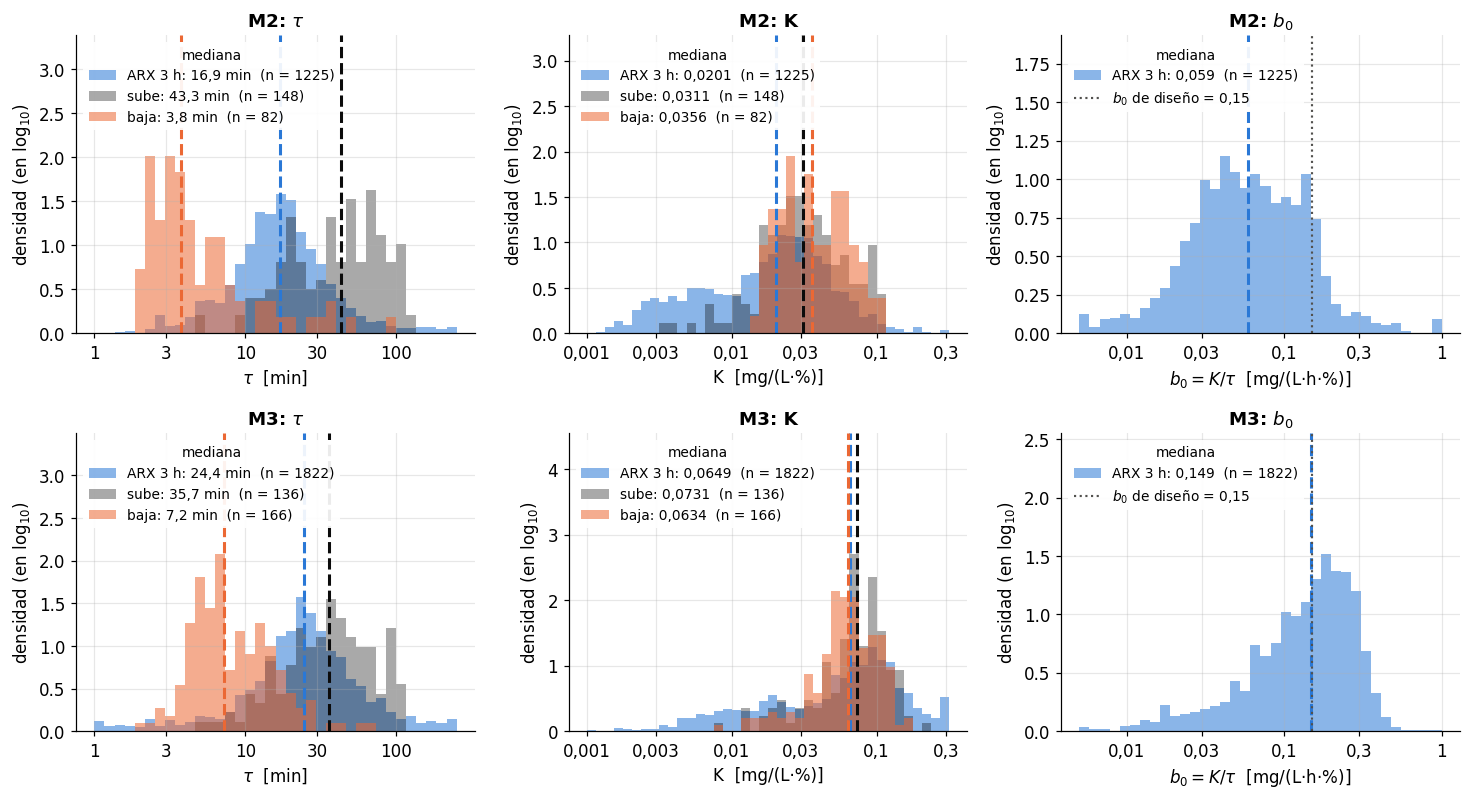

mód  población                  n    tau med      K med     b0 med
M2   ARX, ventanas de 3 h    1225     16.9       0.0201      0.059
M2   escalón que SUBE         148     43.3       0.0311      0.050
M2   escalón que BAJA          82      3.8       0.0356      0.462
M3   ARX, ventanas de 3 h    1822     24.4       0.0649      0.149
M3   escalón que SUBE         136     35.7       0.0731      0.124
M3   escalón que BAJA         166      7.2       0.0634      0.473


In [9]:
escP = pd.read_csv('escalones_limpios.csv')
escP['K_dc'] = escP.dy / (100*escP.du/escP.modulo.map(cruce.PMAX))
ESTILO = {'ARX, ventanas de 3 h': (AZUL, .55),
          'escalón que SUBE':     ('#0b0b0b', .35),
          'escalón que BAJA':     (NARANJA, .55)}
# eje horizontal logaritmico: intervalos de igual ancho en log10 (las tres magnitudes son positivas
# y se comparan por cocientes; en log su forma es casi simetrica)
BINS = {'tau': np.linspace(0, 2.4, 37), 'K': np.linspace(-3, -0.5, 41), 'b0': np.linspace(-2.3, 0, 37)}
TICKS = {'tau': [1, 3, 10, 30, 100], 'K': [0.001, 0.003, 0.01, 0.03, 0.1, 0.3], 'b0': [0.01, 0.03, 0.1, 0.3, 1]}
B0_DIS = 0.15                                       # b0 de diseno, mg/(L·h·%)

_rc = plt.rc_context({'pdf.fonttype': 42, 'font.size': 11})
_rc.__enter__()
fig, ax = plt.subplots(2, 3, figsize=(13.5, 7.4))
for i, m in enumerate(('M2', 'M3')):
    e_ = escP[escP.modulo == m]; a_ = ab[ab.modulo == m]
    POB = {'tau': {'ARX, ventanas de 3 h': a_.tau,
                   'escalón que SUBE': e_[e_.tipo == 'sube'].tau,
                   'escalón que BAJA': e_[e_.tipo == 'baja'].tau},
           'K':   {'ARX, ventanas de 3 h': a_.K,
                   'escalón que SUBE': e_[e_.tipo == 'sube'].K_dc,
                   'escalón que BAJA': e_[e_.tipo == 'baja'].K_dc},
           # b0 = K/tau, con tau en horas: la ganancia de entrada que usa el ADRC
           'b0':  {'ARX, ventanas de 3 h': a_.K / (a_.tau / 60)}}       # b0: solo las ventanas ARX
    for j, var in enumerate(('tau', 'K', 'b0')):
        bb = BINS[var]; fmt = {'tau': '%.1f min', 'K': '%.4f', 'b0': '%.3f'}[var]
        corto = {'ARX, ventanas de 3 h': 'ARX 3 h', 'escalón que SUBE': 'sube', 'escalón que BAJA': 'baja'}
        for lab, s_ in POB[var].items():
            c_, al = ESTILO[lab]
            ax[i, j].hist(np.log10(s_[s_ > 0]).clip(bb[0], bb[-1]), bins=bb, color=c_, alpha=al, density=True,
                          label=('%s: ' + fmt + '  (n = %d)') % (corto[lab], s_.median(), len(s_)))
            ax[i, j].axvline(np.log10(s_.median()), color=c_, lw=2, ls='--')
        if var == 'b0':
            ax[i, j].axvline(np.log10(B0_DIS), color='#52514e', lw=1.4, ls=':', label='$b_0$ de diseño = 0,15')
        ax[i, j].set_xticks(np.log10(TICKS[var]))
        ax[i, j].set_xticklabels([('%g' % v).replace('.', ',') for v in TICKS[var]])
        ax[i, j].set(xlabel={'tau': r'$\tau$  [min]', 'K': 'K  [mg/(L·%)]', 'b0': r'$b_0 = K/\tau$  [mg/(L·h·%)]'}[var],
                     ylabel='densidad (en log$_{10}$)', title='%s: %s' % (m, {'tau': r'$\tau$', 'K': 'K', 'b0': r'$b_0$'}[var]))
        ax[i, j].set_ylim(0, ax[i, j].get_ylim()[1] * 1.6)           # espacio para la leyenda
        for t_ in ax[i, j].legend(frameon=True, framealpha=.92, edgecolor='none', fontsize=9, title='mediana',
                                  title_fontsize=9, loc='upper left').get_texts():
            t_.set_text(t_.get_text().replace('.', ','))
plt.tight_layout()
fig.savefig('../../Latex/Tesis/figuras/ident_05_poblaciones_tau_K.pdf', bbox_inches='tight')
plt.show()
_rc.__exit__(None, None, None)

print('%-4s %-22s %5s %10s %10s %10s' % ('mód', 'población', 'n', 'tau med', 'K med', 'b0 med'))
for m in ('M2', 'M3'):
    e_ = escP[escP.modulo == m]; a_ = ab[ab.modulo == m]
    for lab, g_ in (('ARX, ventanas de 3 h', a_.assign(K_dc=a_.K)),
                    ('escalón que SUBE', e_[e_.tipo == 'sube']),
                    ('escalón que BAJA', e_[e_.tipo == 'baja'])):
        print('%-4s %-22s %5d %8.1f   %10.4f %10.3f' % (m, lab, len(g_), g_.tau.median(), g_.K_dc.median(),
                                                  (g_.K_dc / (g_.tau / 60)).median()))

### Validación directa: el ARX contra lo que se mide en el escalón, sin modelo

Los histogramas comparan **poblaciones**. Aquí se compara **escalón a escalón**:
sobre cada escalón limpio se ajusta el ARX (con 30 min de reposo antes del salto,
para que el ARX vea el cambio de `u`) y se contrasta con dos cantidades que se
leen **directamente en el dato**, sin ajustar nada:

- **t63**: minutos que tarda el OD en recorrer el 63 % del salto medido,
- **K real** = Δy/Δu, con Δy y Δu medidos como diferencia de medias antes y al final del escalón.

Si el ARX representa la planta, los puntos caen sobre la diagonal en **todo el
rango**, no solo en la mediana. Es la figura que va a la tesis
(`figuras/ident_10_validacion_arx.pdf`).

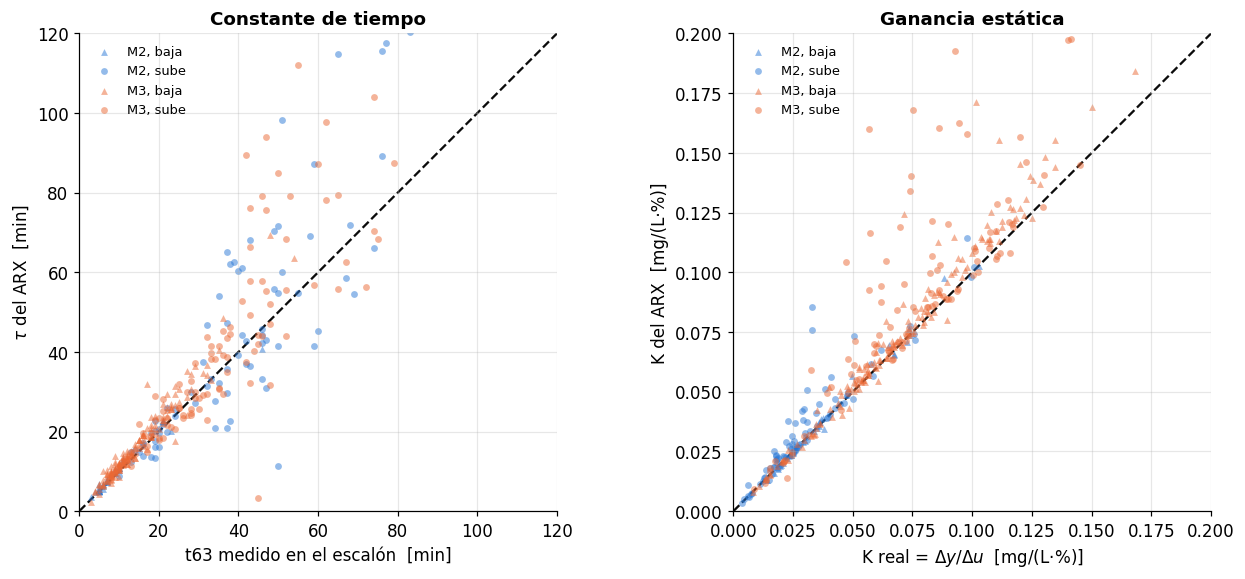

mód  tipo     n    tau ARX      t63   corr      K ARX     K real   corr
M2   baja    35      7.4       7.0   0.99     0.0337     0.0337   1.00
M2   sube    82     40.3      39.5   0.78     0.0286     0.0260   0.92
M3   baja   150     13.6      12.0   0.97     0.0702     0.0667   0.97
M3   sube   106     39.5      37.0   0.74     0.0888     0.0734   0.82

todos: corr tau 0.82 · corr K 0.93 · K real entre 0.014 y 0.120 (percentiles 5-95)


In [10]:
escV = pd.read_csv('escalones_limpios.csv', parse_dates=['inicio'])
VAL = []
for m in ('M2', 'M3'):
    diasV = cruce.dias_de(reg, m, 'manual', 'manual_maximo', 'manual_fijo')
    srcV = pd.concat([cruce.filtrar_dias(d[m+'_od'], diasV).rename('y'),
                      cruce.filtrar_dias(cruce.pct(m, d[m+'_pot']), diasV).rename('u')], axis=1)
    for _, r in escV[escV.modulo == m].iterrows():
        w = srcV.loc[r.inicio - pd.Timedelta(minutes=30): r.inicio + pd.Timedelta(minutes=int(r.n)-1)]
        if len(w) < (int(r.n)+30)*.9 or w.isna().any().any(): continue
        if w.u.iloc[:25].std() > 3: continue                      # reposo previo estable
        a = ID.arx1(w.y.to_numpy(), w.u.to_numpy())
        if a is None or not (0 < a['K'] < 1) or not (1 <= a['tau'] <= 300): continue
        post = srcV.loc[r.inicio: r.inicio + pd.Timedelta(minutes=int(r.n)-1)]
        y0 = srcV.y.loc[r.inicio - pd.Timedelta(minutes=5): r.inicio].mean()
        yf = post.y.iloc[-10:].mean()
        u0 = w.u.iloc[:25].mean(); uf = post.u.iloc[-10:].mean()
        dy, du = yf - y0, uf - u0
        if abs(du) < 10: continue
        yy = post.y.to_numpy(); thr = y0 + .63*dy
        k = np.flatnonzero(yy >= thr if dy > 0 else yy <= thr)
        if not len(k): continue
        VAL.append(dict(modulo=m, tipo=r.tipo, tau_arx=a['tau'], t63=k[0],
                        K_arx=a['K'], K_real=dy/du))
VAL = pd.DataFrame(VAL)

fig, ax = plt.subplots(1, 2, figsize=(12, 5.4))
MARK = {'sube': 'o', 'baja': '^'}
for (m, t), g in VAL.groupby(['modulo', 'tipo']):
    ax[0].scatter(g.t63, g.tau_arx, s=20, alpha=.5, color=COL[m], marker=MARK[t], lw=0,
                  label='%s, %s' % (m, t))
    ax[1].scatter(g.K_real, g.K_arx, s=20, alpha=.5, color=COL[m], marker=MARK[t], lw=0,
                  label='%s, %s' % (m, t))
for j, (lim, xl, yl, tt) in enumerate([((0, 120), 't63 medido en el escalón  [min]', r'$\tau$ del ARX  [min]',
                                        'Constante de tiempo'),
                                       ((0, .20), r'K real = $\Delta y/\Delta u$  [mg/(L·%)]', 'K del ARX  [mg/(L·%)]',
                                        'Ganancia estática')]):
    ax[j].plot(lim, lim, ls='--', lw=1.5, color='#0b0b0b', zorder=0)
    ax[j].set(xlim=lim, ylim=lim, xlabel=xl, ylabel=yl, title=tt)
    ax[j].set_aspect('equal', adjustable='box'); ax[j].legend(frameon=False, fontsize=8.5)
plt.tight_layout()
fig.savefig('../../Latex/Tesis/figuras/ident_10_validacion_arx.pdf', bbox_inches='tight')
plt.show()

print('%-4s %-5s %4s %10s %8s %6s %10s %10s %6s' % ('mód','tipo','n','tau ARX','t63','corr','K ARX','K real','corr'))
for (m, t), g in VAL.groupby(['modulo', 'tipo']):
    print('%-4s %-5s %4d %8.1f %9.1f %6.2f %10.4f %10.4f %6.2f' % (m, t, len(g),
          g.tau_arx.median(), g.t63.median(), np.corrcoef(g.tau_arx, g.t63)[0,1],
          g.K_arx.median(), g.K_real.median(), np.corrcoef(g.K_arx, g.K_real)[0,1]))
print('\ntodos: corr tau %.2f · corr K %.2f · K real entre %.3f y %.3f (percentiles 5-95)'
      % (np.corrcoef(VAL.tau_arx, VAL.t63)[0,1], np.corrcoef(VAL.K_arx, VAL.K_real)[0,1],
         *VAL.K_real.quantile([.05, .95])))

---
# 4. Dos métodos con supuestos de ruido distintos, sobre las mismas ventanas

El ARX supone que el ruido entra **filtrado por el denominador de la planta**; si
la perturbación real tiene otro color —y aquí lo tiene— los estimadores salen
sesgados. Es una propiedad conocida de la estructura.

La prueba: reajustar **las mismas ventanas** con **Output Error**, un método no
lineal que minimiza directamente el error de simulación libre y **no comparte ese
supuesto**. Si los dos coinciden, el sesgo no está mandando.

In [11]:
from scipy.optimize import least_squares

def output_error(yv, uv):
    # minimiza el error de SIMULACION LIBRE sobre (phi, gamma, delta)
    r0 = ID.arx1(yv, uv)
    if r0 is None: return None
    g0 = r0['K']*(1-r0['phi'])
    def sim(pr):
        phi,gam,dl = pr; ys=np.empty(len(yv)); ys[0]=yv[0]
        for k in range(len(yv)-1): ys[k+1]=phi*ys[k]+gam*uv[k]+dl
        return ys
    def res(pr):
        if not (0<pr[0]<0.99999): return np.full(len(yv),1e3)
        return sim(pr)-yv
    sol = least_squares(res,[r0['phi'],g0,r0['delta']],method='lm',max_nfev=3000)
    phi,gam,_ = sol.x
    if not (0<phi<0.99999): return None
    return dict(tau=-1/np.log(phi), K=gam/(1-phi))

rng = np.random.default_rng(0); CMP = {}
for mod in ('M2','M3'):
    dias = cruce.dias_de(reg,mod,'manual','manual_maximo','manual_fijo')
    yy = cruce.filtrar_dias(d[mod+'_od'],dias)
    uu2= cruce.filtrar_dias(cruce.pct(mod,d[mod+'_pot']),dias)
    src= pd.concat([yy.rename('y'),uu2.rename('u')],axis=1)
    t  = ab[ab.modulo==mod]
    idx= rng.choice(len(t), size=min(250,len(t)), replace=False)
    A,O = [],[]
    for i in idx:
        ini = t.inicio.iloc[i]
        w = src.loc[ini:ini+pd.Timedelta(minutes=179)]
        if len(w)<180 or w.isna().any().any(): continue
        r = output_error(w.y.to_numpy(), w.u.to_numpy())
        if r is None or not (1<=r['tau']<=300): continue
        A.append((t.tau.iloc[i], t.K.iloc[i])); O.append((r['tau'], r['K']))
    CMP[mod]=(np.array(A), np.array(O)); A,O = CMP[mod]
    print(f'=== {mod}  ·  {len(A)} ventanas ajustadas por LOS DOS métodos ===')
    print('                  ARX          OE        razón OE/ARX     corr')
    print(f'  tau [min] {np.median(A[:,0]):9.1f} {np.median(O[:,0]):11.1f} {np.median(O[:,0])/np.median(A[:,0]):13.2f} {np.corrcoef(A[:,0],O[:,0])[0,1]:9.3f}')
    print(f'  K         {np.median(A[:,1]):9.4f} {np.median(O[:,1]):11.4f} {np.median(O[:,1])/np.median(A[:,1]):13.2f} {np.corrcoef(A[:,1],O[:,1])[0,1]:9.3f}')
    print()

=== M2  ·  232 ventanas ajustadas por LOS DOS métodos ===
                  ARX          OE        razón OE/ARX     corr
  tau [min]      16.6        16.5          0.99     0.571
  K            0.0209      0.0192          0.92     0.819



=== M3  ·  241 ventanas ajustadas por LOS DOS métodos ===
                  ARX          OE        razón OE/ARX     corr
  tau [min]      24.1        21.7          0.90     0.762
  K            0.0719      0.0711          0.99     0.932



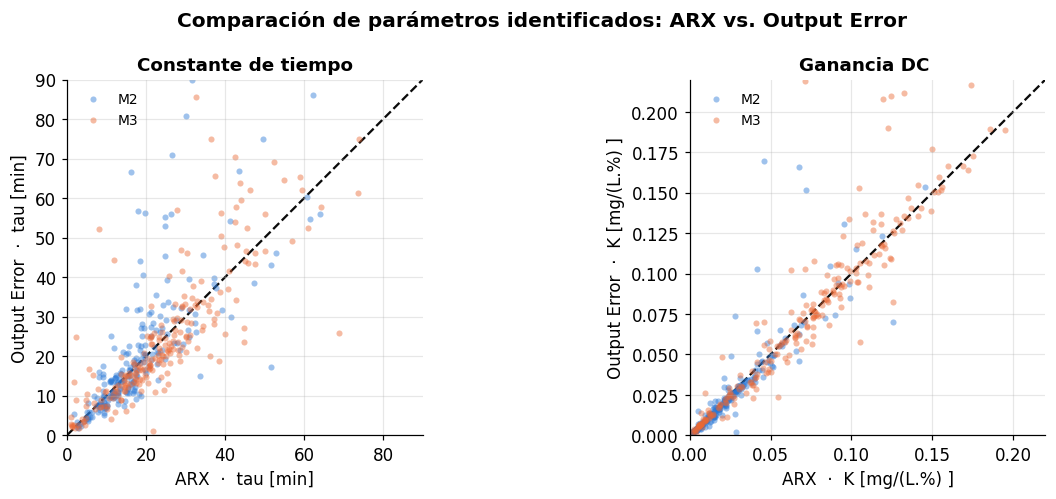

In [12]:
fig,ax=plt.subplots(1,2,figsize=(11.5,4.6))
for j,(v,lab,lim) in enumerate([(0,'tau [min]',(0,90)),(1,'K [mg/(L.%) ]',(0,.22))]):
    for mod in ('M2','M3'):
        A,O = CMP[mod]
        ax[j].scatter(A[:,v],O[:,v],s=16,alpha=.45,color=COL[mod],lw=0,label=mod)
    ax[j].plot(lim,lim,ls='--',lw=1.5,color='#0b0b0b',zorder=0)
    ax[j].set(xlim=lim,ylim=lim,xlabel=f'ARX  ·  {lab}',ylabel=f'Output Error  ·  {lab}',
              title=['Constante de tiempo','Ganancia DC '][j])
    ax[j].legend(frameon=False,fontsize=9); ax[j].set_aspect('equal',adjustable='box')
plt.suptitle('Comparación de parámetros identificados: ARX vs. Output Error',
             fontweight='bold')
plt.tight_layout(); plt.show()

**Las medianas coinciden dentro del 1–10 %** (τ: 0,99 y 0,90 · K: 0,92 y 0,99), y la
correlación ventana a ventana es de **0,57–0,76 en τ y 0,82–0,93 en K**. **El
resultado no lo produce la estructura ARX.** La correlación en τ es la más floja
de las cuatro y conviene no venderla de más: lo que la comprobación sostiene con
firmeza es que **las medianas** no dependen del estimador, no que cada ventana
individual dé lo mismo por los dos caminos.

> **La frase para la tesis:** *Los parámetros se estimaron por regresión ARX sobre
> 4.492 ventanas de 3 h de datos de operación reales, validadas por simulación en
> lazo abierto; la estructura se contrastó reajustando una submuestra por Output
> Error, con diferencias en la mediana menores al 10 %, y el resultado se ancló a
> un ensayo en escalón independiente con la señal de control registrada a 50 ms.*

---
# 5. El resultado central: la ganancia depende del punto de operación

Las distribuciones de arriba son **anchas**. Durante meses eso se interpretó como
*dispersión de la planta*: un factor 12 que había que tolerar a ciegas.

**No es dispersión. Es una dependencia.**

## La misma dependencia, en las tres magnitudes a la vez

### De dónde salen exactamente estos números

La cadena completa, sin saltos:

```
CSV del historiador (WinStudio, 1 min)
   │   OD del PLC  [mg/L]        ← medido por el sensor
   │   potencia del tablero [kW] ← medida por el analizador de energía
   ├─► cruce.maestra()          une los dos en un índice de tiempo único
   ├─► cruce.pct(mod, P)        kW → u [% de plena carga], con PMAX = 106,3 (M2) / 110,1 (M3)
   ├─► cruce.dias_de(reg,…)     se QUEDAN SOLO los días en `manual` (lazo abierto)
   ├─► identificacion.barrido() ventanas de 3 h, paso 1 h; en cada una un ARX(1,1)
   │        y[k+1] = φ y[k] + γ u[k] + δ      →   τ = −1/ln φ ,  K = γ/(1−φ)
   │        se guarda también y_med = media del OD DENTRO de la ventana
   └─► arx_ventanas.csv         3.047 filas de lazo abierto (M2 1.225 · M3 1.822)

esta figura = agrupar esas filas por y_med en cuatro tramos y tomar la MEDIANA
              (la banda sombreada es el rango intercuartílico del tramo)
```

Cada punto de las curvas es, entonces, **la mediana de cientos de ajustes
independientes**, cada uno hecho sobre tres horas distintas del registro. Ningún
número está puesto a mano.

**El eje vertical de cada panel:** `K` en mg/L por cada % de plena carga eléctrica,
τ en minutos, `b₀ = K/τ` con τ en horas. **El eje horizontal** es `y_med`, el
oxígeno medio de la ventana — el «punto de operación» en el que se midió ese par
(τ, K).

### De dónde sale el rombo verde, y por qué cae en 1,2 y no en 2,0

El rombo es el ensayo del ctrlX del **12-mar-2026** (§7 y §10), leído aquí
directamente de la traza a 50 ms con `ensayos.ajustar_escalon`, no copiado a
mano. Para ponerlo sobre esta figura hay que resolver dos cosas: **qué `y` le
corresponde** (el eje vertical) y **qué `x`** (el eje horizontal).

**El eje vertical** es una conversión de unidades. El ensayo se hizo moviendo la
consigna del PLC de 0 a 95 %, así que su ganancia sale en *mg/L por % de
consigna*. El eje de esta figura está en *mg/L por % de plena carga*. Se pasa de
una a otra dividiendo por la pendiente de la cadena de actuación (`cruce.PEND`, §12.3 de `analisis_dinamica.ipynb`), que
vale entre 0,74 y 1,14 % de potencia por cada % de consigna: de ahí la barra
vertical, que no es incertidumbre de medida sino ese rango de conversión.

**El eje horizontal es el que te chirría, y con razón.** El eje dice *"oxígeno
disuelto en la ventana"*, y para las ventanas del ARX eso es `y_med`, la **media
del OD dentro de la ventana**. Para que el rombo sea comparable hay que darle la
misma magnitud: la media del OD **durante el ensayo**. Y el ensayo no fue una
perturbación pequeña alrededor de 2 mg/L — fue un arranque en frío:

| | |
|---|---|
| OD al empezar | **0,02 mg/L** (tanque prácticamente vacío de oxígeno) |
| OD al terminar, 41 min después | 1,83 mg/L |
| asíntota del ajuste de primer orden | 1,85 mg/L |
| **media a lo largo del ensayo** | **1,23 mg/L** ← el `x` del rombo |

Es decir: **el ensayo nunca llegó a 2 mg/L**. Con la consigna al 95 % el módulo
se asentaba en 1,85, y como arrancó desde cero, la media del recorrido queda en
1,23. Por eso el rombo cae en el tramo «0,5 – 1,5» y no en el de consigna.

**La barra horizontal del rombo es justamente eso**: el tramo de oxígeno que el
ensayo recorrió, de 0,02 a 1,85. Un solo punto en el eje x es siempre una
simplificación cuando la prueba barre medio rango de operación; la barra deja ver
la simplificación en vez de esconderla.

> **Y si se colocara en la asíntota (1,85) en vez de en la media?** La celda lo
> imprime: ahí el rombo caería en el tramo «1,5 – 3», donde el ARX da
> `K` = 0,0425, y el ensayo mide 0,0205 — un factor 2 por debajo. O sea que la
> coincidencia **sí depende de dónde se coloque**, y conviene decirlo: lo que el
> ensayo confirma con solidez es el **orden de magnitud de la ganancia a OD
> bajo**, no un cuadre fino en el punto de consigna. La comprobación fuerte de la
> dependencia con el punto de operación es la pareja de escalones de §13.3–13.4 de `analisis_dinamica.ipynb`
> (12-mar contra 16-abr), donde los dos se miden igual y la razón de ganancias
> (1,56) reproduce la razón de estacionarios (1,61).

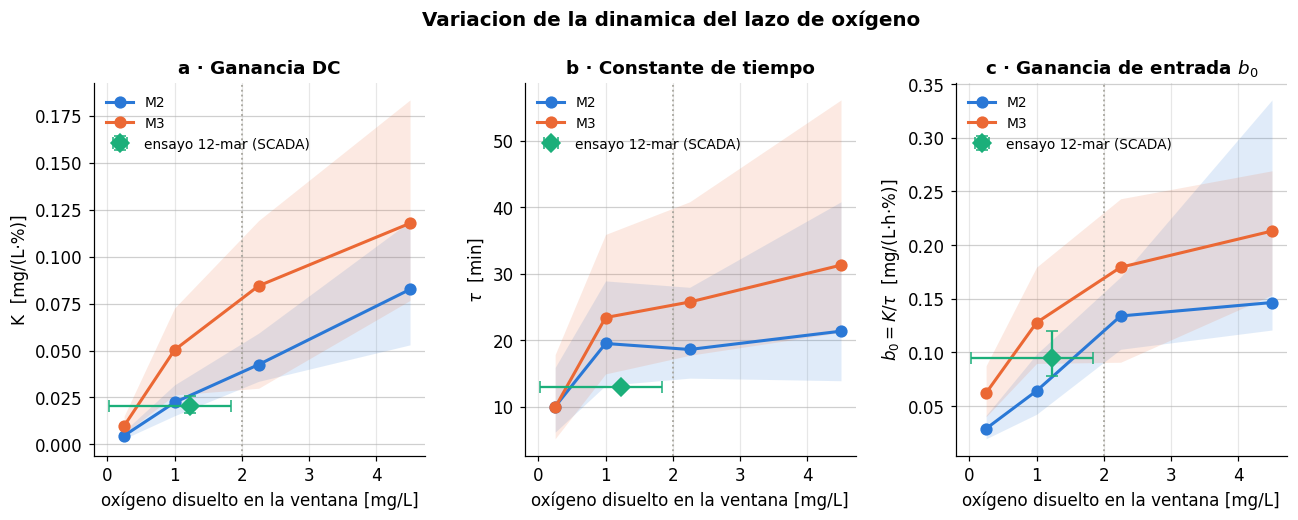

n de ventanas de lazo abierto: 3047  (M2 1225 · M3 1822)

EL ROMBO VERDE, paso a paso
  OD al empezar el ensayo .............. 0.019 mg/L
  OD al que tendía (asíntota del ajuste) 1.846 mg/L
  MEDIA del OD durante los 41 min ..... 1.227 mg/L   <- este es el x del rombo
  mediana del OD durante el ensayo ..... 1.442 mg/L

  K medida  = 0.01923 mg/L por % de CONSIGNA
  pendiente del actuador (M2) = 0.74 a 1.14 %potencia por %consigna
  K  en unidades del eje = 0.01923 / 0.94 = 0.02045 mg/L por % de plena carga
  b0 en unidades del eje = 0.02045 / (13.02/60) = 0.0942 mg/L/(%·h)

  QUE PASA SI SE COLOCA EN OTRO SITIO:
    en x = 1.23 (tramo 0.5-1.5):  ARX M2 K = 0.0223   vs ensayo 0.0205  ->  -8 %
    en x = 1.85 (tramo 1.5-3.0):  ARX M2 K = 0.0425   vs ensayo 0.0205  ->  -52 %


In [13]:
import ensayos as _E
cort5 = [0,.5,1.5,3.,20.]; cen5 = [.25,1.,2.25,4.5]
PEND_M2 = cruce.PEND['M2']          # 0,74 a 1,14 % de potencia por % de consigna

# --- el ensayo del ctrlX del 12-mar-2026, leido del propio registro (no a mano)
_f = _E.ajustar_escalon(_E.cargar('data2'))
K_CTRLX, TAU_CTRLX = _f['K'], _f['tau_min']          # por % de CONSIGNA
OD_INI  = _f['y0']                                   # de donde arranco el ensayo
OD_FIN  = _f['y0'] + _f['dy']                        # asintota del ajuste
OD_MED  = float(np.mean(_f['y']))                    # <-- el x del rombo: MISMA
                                                     #     magnitud que el eje (media)
XERR = [[OD_MED-OD_INI], [OD_FIN-OD_MED]]            # el recorrido que barrio

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
plt.subplots_adjust(wspace=.30)
for ax, var, lab, tit in [
        (axes[0], 'K',  'K  [mg/(L·%)]', 'a · Ganancia DC'),
        (axes[1], 'tau', r'$\tau$  [min]',                 'b · Constante de tiempo'),
        (axes[2], 'b0', r'$b_0=K/\tau$  [mg/(L·h·%)]',     'c · Ganancia de entrada $b_0$')]:
    for mod in ('M2','M3'):
        s5 = ab[ab.modulo==mod]
        g = s5.groupby(pd.cut(s5.y_med, cort5), observed=False)[var]
        med, n_ = g.median().to_numpy(), g.size().to_numpy()
        lo_, hi_ = g.quantile(.25).to_numpy(), g.quantile(.75).to_numpy()
        m_ = n_ >= 15
        ax.plot(np.array(cen5)[m_], med[m_], 'o-', lw=2, ms=7, color=COL[mod], label=mod, zorder=3)
        ax.fill_between(np.array(cen5)[m_], lo_[m_], hi_[m_], color=COL[mod], alpha=.14, lw=0)
    ax.axvline(2.0, color=GRIS, lw=1.2, ls=':')
    ax.set(xlabel='oxígeno disuelto en la ventana [mg/L]', ylabel=lab, title=tit)
    ax.grid(axis='y', alpha=.6); ax.set_axisbelow(True)

# el ensayo, llevado de unidades de consigna a unidades de potencia
km  = K_CTRLX/np.mean(PEND_M2)
b0m = km/(TAU_CTRLX/60)
axes[0].errorbar([OD_MED], [km], xerr=XERR,
                 yerr=[[km-K_CTRLX/max(PEND_M2)], [K_CTRLX/min(PEND_M2)-km]],
                 fmt='D', ms=8, color=VERDE, capsize=4, zorder=5,
                 label='ensayo 12-mar (SCADA)')
axes[1].errorbar([OD_MED], [TAU_CTRLX], xerr=XERR, fmt='D', ms=8, color=VERDE,
                 capsize=4, zorder=5, label='ensayo 12-mar (SCADA)')
axes[2].errorbar([OD_MED], [b0m], xerr=XERR,
                 yerr=[[b0m-K_CTRLX/max(PEND_M2)/(TAU_CTRLX/60)],
                       [K_CTRLX/min(PEND_M2)/(TAU_CTRLX/60)-b0m]],
                 fmt='D', ms=8, color=VERDE, capsize=4, zorder=5,
                 label='ensayo 12-mar (SCADA)')
for a_ in axes: a_.legend(frameon=False, fontsize=9, loc='upper left')
fig.suptitle('Variacion de la dinamica del lazo de oxígeno',
             fontsize=13, fontweight='bold', y=1.03)
fig.savefig('../../Latex/Tesis/figuras/ident_08_ganancia_vs_od.pdf', bbox_inches='tight')
plt.show()
print('n de ventanas de lazo abierto: %d  (M2 %d · M3 %d)'
      % (len(ab), (ab.modulo=='M2').sum(), (ab.modulo=='M3').sum()))
print()
print('EL ROMBO VERDE, paso a paso')
print('  OD al empezar el ensayo .............. %.3f mg/L' % OD_INI)
print('  OD al que tendía (asíntota del ajuste) %.3f mg/L' % OD_FIN)
print('  MEDIA del OD durante los %.0f min ..... %.3f mg/L   <- este es el x del rombo'
      % ((_f['t'][-1]-_f['t'][0])/60, OD_MED))
print('  mediana del OD durante el ensayo ..... %.3f mg/L' % float(np.median(_f['y'])))
print()
print('  K medida  = %.5f mg/L por %% de CONSIGNA' % K_CTRLX)
print('  pendiente del actuador (M2) = %.2f a %.2f %%potencia por %%consigna' % PEND_M2)
print('  K  en unidades del eje = %.5f / %.2f = %.5f mg/L por %% de plena carga'
      % (K_CTRLX, np.mean(PEND_M2), km))
print('  b0 en unidades del eje = %.5f / (%.2f/60) = %.4f mg/L/(%%·h)' % (km, TAU_CTRLX, b0m))
print()
print('  QUE PASA SI SE COLOCA EN OTRO SITIO:')
for xn, xv in (('media del ensayo', OD_MED), ('asíntota del ensayo', OD_FIN)):
    tramo = [(lo,hi) for lo,hi in zip(cort5[:-1],cort5[1:]) if lo < xv <= hi][0]
    kref = ab[(ab.modulo=='M2')&(ab.y_med>tramo[0])&(ab.y_med<=tramo[1])].K.median()
    print('    en x = %.2f (tramo %.1f-%.1f):  ARX M2 K = %.4f   vs ensayo %.4f  ->  %+.0f %%'
          % (xv, tramo[0], tramo[1], kref, km, 100*(km/kref-1)))

---
# 6. La asimetría, vista sobre los 532 escalones

**De dónde sale.** De `escalones_limpios.csv` — los 532 escalones de soplador
que pasan el filtro estricto (|Δu| ≥ 20 %, n ≥ 90 min, R² ≥ 0,90, respuesta
asentada dentro de la ventana, |Δy| ≥ 0,30 mg/L). Cada uno lleva su `tipo`:
`sube` si el operario subió la aireación, `baja` si la bajó.

Aquí no interviene el ARX: son ajustes de primer orden con retardo, escalón a
escalón.

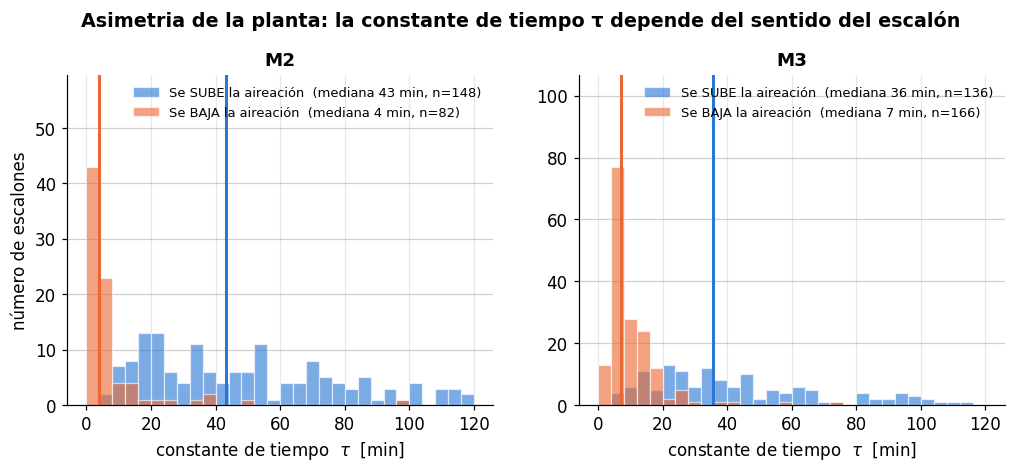

               n  tau_mediana  K_pct
modulo tipo                         
M2     baja   82        3.763  0.042
       sube  148       43.318  0.036
M3     baja  166        7.200  0.070
       sube  136       35.703  0.080


In [14]:
esc7 = pd.read_csv('escalones_limpios.csv', parse_dates=['inicio'])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
bins7 = np.linspace(0, 120, 31)
for ax, mod in zip(axes, ['M2','M3']):
    g = esc7[esc7.modulo == mod]
    for tipo, col, lab in [('sube', AZUL, 'Se SUBE la aireación'),
                           ('baja', NARANJA, 'Se BAJA la aireación')]:
        s7 = g[g.tipo == tipo].tau
        ax.hist(s7, bins=bins7, color=col, alpha=.62, edgecolor='white', linewidth=.8,
                label='%s  (mediana %.0f min, n=%d)' % (lab, s7.median(), len(s7)))
        ax.axvline(s7.median(), color=col, lw=2)
    ax.set(title=mod, xlabel=r'constante de tiempo  $\tau$  [min]',
           ylabel='número de escalones' if mod=='M2' else '')
    ax.set_ylim(0, ax.get_ylim()[1]*1.32)
    ax.grid(axis='y', alpha=.6); ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=8.5, loc='upper right')
fig.suptitle('Asimetria de la planta: la constante de tiempo τ depende del sentido del escalón',
             y=1.03, fontsize=12.5, fontweight='bold')
plt.show()
print(esc7.groupby(['modulo','tipo']).agg(n=('tau','size'), tau_mediana=('tau','median'),
      K_pct=('K_pct','median')).round(3).to_string())

---
# 7. El retardo, medido en M1 a 50 ms

Entre que el PLC cambia la consigna y la sonda ve moverse el oxígeno hay una cadena
física: la rampa del variador, el soplador tomando velocidad, el aire recorriendo la
tubería hasta los difusores, la transferencia desde las burbujas, la mezcla del tanque
y el tiempo de respuesta de la propia sonda. Todo eso aparece como el **retardo** θ del
modelo de primer orden con retardo:

$$G(s)=\frac{K\,e^{-\theta s}}{\tau s+1}$$

**Por qué importa aunque sea corto.** El retardo no cambia la ganancia, cambia la
**fase**: a una frecuencia ω le quita ω·θ radianes. En el ADRC eso pesa en dos sitios:
en ω_c, que fija qué tan rápido se puede prometer el lazo, y sobre todo en ω_o, porque
el observador trabaja varias veces más rápido que el lazo.


**De dónde sale.** De la traza del ctrlX del 12-mar-2026 (M1, consigna 0 → 95 %),
muestreada a **50 ms**: es el único escalón con la consigna registrada a una
resolución que resuelve segundos. El SCADA, a 1 min, no puede ver un retardo de
menos de un minuto.

In [15]:
# ============================================================
# 7.4  El retardo
#   1) ctrlX a 50 ms: el unico escalon con la consigna registrada a esa resolucion
#   2) cuanta fase le quita el retardo al lazo a las frecuencias de diseno
# ============================================================
import ensayos

# --- 1) ctrlX, 50 ms ---------------------------------------------------------
RX = ensayos.cargar('data2')
ux, _ = ensayos.consigna(RX)
tx = RX.index.to_numpy() - RX.index[np.argmax(ux.to_numpy() > 1)]   # t = 0 en el escalon [s]
FX = ensayos.ajustar_escalon(RX)                                    # primer orden + retardo

def despegue(y, t, k=5, sostenido_s=10):
    # SIN modelo: primer instante en que la senal sale del ruido que tenia antes del
    # escalon (media + k sigma) y se queda arriba al menos `sostenido_s` segundos
    base = y[t < 0]
    umbral = base.mean() + max(k * base.std(), 0.01)
    arriba = y > umbral
    n = int(sostenido_s / 0.05)
    for i in np.flatnonzero((t >= 0) & arriba):
        if arriba[i:i+n].all():
            return t[i]
    return np.nan

DESP = {c: despegue(RX[c].to_numpy(), tx) for c in ('OxigenoPromedio', 'Oxigeno_1', 'Oxigeno_2')}

print('ctrlX · M1 · 12-mar-2026 · escalón de consigna 0 → %.0f %% · muestreo 50 ms' % FX['u'])
print('   OD al empezar: %.3f mg/L  (arranque desde el suelo)' % FX['y0'])
print('   primer orden + retardo  : θ = %.0f s   (τ = %.1f min, R² = %.4f)'
      % (FX['theta_s'], FX['tau_min'], FX['r2']))
for c, v in DESP.items():
    print('   sin modelo, %-16s: sale del ruido a los %.0f s' % (c, v))

# --- 2) fase que se pierde: omega [1/h] * theta [h], en grados ---------------------
W74 = {'ω_c = 17 h⁻¹': 17, 'ω_o = 20 h⁻¹ (M3)': 20, 'ω_o = 60 h⁻¹': 60, 'ω_o = 100 h⁻¹ (M2)': 100}
TH74 = {
    'ctrlX, ajuste (%.0f s)' % FX['theta_s']: FX['theta_s'] / 60,
    'ctrlX, sale del ruido (%.0f s)' % DESP['OxigenoPromedio']: DESP['OxigenoPromedio'] / 60}
FASE74 = pd.DataFrame({w: {k: np.degrees(wv * th / 60) for k, th in TH74.items()}
                       for w, wv in W74.items()}).round(0)
print('\nfase que le quita el retardo al lazo, ω·θ [grados]:\n')
print(FASE74.to_string())

ctrlX · M1 · 12-mar-2026 · escalón de consigna 0 → 95 % · muestreo 50 ms
   OD al empezar: 0.019 mg/L  (arranque desde el suelo)
   primer orden + retardo  : θ = 39 s   (τ = 13.0 min, R² = 0.9972)
   sin modelo, OxigenoPromedio : sale del ruido a los 58 s
   sin modelo, Oxigeno_1       : sale del ruido a los 76 s
   sin modelo, Oxigeno_2       : sale del ruido a los 57 s

fase que le quita el retardo al lazo, ω·θ [grados]:

                              ω_c = 17 h⁻¹  ω_o = 20 h⁻¹ (M3)  ω_o = 60 h⁻¹  ω_o = 100 h⁻¹ (M2)
ctrlX, ajuste (39 s)                  11.0               12.0          37.0                62.0
ctrlX, sale del ruido (58 s)          16.0               18.0          55.0                92.0


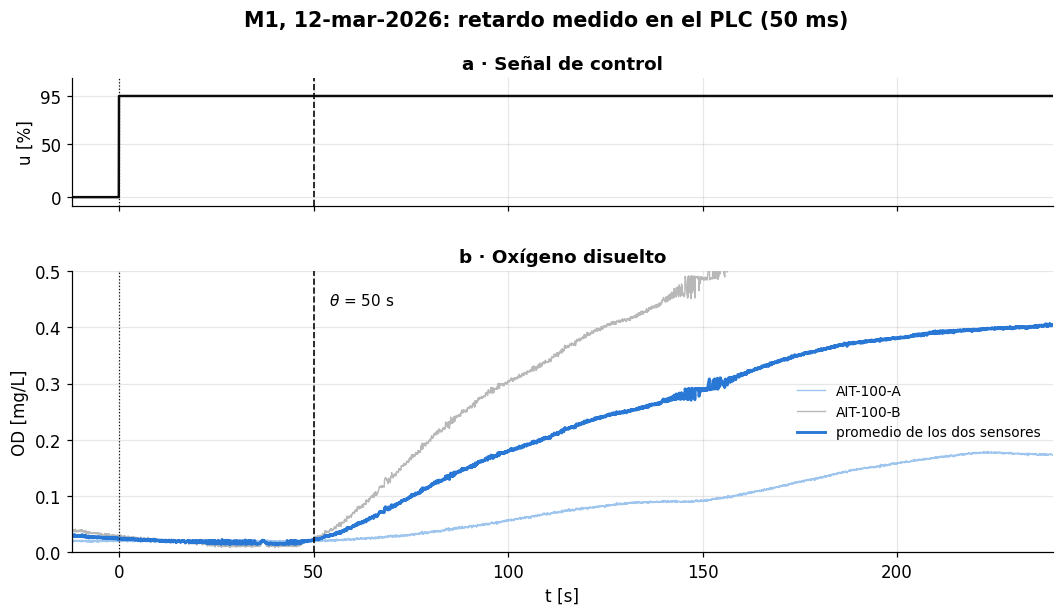

In [16]:
# ident_10: retardo medido en M1 con el ctrlX a 50 ms (12-mar-2026)
v = (tx > -12) & (tx < 240)
fig, ax, bx = figura_escalon('M1, 12-mar-2026: retardo medido en el PLC (50 ms)', 'Señal de control')
ax.plot(tx[v], ux.to_numpy()[v], lw=1.6, color=NEGRO)
ax.set(ylim=(-8, 112), yticks=[0, 50, 95], ylabel='u [%]', xlim=(-12, 240))
bx.plot(tx[v], RX.Oxigeno_1.to_numpy()[v], lw=.9, color='#9ec5ee', label='AIT-100-A')
bx.plot(tx[v], RX.Oxigeno_2.to_numpy()[v], lw=.9, color='0.72', label='AIT-100-B')
bx.plot(tx[v], RX.OxigenoPromedio.to_numpy()[v], lw=1.9, color=AZUL, label='promedio de los dos sensores')
for x in (ax, bx):
    x.axvline(0, color=NEGRO, lw=.8, ls=':'); x.axvline(50, color=NEGRO, lw=1.1, ls='--')
bx.text(54, .44, '$\\theta$ = 50 s', fontsize=10)
bx.set(ylim=(0, .5), ylabel='OD [mg/L]', xlabel='t [s]')
bx.legend(frameon=False, fontsize=9, loc='center right')
fig.savefig('../../Latex/Tesis/figuras/ident_10_retardo_M1.pdf', bbox_inches='tight'); plt.show()


### Lo que sale

**El retardo del lazo es de unos 40 a 60 segundos**, medido en M1 con la consigna
registrada a 50 ms: 39 s según el ajuste de primer orden con retardo, y 58 s hasta que
el promedio de las sondas sale del ruido. La diferencia es de definición, no de dato: el
ajuste coloca θ donde mejor encaja una exponencial, y la respuesta real arranca más
suave. Cada sonda aporta su parte: la 1 sale del ruido a los 76 s y la 2 a los 57 s.

**El SCADA a 1 min no lo puede ver:** el mismo ensayo ajustado desde el SCADA
(§10) da θ = 0 s, porque 40–60 s caben dentro de una sola muestra.

> **Lo que cambia para el ADRC.** Con ω_c = 17 h⁻¹ el retardo nominal le quita al lazo
> 11–16° de fase: tolerable. En el observador no: con ω_o = 100 h⁻¹, el óptimo de M2 en
> §14.3 de `analisis_dinamica.ipynb`, 40–60 s de retardo son **62–92°**. Ese barrido se hizo
> **sin retardo**, así que el óptimo hay que volver a comprobarlo con θ ≈ 1 min.
>
> M2 y M3 son gemelos de M1, pero no hay traza de ellos a 50 ms: el θ ≈ 1 min se
> traslada a M2 y M3 por construcción, no por medida.

---
# 8. Los caudales de cada módulo y su acople con el oxígeno

Esta sección mira los caudales **de uno en uno**, con su ciclo diario, su correlación con el oxígeno
barriendo el retardo, y **cuántos puntos de señal de control vale cada uno**.

| Módulo | Entrada | Recirculación |
|---|---|---|
| **M2** | `M2_SENSOR_FLUJO_DA` | `M2_SENSOR_CAUDAL12IN` |
| **M3** | `M3_SENSOR_CAUDAL_PARSHALL` | `M3_SENSOR_CAUDAL12IN` |

In [17]:
import perturbacion as PT
SANA = {('M2','Q_des'): PT.SANA_QDES['M2'],              # hasta el 5-sep-2025: luego se congela en 11,44 L/s
        ('M2','Q_rec'): slice('2024-12-01','2025-09-20'),
        ('M3','Q_des'): slice('2024-10-16','2025-09-30'),   # antes de congelarse en 60 L/s
        ('M3','Q_rec'): slice('2024-10-16','2026-03-13')}
FALLA = {('M2','Q_des'): PT.FALLA_QDES['M2']}   # dias seguidos por debajo de 5 L/s: falla del sensor
oh = d.resample('1h').mean()

filas=[]
for mod in ('M2','M3'):
    q = H.series(h,mod)
    for nom,s0 in [('Q_des',q.Q_des),('Q_rec',q.Q_rec)]:
        s0 = s0.copy()
        for tramo in FALLA.get((mod,nom), []):
            s0.loc[tramo] = np.nan
        s = s0[SANA[(mod,nom)]].dropna()
        if len(s)<500: continue
        p = s.groupby(s.index.hour).mean()       # media de cada hora: el perfil de la figura
        best=None
        for L in range(0,9):
            j=pd.DataFrame({'q':s0[SANA[(mod,nom)]].shift(L),'od':oh[mod+'_od']}).dropna()
            if len(j)<250: continue
            pp=j.groupby(j.index.hour).mean(); r=pp.q.corr(pp.od)
            if best is None or abs(r)>abs(best[1]): best=(L,r)
        filas.append(dict(modulo=mod, senal=nom, n=len(s),
                          media_Ls=round(p.mean(),1),
                          amplitud_Ls=round(p.max()-p.min(),1),
                          amplitud_pct=round(100*(p.max()-p.min())/p.median()),
                          hora_min=int(p.idxmin()), hora_max=int(p.idxmax()),
                          retardo_h=best[0] if best else np.nan,
                          corr_con_OD=round(best[1],2) if best else np.nan))
pd.DataFrame(filas)

,modulo,senal,n,media_Ls,amplitud_Ls,amplitud_pct,hora_min,hora_max,retardo_h,corr_con_OD
0,M2,Q_des,5357,34.1,9.4,26,4,23,2,-0.70
1,M2,Q_rec,3171,26.2,13.9,51,15,0,0,-0.59
2,M3,Q_des,7450,31.3,7.3,23,6,8,6,0.18
3,M3,Q_rec,7649,164.1,9.2,6,5,11,2,0.48


**Solo uno de los cuatro da una relación limpia con el oxígeno: `Q_des` de M2.**
Los otros tres tienen una razón identificable, y conviene decirla:

- **`Q_rec` de M2** — mide bien, pero no tiene ciclo diario (tiene paradas de
  turno), así que una correlación sobre el perfil de 24 h no puede resolverla.
- **`Q_des` de M3** — el instrumento está sano hasta sep-2025, pero **el sensor de
  oxígeno de M3 no**: su ruido es σ = 0,46 mg/L contra 0,033 de M2.
- **`Q_rec` de M3** — canal en sobrerrango, no mide nunca.

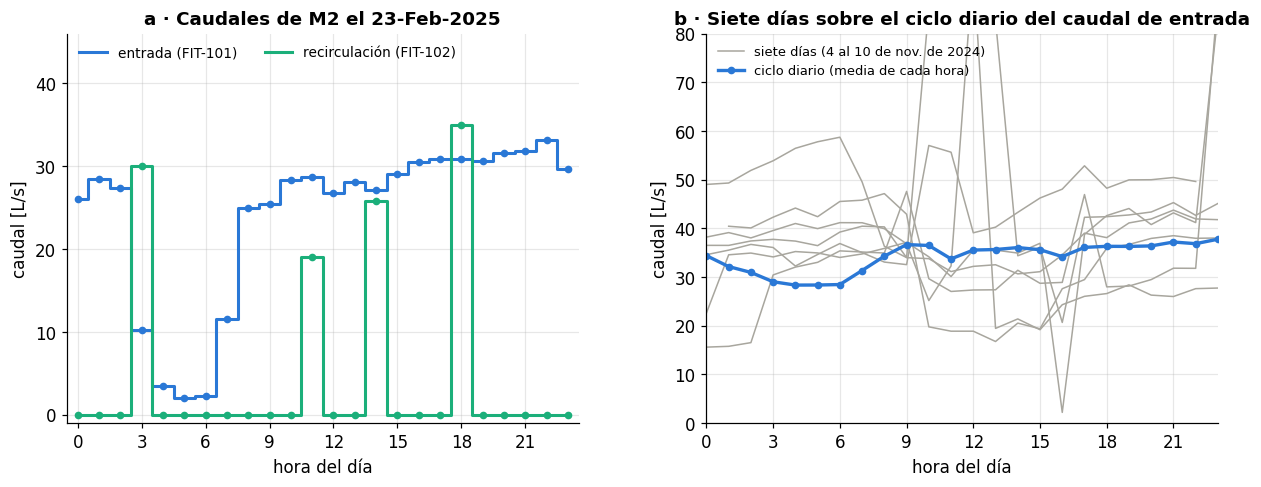

FIT-101: media 34.1 L/s, mínimo 28.4 L/s a las 4 h, máximo 37.8 L/s a las 23 h, vaivén 9.4 L/s
desviación de cada registro respecto al ciclo: σ robusta 13.6 L/s · el ciclo explica el 3.8 % de la varianza


In [18]:
# a) un dia completo de los dos caudales, tal como los guarda el SCADA (cada hora, sin filtrar)
# b) siete dias reales del caudal de entrada sobre su ciclo diario
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={'wspace': .25})

DIA = '2025-02-23'
qraw = pd.DataFrame({c: pd.to_numeric(h[t], errors='coerce') for c, t in H.CORRIENTES['M2'].items()
                     if c in ('Q_des', 'Q_rec')}).where(lambda x: x < 1e4)
dd = qraw.loc[DIA]
for c, col, lab in (('Q_des', AZUL, 'entrada (FIT-101)'), ('Q_rec', VERDE, 'recirculación (FIT-102)')):
    ax[0].step(dd.index.hour, dd[c].to_numpy(), where='mid', lw=2, color=col, label=lab)
    ax[0].plot(dd.index.hour, dd[c].to_numpy(), 'o', ms=4, color=col)
ax[0].set(xlabel='hora del día', ylabel='caudal [L/s]', xticks=range(0, 24, 3), xlim=(-.5, 23.5), ylim=(-1, 46),
          title='a · Caudales de M2 el %s' % pd.Timestamp(DIA).strftime('%d-%b-%Y'))
ax[0].legend(frameon=False, fontsize=9, loc='upper left', ncol=2)

# el ciclo es la media de cada hora en el periodo sano, sin los tramos de falla
s = PT.caudal_sano(h, 'M2')
g = s.groupby(s.index.hour)
p = g.mean()
DIAS = pd.date_range('2024-11-04', periods=7)            # una semana completa, 24 registros por dia
for k, dia in enumerate(DIAS):
    sd = s[dia:dia + pd.Timedelta('23h')]
    ax[1].plot(sd.index.hour, sd.to_numpy(), lw=1, color=GRIS,
               label='siete días (4 al 10 de nov. de 2024)' if k == 0 else None)
ax[1].plot(p.index, p.to_numpy(), 'o-', lw=2.2, ms=4, color=AZUL, label='ciclo diario (media de cada hora)')
ax[1].set(xlabel='hora del día', ylabel='caudal [L/s]', xticks=range(0, 24, 3), xlim=(0, 23), ylim=(0, 80),
          title='b · Siete días sobre el ciclo diario del caudal de entrada')
ax[1].legend(frameon=False, fontsize=8.5, loc='upper left')
fig.savefig('../../Latex/Tesis/figuras/ident_11_caudales_perfil.pdf', bbox_inches='tight')
plt.show()
dev = s - p.reindex(s.index.hour).to_numpy()
print('FIT-101: media %.1f L/s, mínimo %.1f L/s a las %d h, máximo %.1f L/s a las %d h, vaivén %.1f L/s'
      % (p.mean(), p.min(), p.idxmin(), p.max(), p.idxmax(), np.ptp(p)))
print('desviación de cada registro respecto al ciclo: σ robusta %.1f L/s · el ciclo explica el %.1f %% de la varianza'
      % ((dev.quantile(.75) - dev.quantile(.25))/1.349, 100*(1 - dev.var()/s.var())))

El panel b pone cada caudal en la escala del actuador. Los números (`Δf`, puntos
y desvío del OD) salen de la tabla del OE1, §10.2–10.4 de `analisis_dinamica.ipynb`; la
celda de abajo solo los dibuja. La conversión se explica después de la figura.

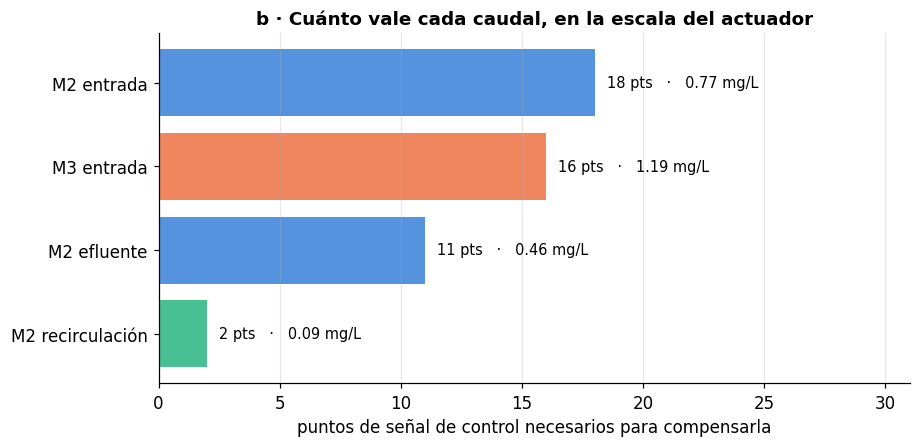

In [19]:
# b) en puntos de senal de control
fig, ax = plt.subplots(figsize=(8.5, 4.2))
orden=sorted(zip([2,11,16,18],
                 ['M2 recirculación','M2 efluente','M3 entrada','M2 entrada'],
                 [0.09,0.46,1.19,0.77],
                 [VERDE,AZUL,NARANJA,AZUL]))
pts=[o[0] for o in orden]; nom_p=[o[1] for o in orden]
mgl=[o[2] for o in orden]; cols=[o[3] for o in orden]
yy=np.arange(len(nom_p))
ax.barh(yy,pts,color=cols,alpha=.8)
for i,(pt,mg) in enumerate(zip(pts,mgl)):
    ax.text(pt+.5,i,'%d pts   ·   %.2f mg/L'%(pt,mg),va='center',fontsize=9.5)
ax.set(yticks=yy,yticklabels=nom_p,xlim=(0,31),
       xlabel='puntos de señal de control necesarios para compensarla',
       title='b · Cuánto vale cada caudal, en la escala del actuador')
ax.grid(axis='y',alpha=0)
plt.tight_layout(); plt.show()

In [20]:
# Recirculacion (FIT-102, M2). No tiene ciclo diario, asi que la pendiente sobre el
# perfil de 24 h no esta determinada: se compara el evento real, bomba en marcha
# contra bomba parada, con la f de cada ventana ARX evaluada en la consigna (f2).
sp_r  = ab[(ab.modulo=='M2') & (ab.y_med.between(1.5, 3))]
B0_SP, TAU_SP = 0.15, sp_r.tau.median()/60      # b0 de diseño (0,15) y tau en la referencia (0,31 h)
tt_r  = T[T.modulo=='M2'].set_index('inicio')
tt_r.index = tt_r.index + pd.Timedelta('90min')            # cada ventana, en su centro
qr_r  = H.series(h,'M2').Q_rec.reindex(tt_r.index, method='nearest', tolerance=pd.Timedelta('90min'))
j_r   = pd.DataFrame({'f':tt_r.f2, 'Qr':qr_r}).dropna(); med_r = j_r.Qr.median()
marcha, paro = j_r[j_r.Qr > 0.8*med_r].f, j_r[j_r.Qr < 0.5*med_r].f
salto = paro.median() - marcha.median()
print(f'  bomba en MARCHA : f = {marcha.median():+.2f} mg/(L·h)   (n = {len(marcha)})')
print(f'  bomba PARADA    : f = {paro.median():+.2f} mg/(L·h)   (n = {len(paro)})')
print(f'  salto Δf        : {abs(salto):.2f} mg/(L·h)  →  {abs(salto)/B0_SP:.0f} puntos'
      f'  ·  desvío de OD Δf·τ = {abs(salto)*TAU_SP:.2f} mg/L')

  bomba en MARCHA : f = -8.27 mg/(L·h)   (n = 639)
  bomba PARADA    : f = -8.36 mg/(L·h)   (n = 122)
  salto Δf        : 0.09 mg/(L·h)  →  1 puntos  ·  desvío de OD Δf·τ = 0.03 mg/L


### Cómo se traduce a puntos, y a mg/L

Dos conversiones, las dos con `b₀` y `τ` **en el punto de consigna**
(M2: `b₀` = 0,15, el de diseño, τ = 0,31 h · M3: `b₀` = 0,179, τ = 0,429 h):

$$\text{puntos}=\frac{\Delta f}{b_0}\qquad\qquad
\text{desvío del OD}=\Delta f\cdot\tau$$

La primera dice **cuánto tiene que moverse el soplador** para compensarla. La
segunda, **cuánto se desviaría el oxígeno si nadie la compensara** — que es la
que hace ver por qué importa.

| Módulo | Perturbación | d`f`/dQ | vaivén | `Δf` | **puntos** | **desvío del OD** |
|---|---|---|---|---|---|---|
| **M2** | Entrada (FIT-101) | −0,182 | 7,0 L/s | 1,27 | **9** | **0,39 mg/L** |
| M2 | Recirculación (FIT-103) | — | — | 0,09 | **1** | 0,03 mg/L |
| **M3** | Entrada (Parshall) | −0,208 | 7,3 L/s | 1,52 | **9** | **0,65 mg/L** |

La pendiente se ajusta entre el perfil diario de f y el perfil diario MEDIDO del
caudal (el de la figura de caudales), y el vaivén es el de ese mismo perfil (ver
`perturbacion.medir`). Las filas de M3 y de recirculación son de una versión anterior.

> **El número que hay que llevar a la defensa:** el ciclo diario del caudal de
> entrada, si el lazo no lo compensara, movería el oxígeno **0,58 mg/L en M2 y
> 0,65 en M3**, casi un tercio de la consigna de 2,0 mg/L. Y cuesta **9 a 14
> puntos** de soplador mantenerlo a raya.
>
> **La recirculación cuesta 1 punto y 0,03 mg/L.** Su valor no está en la
> magnitud, sino en que sus paradas son **predecibles por reloj** (cada 8 h, en
> el cambio de turno).

### La recirculación con el PID en la consigna

El 30-abr-2025, M2 está en la consigna con el PID y el soplador cerca de 37 kW. Desde las 07:00
la bomba de recirculación de lodos trabaja entre 40 y 70 L/s; el PID sube la potencia hasta el
máximo del soplador y, aun así, el OD baja y se queda en unos 0,84 mg/L. La celda de abajo lee:

- la potencia antes, la de la meseta y el OD de la meseta;
- la señal de control que haría falta para sostener 2,0 mg/L con la ganancia nominal
  ($K$ = 0,05 mg/(L·%)), en estacionario: $u_{2} = u + (2{,}0 - y)/K$;
- cuándo vuelve el OD a la consigna y cuándo empieza a bajar la potencia.

El caudal de entrada de ese día no se ve: el FIT-101 de M2 falló entre finales de febrero y mediados de mayo de 2025
(figura `ident_23_recirculacion.pdf` de la tesis).

potencia antes 37.4 kW · meseta 98.5 kW (u = 93 %) · OD en la meseta 0.84 mg/L
para sostener 2,0 mg/L haría falta u ≈ 116 %
el OD vuelve a la consigna a las 30-Apr 22:17; la potencia empieza a bajar a las 30-Apr 22:50 y al final va en 70 kW


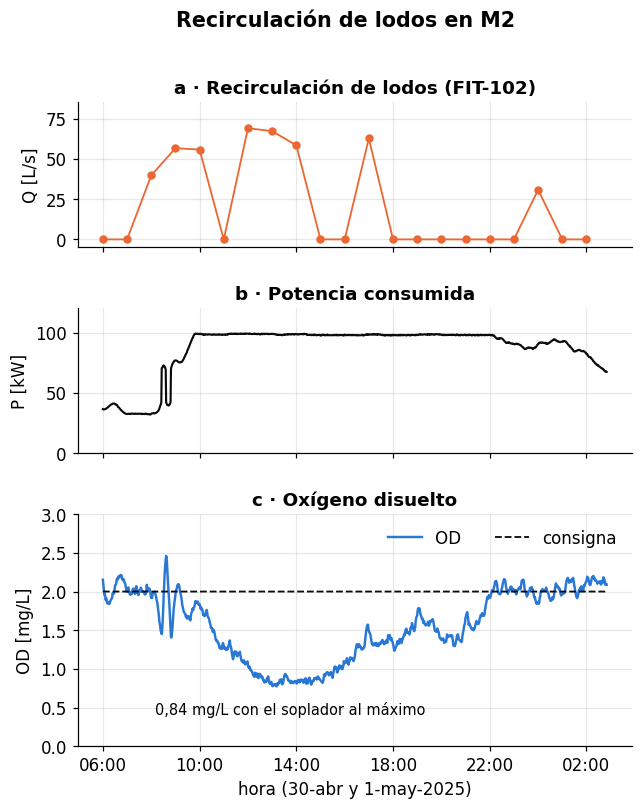

In [21]:
# La recirculacion de lodos satura al PID en M2 (30-abr-2025)
w3   = slice(pd.Timestamp('2025-04-30 06:00'), pd.Timestamp('2025-05-01 02:50'))
qr3  = pd.to_numeric(h[H.CORRIENTES['M2']['Q_rec']], errors='coerce').loc[w3]   # con los ceros (bomba parada)
P3, Y3, R3 = d['M2_pot'].loc[w3], d['M2_od'].loc[w3], d['M2_sp'].loc[w3]

p_antes = P3.loc['2025-04-30 06:00':'2025-04-30 07:00'].median()
p_mes   = P3.loc['2025-04-30 12:30':'2025-04-30 15:00'].median()
y_mes   = Y3.loc['2025-04-30 12:30':'2025-04-30 15:00'].median()
u_mes   = cruce.pct('M2', p_mes)
u_2     = u_mes + (2.0 - y_mes) / 0.05
y30, p30 = Y3.rolling('30min').median(), P3.rolling('30min').median()
t_od  = y30.loc['2025-04-30 15:00':][y30.loc['2025-04-30 15:00':] >= 1.95].index[0]
t_baja = p30.loc[t_od:][p30.loc[t_od:] < 0.95 * p_mes].index[0]
p_fin  = P3.loc['2025-05-01 02:30':].median()
print('potencia antes %.1f kW · meseta %.1f kW (u = %.0f %%) · OD en la meseta %.2f mg/L' % (p_antes, p_mes, u_mes, y_mes))
print('para sostener 2,0 mg/L haría falta u ≈ %.0f %%' % u_2)
print('el OD vuelve a la consigna a las %s; la potencia empieza a bajar a las %s y al final va en %.0f kW'
      % (t_od.strftime('%d-%b %H:%M'), t_baja.strftime('%d-%b %H:%M'), p_fin))

fig, axs = plt.subplots(3, 1, figsize=(6.5, 7.6), sharex=True, gridspec_kw={'height_ratios': [1, 1, 1.6], 'hspace': .35})
axs[0].plot(qr3.index, qr3, '-o', color=NARANJA, ms=4.5, lw=1.2)
axs[0].set(ylabel='Q [L/s]', ylim=(-5, 85), title='a · Recirculación de lodos (FIT-102)')
axs[1].plot(P3.index, P3, color=NEGRO, lw=1.4)
axs[1].set(ylabel='P [kW]', ylim=(0, 120), title='b · Potencia consumida')
axs[2].plot(Y3.index, Y3, color=AZUL, lw=1.6, label='OD')
axs[2].plot(R3.index, R3, color=NEGRO, ls='--', lw=1.2, label='consigna')
axs[2].set(ylabel='OD [mg/L]', ylim=(0, 3), xlabel='hora (30-abr y 1-may-2025)', title='c · Oxígeno disuelto')
axs[2].legend(frameon=False, loc='upper right', ncol=2)
axs[2].annotate('%s mg/L con el soplador al máximo' % coma(y_mes), (pd.Timestamp('2025-04-30 13:45'), y_mes),
                xytext=(0, -22), textcoords='offset points', ha='center', fontsize=9.5)
axs[2].xaxis.set_major_locator(mdates.HourLocator(interval=4))
axs[2].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
fig.suptitle('Recirculación de lodos en M2', fontsize=13.5, fontweight='bold', y=.99)
plt.show()   # la figura de la tesis es la conjunta, dos celdas abajo

### La recirculación sin saturar el PID

No siempre satura. El 24-jun-2025 el PID está quieto en la consigna; hacia las 11:30 se enciende la
bomba (unos 40 L/s) y el PID sube la potencia; hacia las 14:00 se apaga y la potencia vuelve casi al
mismo nivel. El caudal de entrada se mantiene entre 50 y 56 L/s mientras la bomba está encendida, así
que el cambio es de la recirculación. Los cursores marcan la señal de control equivalente,
$u = 100\,P/P_{\max}$, antes y durante el encendido (figura `ident_24_recirculacion_pid.pdf` de la tesis).

u antes 26.1 % · con la bomba 37.8 % · después 27.5 %  →  Δu = 11.6 puntos
entrada mientras la bomba está encendida: [55.0, 50.0, 56.0, 55.0, 54.0] L/s
OD: mínimo 1.77 mg/L, máximo 2.21 mg/L


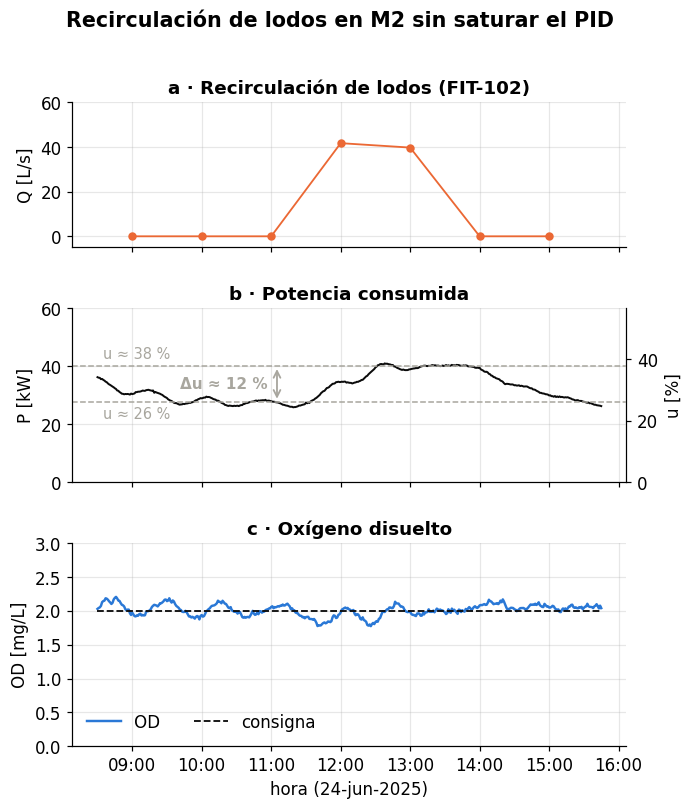

In [22]:
# La recirculacion de lodos con el PID sin saturar en M2 (24-jun-2025)
D4  = '2025-06-24 '
w4  = slice(pd.Timestamp(D4 + '08:30'), pd.Timestamp(D4 + '15:45'))
qr4 = pd.to_numeric(h[H.CORRIENTES['M2']['Q_rec']], errors='coerce').loc[w4]
qd4 = pd.to_numeric(h[H.CORRIENTES['M2']['Q_des']], errors='coerce').loc[w4]
P4, Y4, R4 = d['M2_pot'].loc[w4], d['M2_od'].loc[w4], d['M2_sp'].loc[w4]
PM4 = cruce.PMAX['M2']
p_a = P4.loc[D4 + '09:30':D4 + '11:00'].median()     # antes de la bomba
p_b = P4.loc[D4 + '12:45':D4 + '13:45'].median()     # con la bomba
p_c = P4.loc[D4 + '14:45':D4 + '15:45'].median()     # despues de apagarla
u_a, u_b, u_c = (cruce.pct('M2', x) for x in (p_a, p_b, p_c))
print('u antes %.1f %% · con la bomba %.1f %% · después %.1f %%  →  Δu = %.1f puntos' % (u_a, u_b, u_c, u_b - u_a))
print('entrada mientras la bomba está encendida: %s L/s' % qd4.loc[D4 + '11:00':D4 + '15:00'].round(0).tolist())
print('OD: mínimo %.2f mg/L, máximo %.2f mg/L' % (Y4.min(), Y4.max()))

fig, axs = plt.subplots(3, 1, figsize=(6.5, 7.6), sharex=True, gridspec_kw={'height_ratios': [1, 1.2, 1.4], 'hspace': .35})
axs[0].plot(qr4.index, qr4, '-o', color=NARANJA, ms=4.5, lw=1.2)
axs[0].set(ylabel='Q [L/s]', ylim=(-5, 60), title='a · Recirculación de lodos (FIT-102)')
axs[1].plot(P4.index, P4, color=NEGRO, lw=1.3)
axs[1].set(ylabel='P [kW]', ylim=(0, 60), title='b · Potencia consumida')
sec4 = axs[1].secondary_yaxis('right', functions=(lambda p: 100 * p / PM4, lambda u: u * PM4 / 100)); sec4.set_ylabel('u [%]')
for pv, uv, va, dy in ((p_a, u_a, 'top', -3), (p_b, u_b, 'bottom', 3)):          # cursores
    axs[1].axhline(pv, color=GRIS, ls='--', lw=1)
    axs[1].annotate('u ≈ %s %%' % coma(uv, '%.0f'), (pd.Timestamp(D4 + '08:35'), pv), xytext=(0, dy),
                    textcoords='offset points', va=va, fontsize=9.5, color=GRIS)
t_ar = pd.Timestamp(D4 + '11:05')
axs[1].annotate('', xy=(t_ar, p_b), xytext=(t_ar, p_a), arrowprops=dict(arrowstyle='<->', lw=1.2, color=GRIS))
axs[1].annotate('Δu ≈ %s %%' % coma(u_b - u_a, '%.0f'), (t_ar, (p_a + p_b) / 2), xytext=(-6, 0), textcoords='offset points',
                ha='right', va='center', fontsize=10, color=GRIS, fontweight='bold')
axs[2].plot(Y4.index, Y4, color=AZUL, lw=1.6, label='OD')
axs[2].plot(R4.index, R4, color=NEGRO, ls='--', lw=1.2, label='consigna')
axs[2].set(ylabel='OD [mg/L]', ylim=(0, 3), xlabel='hora (24-jun-2025)', title='c · Oxígeno disuelto')
axs[2].legend(frameon=False, loc='lower left', ncol=2)
axs[2].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
fig.suptitle('Recirculación de lodos en M2 sin saturar el PID', fontsize=13.5, fontweight='bold', y=.99)
plt.show()   # la figura de la tesis es la conjunta, en la celda siguiente

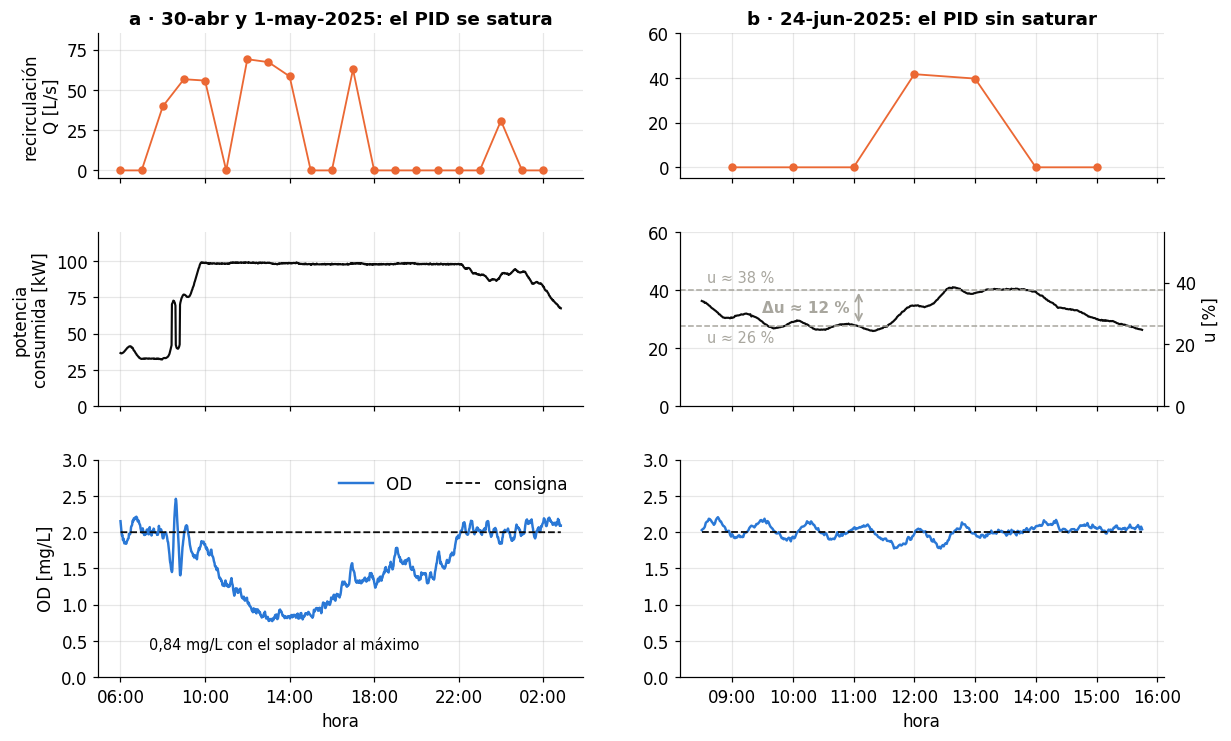

In [23]:
# Figura de la tesis: las dos recirculaciones de M2 en una sola figura, con el formato de la de
# caudales: (a) 30-abr-2025, el PID se satura; (b) 24-jun-2025, el PID sin saturar.
# Usa lo calculado en las dos celdas anteriores.
fig, axs = plt.subplots(3, 2, figsize=(12.5, 7.6), sharex='col',
                        gridspec_kw={'height_ratios': [1, 1.2, 1.5], 'hspace': .3, 'wspace': .2})
for j, (qr, P, Y, R, tit) in enumerate([(qr3, P3, Y3, R3, 'a · 30-abr y 1-may-2025: el PID se satura'),
                                         (qr4, P4, Y4, R4, 'b · 24-jun-2025: el PID sin saturar')]):
    axs[0, j].plot(qr.index, qr, '-o', color=NARANJA, ms=4.5, lw=1.2)
    axs[0, j].set_title(tit)
    axs[1, j].plot(P.index, P, color=NEGRO, lw=1.4)
    axs[2, j].plot(Y.index, Y, color=AZUL, lw=1.6, label='OD')
    axs[2, j].plot(R.index, R, color=NEGRO, ls='--', lw=1.2, label='consigna')
    axs[2, j].set(ylim=(0, 3), xlabel='hora')
    axs[2, j].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
axs[0, 0].set(ylim=(-5, 85), ylabel='recirculación\nQ [L/s]')
axs[0, 1].set(ylim=(-5, 60))
axs[1, 0].set(ylim=(0, 120), ylabel='potencia\nconsumida [kW]')
axs[1, 1].set(ylim=(0, 60))
axs[2, 0].set_ylabel('OD [mg/L]')
axs[2, 0].xaxis.set_major_locator(mdates.HourLocator(interval=4))
axs[2, 0].legend(frameon=False, loc='upper right', ncol=2)
axs[2, 0].annotate('%s mg/L con el soplador al máximo' % coma(y_mes), (pd.Timestamp('2025-04-30 13:45'), y_mes),
                   xytext=(0, -22), textcoords='offset points', ha='center', fontsize=9.5)
# (b): señal de control equivalente en el eje derecho y cursores antes y durante la bomba
sec = axs[1, 1].secondary_yaxis('right', functions=(lambda p: 100 * p / PM4, lambda u: u * PM4 / 100))
sec.set_ylabel('u [%]')
for pv, uv, va, dy in ((p_a, u_a, 'top', -3), (p_b, u_b, 'bottom', 3)):
    axs[1, 1].axhline(pv, color=GRIS, ls='--', lw=1)
    axs[1, 1].annotate('u ≈ %s %%' % coma(uv, '%.0f'), (pd.Timestamp(D4 + '08:35'), pv), xytext=(0, dy),
                       textcoords='offset points', va=va, fontsize=9.5, color=GRIS)
axs[1, 1].annotate('', xy=(t_ar, p_b), xytext=(t_ar, p_a), arrowprops=dict(arrowstyle='<->', lw=1.2, color=GRIS))
axs[1, 1].annotate('Δu ≈ %s %%' % coma(u_b - u_a, '%.0f'), (t_ar, (p_a + p_b) / 2), xytext=(-6, 0),
                   textcoords='offset points', ha='right', va='center', fontsize=10, color=GRIS, fontweight='bold')
fig.savefig('../../Latex/Tesis/figuras/ident_23_recirculacion.pdf', bbox_inches='tight'); plt.show()

---
# 9. Los mejores arranques del PID

**Dónde mirarlas.** La consigna está clavada en 2,0 mg/L todo el registro, así que
no hay escalones de referencia. Pero sí hay algo equivalente y mucho más
abundante: **los arranques del soplador bajo PID**. Ahí el lazo parte del oxígeno
por el suelo y tiene que llevarlo a la consigna — es un escalón de la
perturbación, no de la referencia, pero exhibe la misma dinámica de lazo cerrado.

## 9.1 El PID cuando SÍ funciona

Todo lo anterior mira los arranques, que son el peor caso. Es justo enseñar
también el mejor: **hay tramos donde este PID regula muy bien**, y son el
verdadero listón.

Se buscaron ventanas de 3 a 6 h en días de PID con la consigna fija en 2,0 mg/L,
**exigiendo que el soplador esté modulando** (σ de la potencia con el soplador
encendido > 4 puntos, para excluir los tramos de todo-o-nada) y sin excursiones
mayores de 1,0 mg/L.

In [24]:
def ventanas_buenas(mod, dur, paso=30, u_std_min=4.0, maxdev=1.0):
    dias = cruce.dias_de(reg, mod, 'pid')
    w = pd.concat([cruce.filtrar_dias(d[mod+'_od'],dias).rename('y'),
                   cruce.filtrar_dias(cruce.pct(mod,d[mod+'_pot']),dias).rename('u'),
                   cruce.filtrar_dias(d[mod+'_sp'],dias).rename('r')],axis=1).dropna()
    filas=[]
    for i in range(0, len(w)-dur, paso):
        s = w.iloc[i:i+dur]
        dt = np.diff(s.index.to_numpy()).astype('timedelta64[s]').astype(float)
        if len(dt) and dt.max()>90: continue
        if s.r.nunique()!=1 or s.r.iloc[0]<1.5: continue
        e = s.y - s.r; uon = s.u[s.u>3]
        if len(uon) < dur*0.85 or uon.std() < u_std_min: continue
        if e.abs().max() > maxdev: continue
        filas.append(dict(inicio=s.index[0], iae=e.abs().mean(), rms=np.sqrt((e**2).mean()),
                          sesgo=e.mean(), en_banda=100*(e.abs()<.2).mean(),
                          u_med=s.u.mean(), u_std=uon.std()))
    return pd.DataFrame(filas)

for mod, dur in (('M2',360), ('M3',180)):
    b = ventanas_buenas(mod, dur)
    print(f'--- {mod}: {len(b)} ventanas de {dur//60} h que cumplen; las 5 mejores\n')
    print(b.nlargest(5,'en_banda').round(3).to_string(index=False)); print()

--- M2: 2322 ventanas de 6 h que cumplen; las 5 mejores

             inicio   iae   rms  sesgo  en_banda  u_med  u_std
2025-04-16 20:04:00 0.071 0.086  0.000     100.0 80.839  6.067
2025-04-16 20:34:00 0.070 0.084 -0.001     100.0 80.916  6.158
2025-04-18 06:34:00 0.065 0.073  0.010     100.0 82.493  6.040
2025-04-18 07:04:00 0.072 0.081 -0.001     100.0 81.833  5.446
2025-04-18 23:04:00 0.062 0.073  0.012     100.0 82.377  4.775



--- M3: 75 ventanas de 3 h que cumplen; las 5 mejores

             inicio   iae   rms  sesgo  en_banda  u_med  u_std
2025-04-18 01:21:00 0.069 0.088  0.018    96.667 39.322  4.558
2025-04-18 18:21:00 0.087 0.109  0.002    94.444 48.273  4.791
2025-04-17 10:21:00 0.074 0.100 -0.002    93.333 35.191  4.221
2025-04-17 10:51:00 0.099 0.195 -0.067    92.778 34.785  7.601
2025-04-16 15:21:00 0.088 0.133  0.023    91.667 30.580  4.517



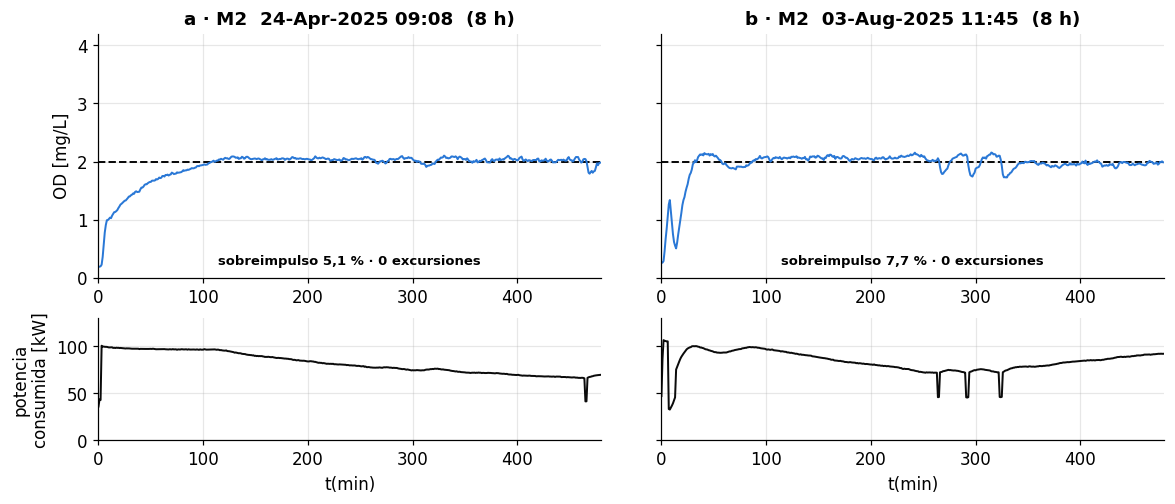

In [25]:
# trayectorias COMPLETAS: desde el oxigeno por el suelo hasta la consigna,
# y horas de regulacion despues. Se eligen por sobreimpulso pequeno y CERO
# excursiones notables (|e| > 0,35 mg/L) despues de alcanzar la consigna.
MEJOR = [('M2', pd.Timestamp('2025-04-24 09:08'), 480, ''),
         ('M2', pd.Timestamp('2025-08-03 11:45'), 480, ''),
         ]   # M3 no tiene ningun arranque limpio: ver la figura siguiente

fig, ax = plt.subplots(2, len(MEJOR), figsize=(12.5, 4.8), sharey='row',      # mismo tamano que la oscilatoria
                       gridspec_kw={'height_ratios':[2,1], 'hspace':.22, 'wspace':.12})
for i,(mod,t0,dur,etq) in enumerate(MEJOR):
    dias = cruce.dias_de(reg,mod,'pid')
    w = pd.concat([cruce.filtrar_dias(d[mod+'_od'],dias).rename('y'),
                   cruce.filtrar_dias(d[mod+'_pot'],dias).rename('u'),
                   cruce.filtrar_dias(d[mod+'_sp'],dias).rename('r')],axis=1).dropna()
    w = w.loc[t0:t0+pd.Timedelta(minutes=dur-1)]
    assert w.r.nunique()==1 and abs(w.r.iloc[0]-2.0)<1e-6, 'la consigna debe ser fija en 2,0'
    # las metricas se calculan sobre el OD CRUDO a 1 min, sin filtrar
    ys = w.y.to_numpy()
    t = np.arange(len(w)); e = ys - 2.0
    k = np.flatnonzero(e>=0)[0]                       # primera vez que toca la consigna
    cola = e[k+60:]                                   # regulacion, ya asentado
    fuera = np.abs(e[k:]) > .35
    exc = int(((fuera.astype(int)-np.roll(fuera.astype(int),1))==1).sum())

    a = ax[0,i]
    a.axhline(2,color='#0b0b0b',lw=1.3,ls='--')
    a.plot(t, w.y.to_numpy(), lw=1.3, color=COL[mod])   # OD crudo a 1 min, sin filtrar
  
    a.set(ylim=(0,4.2), xlim=(0,len(t)),
          ylabel='OD [mg/L]' if i==0 else '',
          title='%s · %s  %s  (%.0f h)' % ('abc'[i], mod, t0.strftime('%d-%b-%Y %H:%M'), dur/60))
    Mp = 100*max(np.nanmax(ys)-2,0)/2.0                 # sobreimpulso en % de la consigna (salto desde cero)
    a.text(.5,.055, 'sobreimpulso %s %% · %d excursiones' % (coma(Mp, '%.1f'), exc),
           transform=a.transAxes, ha='center', fontsize=8.6, fontweight='bold')

    a = ax[1,i]
    a.plot(t,w.u.to_numpy(),lw=1.3,color=NEGRO)       # potencia consumida, el dato medido
   
    a.set(ylim=(0,130), xlim=(0,len(t)), xlabel='t(min)',
          ylabel='potencia\nconsumida [kW]' if i==0 else '')

fig.savefig('../../Latex/Tesis/figuras/ident_13_pid_arranques.pdf', bbox_inches='tight')
plt.show()

## 9.2 La versión oscilatoria: ¿y un M3 que no oscile? No existe

Se buscó explícitamente: **733 ventanas** de M3 con la consigna fija en 2,0, el
oxígeno arrancando bajo y el soplador **modulando de forma sostenida** (recorrido
> 25 puntos, y que siga moviéndose en la segunda mitad). Los de sobreimpulso
pequeño existen —hasta 0,04 mg/L— pero **todos tienen `banda = 0 %` e IAE ≈ 1,0**:
tocan la consigna y se van. Los únicos que regulan bien después son los del
17 de abril, y esos oscilan.

**En los 31 días de PID de M3 no hay ni un solo arranque que suba sin oscilar y
además se quede.** Eso no es una limitación del análisis: es el resultado.

Así que la comparación justa es **oscilatorio contra oscilatorio**: M2 también
los tiene, y sirven para ver que el mecanismo es el mismo en los dos módulos.

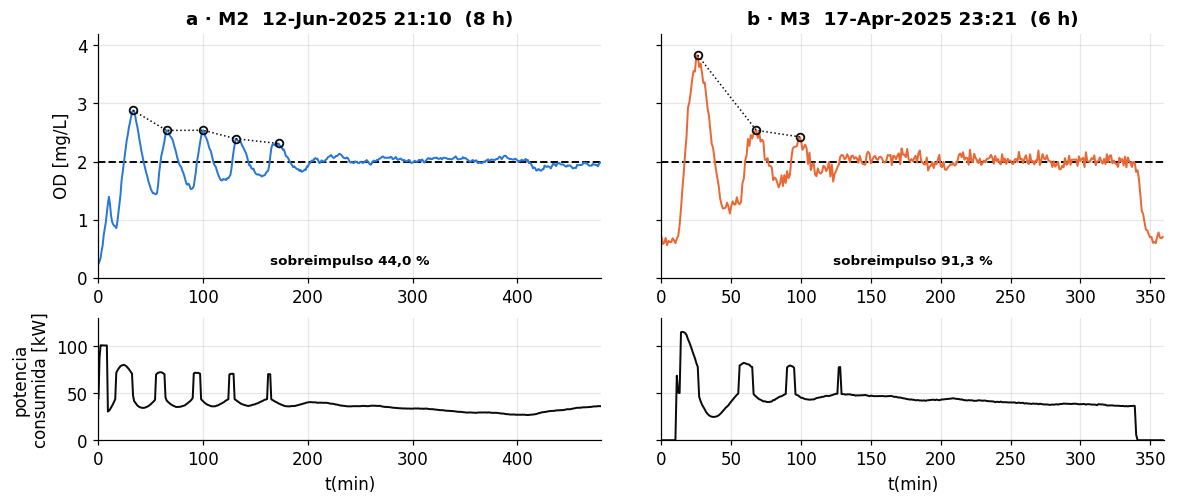

In [26]:
OSCILA = [('M2', pd.Timestamp('2025-06-12 21:10'), 480),
          ('M3', pd.Timestamp('2025-04-17 23:21'), 360)]

fig, ax = plt.subplots(2, 2, figsize=(12.5, 4.8), sharey='row',
                       gridspec_kw={'height_ratios':[2,1], 'hspace':.22, 'wspace':.12})
for i,(mod,t0,dur) in enumerate(OSCILA):
    dias = cruce.dias_de(reg,mod,'pid')
    w = pd.concat([cruce.filtrar_dias(d[mod+'_od'],dias).rename('y'),
                   cruce.filtrar_dias(d[mod+'_pot'],dias).rename('u'),
                   cruce.filtrar_dias(d[mod+'_sp'],dias).rename('r')],axis=1).dropna()
    w = w.loc[t0:t0+pd.Timedelta(minutes=dur-1)]
    assert w.r.nunique()==1 and abs(w.r.iloc[0]-2.0)<1e-6
    ys = w.y.to_numpy()                                # OD crudo a 1 min, sin filtrar
    t = np.arange(len(w)); e = ys - 2.0
    k = np.flatnonzero(e>=0)[0]; cola = e[k+60:]
    # picos sucesivos por encima de la consigna: la envolvente que decae
    from scipy.signal import find_peaks
    pk = list(find_peaks(ys, height=2.3, prominence=0.25, distance=15)[0])   # picos > 0,3 sobre la consigna: oscilacion, no ruido

    a = ax[0,i]
    a.axhline(2,color='#0b0b0b',lw=1.3,ls='--')
    a.plot(t, w.y.to_numpy(), lw=1.3, color=COL[mod])   # OD crudo a 1 min, sin filtrar
    if len(pk) >= 3:
        a.plot(np.array(pk), ys[pk], 'o', ms=5, mfc='none', mec='#0b0b0b', mew=1.2)
        a.plot(np.array(pk), ys[pk], lw=1, ls=':', color='#0b0b0b')
    a.set(ylim=(0,4.2), xlim=(0,len(t)), ylabel='OD [mg/L]' if i==0 else '',
          title='%s · %s  %s  (%.0f h)' % ('ab'[i], mod, t0.strftime('%d-%b-%Y %H:%M'), dur/60))
    Mp = 100*max(np.nanmax(ys)-2,0)/2.0                 # sobreimpulso en % de la consigna (salto desde cero)
    a.text(.5,.055, 'sobreimpulso %s %%' % coma(Mp, '%.1f'),
           transform=a.transAxes, ha='center', fontsize=8.8, fontweight='bold')

    a = ax[1,i]
    a.plot(t,w.u.to_numpy(),lw=1.3,color=NEGRO)       # potencia consumida, el dato medido
    a.set(ylim=(0,130), xlim=(0,len(t)), xlabel='t(min)',
          ylabel='potencia\nconsumida [kW]' if i==0 else '')

fig.savefig('../../Latex/Tesis/figuras/ident_14_pid_oscilatorio.pdf', bbox_inches='tight')
plt.show()

**Los dos módulos hacen exactamente lo mismo**, y es un lazo subamortiguado de
libro: sobreimpulso, y luego una serie de picos con **envolvente decreciente**
hasta engancharse.

| | Ventana | OD inicial | Sobreimpulso | Picos sucesivos | **IAE tras asentar** | **En banda** |
|---|---|---|---|---|---|---|
| **M2** | 12-jun-2025 21:10, 8 h | 0,32 mg/L | 0,74 mg/L | 6 | **0,088** | **86 %** |
| **M3** | 17-abr-2025 23:21, 6 h | 0,64 mg/L | 1,60 mg/L | 4 | **0,134** | **87 %** |

Y en el panel de potencia se ve la causa: **el soplador responde con pulsos, no
con una rampa.** Cada pico del oxígeno tiene su pulso de potencia, y los pulsos
también decaen. El lazo está corrigiendo de más en cada ciclo.

> **Lo que esto dice del diseño.** La oscilación no es ruido ni perturbación: es
> la **respuesta propia del lazo cerrado**, y aparece igual en los dos módulos con
> instrumentación muy distinta. Es sintonía —demasiada ganancia para el `b₀` que
> la planta tiene en ese punto de operación— y encaja con §5: cuando el oxígeno
> ya subió, la ganancia real es hasta cinco veces mayor que cuando arrancó, y el
> PID sigue empujando con la misma fuerza.
>
> **Es exactamente el modo de fallo que un `b₀` programado por punto de operación
> elimina**, y por eso conviene llevar estas dos figuras juntas a la defensa: la
> del arranque limpio muestra que la planta *puede* comportarse bien, y esta
> muestra qué la saca de ahí.

---
# 10. El ensayo del 12 de marzo en el SCADA: subida y bajada

El ensayo del ctrlX (§5 y §7) dura **41 min**: es lo que cabe en el buffer de traza de
500 s con solape. Pero el SCADA registró el mismo evento a 1 min y **sin ese
límite**. Con una ventana de 2 h se ve lo que faltaba: **la bajada**.

## 10.1 Es el mismo evento, y se comprueba

In [27]:
import ensayos
from scipy.optimize import curve_fit

ctrlx = ensayos.cargar('data2')
T0 = pd.Timestamp('2026-03-12 16:27')          # fecha del §5 y §7, por correlación
c = ctrlx[['OxigenoPromedio','Soplador_1_Consigna']].copy()
c.index = T0 + pd.to_timedelta(c.index - c.index.min(), unit='s')
cm = c.resample('1min').mean()

sc = d.loc[cm.index.min():cm.index.max(), ['M1_od1','M1_od2','M1_od']]
j  = pd.concat([cm, sc], axis=1).dropna()
print(f'solape: {len(j)} min')
print(f'  corr(promedio ctrlX, M1_od del SCADA) = {j.OxigenoPromedio.corr(j.M1_od):.4f}')
print(f'  RMSE = {np.sqrt(((j.OxigenoPromedio - j.M1_od)**2).mean()):.3f} mg/L')

solape: 40 min
  corr(promedio ctrlX, M1_od del SCADA) = 0.9996
  RMSE = 0.020 mg/L


**Correlación 0,9996 y RMSE 0,020 mg/L.** Son la misma medida por dos caminos, lo
que cierra el fechado que en su día se hizo por correlación de trayectorias.

## 10.2 Subida y bajada, con el mismo modelo

Se ajusta un primer orden con retardo a cada tramo por separado, exactamente
igual que se hizo con la traza del ctrlX.

In [28]:
def foptd(t, y0, dy, tau, th):
    z = np.clip((t - th)/max(tau, 1e-6), 0, None)
    return y0 + dy*(1 - np.exp(-z))*(t >= th)

VENT = slice('2026-03-12 16:10', '2026-03-12 18:30')
yv = d.loc[VENT, 'M1_od'].dropna()
v, idxv = yv.to_numpy(), yv.index

k_sub   = int(np.argmin(v[:30]))                          # el suelo antes de subir
i_bajo  = int(np.flatnonzero(v < 0.5)[-1])                # el fondo tras la caída
k_caida = int(np.flatnonzero(v[:i_bajo] > 1.8)[-1])       # último punto alto
U_ENSAYO = 95.0

AJ = {}
for nom, a, b, sgn in (('subida', k_sub, k_caida, +1),
                       ('bajada', k_caida, min(i_bajo+25, len(v)-1), -1)):
    t = np.arange(b-a+1, dtype=float); vv = v[a:b+1]
    lo = [-1, 0, 1, 0]  if sgn > 0 else [-1, -10, 1, 0]
    hi = [4, 10, 120, 40] if sgn > 0 else [4, 0, 120, 40]
    p, _ = curve_fit(foptd, t, vv, p0=[vv[0], vv[-1]-vv[0], 12, 1],
                     bounds=(lo, hi), maxfev=60000)
    r2   = 1 - ((vv - foptd(t, *p))**2).sum()/((vv - vv.mean())**2).sum()
    rmse = np.sqrt(((vv - foptd(t, *p))**2).mean())
    AJ[nom] = dict(p=p, r2=r2, rmse=rmse, a=a, b=b, t=t, v=vv,
                   t0=idxv[a], t1=idxv[b],
                   pend5=np.polyfit(t[:6], vv[:6], 1)[0]*60,
                   K=p[1]/U_ENSAYO, b0=(p[1]/U_ENSAYO)/(p[2]/60))

# K y b0 SOLO tienen sentido en la subida: son la respuesta a la entrada.
# En la bajada u = 0, asi que lo que se mide es el SUMIDERO, no una ganancia;
# aplicar la misma formula daria un numero real pero enganoso.
print('%-8s %-13s %5s %8s %8s %9s %8s %11s %10s' %
      ('tramo','ventana','n','tau[min]','theta[s]','dy[mg/L]','R2','K [/%cmd]','b0'))
for nom, r in AJ.items():
    K_ = '%11.5f' % r['K']  if nom == 'subida' else '%11s' % '—'
    b_ = '%10.4f' % r['b0'] if nom == 'subida' else '%10s' % '—'
    print('%-8s %s-%s %5d %8.1f %8.0f %+9.3f %8.4f %s %s' %
          (nom, r['t0'].strftime('%H:%M'), r['t1'].strftime('%H:%M'), len(r['t']),
           r['p'][2], r['p'][3]*60, r['p'][1], r['r2'], K_, b_))
print()
print('  K  = dy / du          con du = %.0f puntos de consigna (de la traza del ctrlX)' % U_ENSAYO)
print('  b0 = K / tau[h]       -> %.4f / (%.1f/60) = %.4f mg/L/(%%·h)'
      % (AJ['subida']['K'], AJ['subida']['p'][2], AJ['subida']['b0']))
print('  en la bajada no se reporta: con u = 0 se mide el sumidero, no la ganancia')
print()
print('ctrlX (misma traza, ajustada en §5): tau %.1f min · K %.4f /%%cmd · b0 %.4f · R2 %.4f'
      % (_f['tau_min'], _f['K'], _f['b0'], _f['r2']))
print('la subida arranca en %s — la misma hora que dio el fechado por correlación'
      % AJ['subida']['t0'].strftime('%H:%M'))

tramo    ventana           n tau[min] theta[s]  dy[mg/L]       R2   K [/%cmd]         b0
subida   16:27-17:40    74     14.0        0    +1.880   0.9688     0.01979     0.0849
bajada   17:40-18:30    51      4.1        0    -1.795   0.9920           —          —

  K  = dy / du          con du = 95 puntos de consigna (de la traza del ctrlX)
  b0 = K / tau[h]       -> 0.0198 / (14.0/60) = 0.0849 mg/L/(%·h)
  en la bajada no se reporta: con u = 0 se mide el sumidero, no la ganancia

ctrlX (misma traza, ajustada en §5): tau 13.0 min · K 0.0192 /%cmd · b0 0.0886 · R2 0.9972
la subida arranca en 16:27 — la misma hora que dio el fechado por correlación


### Lo que sale

| | SCADA (74 min) | ctrlX (41 min) |
|---|---|---|
| τ subida | **14,0 min** | 13,0 min |
| Retardo | 0 s | 39 s |
| Δy | +1,880 mg/L | +1,827 mg/L |
| **K** | **0,0198** /%consigna | 0,0192 |
| **b₀** | **0,0849** mg/L/(%·h) | 0,0886 |
| R² | 0,9688 | 0,9972 |

**Las dos fuentes coinciden en la ganancia dentro del 4 %**, con dos
instrumentos, dos escalas de tiempo (1 min contra 50 ms) y dos métodos de
fechado independientes. El R² es menor en el SCADA porque la ventana larga
incluye el tramo final, donde el OD oscila alrededor de 1,9 en vez de asentarse
limpio: no es peor ajuste, es más información.

**Y la bajada es nueva:** τ = 4,1 min con R² = 0,9920, y una pendiente inicial
medida de 15,7 mg/(L·h). Con `u` = 0 no hay aporte de oxígeno, así que esa
pendiente **es la respiración de M1** medida directamente — el dato que faltaba
para ese módulo.

> **La asimetría queda medida en un solo ensayo**, con el mismo modelo y el mismo
> día: τ subiendo 14,0 min contra τ bajando 4,1 min, **factor 3,4**. Coincide con
> lo que salía de los 532 escalones del histórico (τ bajando 3,8 min en M2, §6).
>
> Y el ajuste de la bajada es **mejor** que el de la subida (R² 0,992 contra
> 0,969). Tiene sentido: al apagar, la única dinámica es el sumidero; al
> encender entran además la no linealidad de ganancia y la del actuador.

## 10.3 El contexto: no fue un ensayo aislado

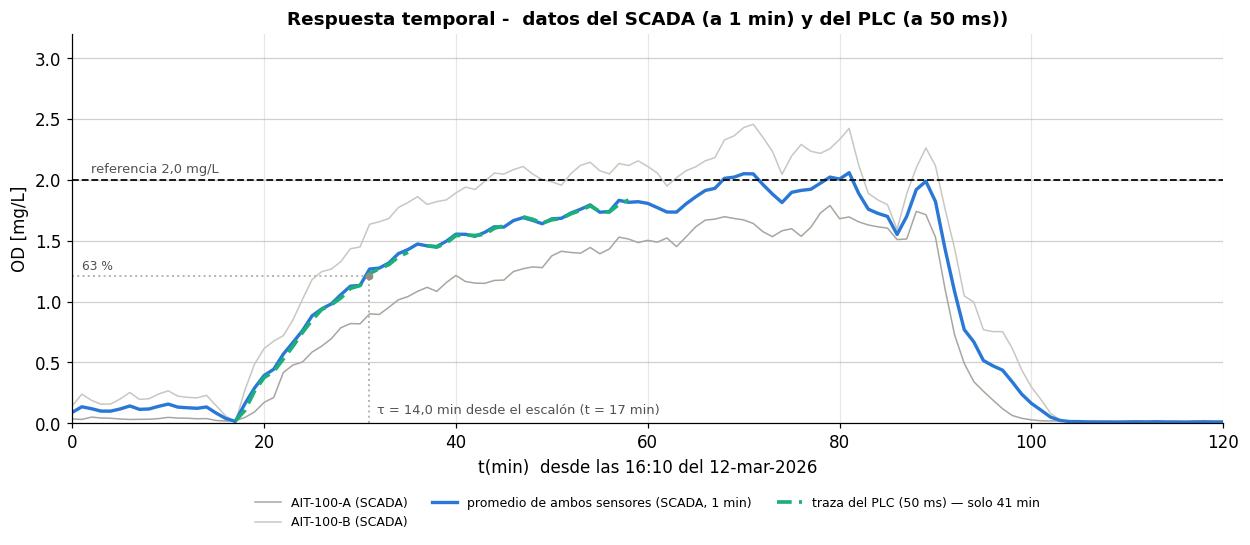

In [29]:
fig, ax = plt.subplots(figsize=(13.5, 4.6))
w2 = d.loc['2026-03-12 16:10':'2026-03-12 18:10', ['M1_od1','M1_od2','M1_od']]
t2 = np.arange(len(w2), dtype=float)
ax.plot(t2, w2.M1_od1, lw=1, color=GRIS, label='AIT-100-A (SCADA)')
ax.plot(t2, w2.M1_od2, lw=1, color='#c9c7c0', label='AIT-100-B (SCADA)')
ax.plot(t2, w2.M1_od, lw=2.2, color=COL['M2'], label='promedio de ambos sensores (SCADA, 1 min)')
tc = (cm.index - w2.index[0]).total_seconds().to_numpy()/60
ax.plot(tc, cm.OxigenoPromedio, lw=2.4, ls=(0, (4, 2)), color=VERDE,
        label='traza del PLC (50 ms) — solo 41 min')

# constante de tiempo de la subida (ajuste de primer orden de la celda anterior)
y0_s, dy_s, tau_s, th_s = AJ['subida']['p']
t_ini = (AJ['subida']['t0'] - w2.index[0]).total_seconds()/60 + th_s
t_tau, y63 = t_ini + tau_s, y0_s + (1 - np.exp(-1))*dy_s
GRIS_CL = '#b8b6af'
ax.plot([t_tau, t_tau], [0, y63], color=GRIS_CL, lw=1.3, ls=':')   # vertical hasta la curva
ax.plot([0, t_tau], [y63, y63], color=GRIS_CL, lw=1.3, ls=':')       # horizontal hasta la curva
ax.plot(t_tau, y63, 'o', ms=4, color='#8f8d86')
ax.text(t_tau + 0.8, 0.08, 'τ = %s min desde el escalón (t = %.0f min)'
        % (('%.1f' % tau_s).replace('.', ','), t_ini), fontsize=8.5, color='#52514e')
ax.text(1, y63 + 0.05, '63 %', fontsize=8, color='#52514e')

ax.axhline(2.0, color='#0b0b0b', lw=1.2, ls='--')
ax.text(2, 2.06, 'referencia 2,0 mg/L', fontsize=8.5, color='#52514e')

ax.set(xlabel='t(min)  desde las 16:10 del 12-mar-2026', ylabel='OD [mg/L]',
       xlim=(0, len(w2)-1), ylim=(0, 3.2),
       title='Respuesta temporal -  datos del SCADA (a 1 min) y del PLC (a 50 ms))')
ax.legend(frameon=False, fontsize=8.2, ncol=3, loc='lower center',
          bbox_to_anchor=(.5, -.30))
ax.grid(axis='y', alpha=.6); ax.set_axisbelow(True)

fig.savefig('../../Latex/Tesis/figuras/ident_15_ensayo_scada.pdf', bbox_inches='tight')
plt.show()

**Esa tarde hubo cuatro ciclos completos** de subida y bajada, entre las 14:00 y
las 23:30 — el ctrlX solo guardó 41 minutos de uno de ellos:

| Subida | Caída |
|---|---|
| ~14:50 | 15:50 |
| **16:20** | **17:45** ← la del ctrlX |
| 18:30 | 21:05 |
| 21:50 | 22:10 |

Los cuatro son escalones utilizables a 1 min con los dos sensores. **Triplica el
material de ese día** para medir τ y la respiración.

> **Pero solo el segundo sirve para `b₀`.** Los 41 min del ctrlX son el único
> tramo de toda la tarde donde se sabe qué mandó el PLC; en los otros tres hay
> respuesta pero no entrada.

## 10.4 El mismo escalón, pero asentando en 3 mg/L

El ensayo del 12 de marzo asienta en **1,90 mg/L**. Si `K ∝ OD` (§5), un escalón
equivalente que asiente más alto tiene que dar una ganancia mayor **en la misma
proporción**. Se puede comprobar con un solo par de escalones, sin ARX de por
medio.

Buscando en el histórico un arranque parecido —soplador de 0 a casi plena carga,
partiendo del suelo— aparece **M2, 16-abr-2025 01:19**, que asienta en 3,06 mg/L.
Y esa madrugada hay **dos ciclos idénticos** (01:19 y 04:20), así que es
repetible.

In [30]:
import actuador
CAD_M2 = actuador.Cadena(20.6, 48.0, 64.0, 106.3)   # piso · 1 sopl. máx · reentrada · techo

w4 = d.loc['2025-04-16 01:15':'2025-04-16 03:20', ['M2_od','M2_pot']].dropna()
y4, P4, idx4 = w4.M2_od.to_numpy(), w4.M2_pot.to_numpy(), w4.index
on = P4 > 5
k_on, k_off = int(np.flatnonzero(on)[0]), int(np.flatnonzero(on)[-1])
U4 = float(np.median(CAD_M2.u(P4[on])))        # consigna RECONSTRUIDA de la potencia

AJ4 = {}
for nom, a, b, sgn in (('subida', k_on, k_off, +1), ('bajada', k_off, len(y4)-1, -1)):
    t = np.arange(b-a+1, dtype=float); vv = y4[a:b+1]
    lo = [-1, 0, 1, 0]   if sgn > 0 else [-1, -10, 1, 0]
    hi = [5, 10, 150, 40] if sgn > 0 else [5, 0, 150, 40]
    p, _ = curve_fit(foptd, t, vv, p0=[vv[0], vv[-1]-vv[0], 20, 1],
                     bounds=(lo, hi), maxfev=60000)
    AJ4[nom] = dict(p=p, t=t, v=vv, t0=idx4[a], t1=idx4[b],
        r2=1-((vv-foptd(t,*p))**2).sum()/((vv-vv.mean())**2).sum(),
        rmse=np.sqrt(((vv-foptd(t,*p))**2).mean()),
        pend5=np.polyfit(t[:6], vv[:6], 1)[0]*60,
        K=p[1]/U4, b0=(p[1]/U4)/(p[2]/60))

print('M2, 16-abr-2025 · soplador ON %s → OFF %s'
      % (idx4[k_on].strftime('%H:%M'), idx4[k_off].strftime('%H:%M')))
print('potencia %.0f %% de plena carga  →  consigna RECONSTRUIDA %.1f %%\n'
      % (100*np.median(P4[on])/106.3, U4))
r = AJ4['subida']
print('SUBIDA   tau %.1f min · retardo %.0f s · dy %+.3f · R2 %.4f · RMSE %.3f'
      % (r['p'][2], r['p'][3]*60, r['p'][1], r['r2'], r['rmse']))
print('         estacionario %.2f mg/L' % (r['p'][0]+r['p'][1]))
print('         K  = dy/du     = %+.3f / %.1f  = %.5f mg/L por punto de consigna'
      % (r['p'][1], U4, r['K']))
print('         b0 = K/tau[h]  = %.5f / (%.1f/60) = %.4f mg/L/(%%·h)'
      % (r['K'], r['p'][2], r['b0']))
rb = AJ4['bajada']
print('BAJADA   tau %.1f min · R2 %.4f · pendiente inicial %.1f mg/(L·h)  (la respiración)'
      % (rb['p'][2], rb['r2'], -rb['pend5']))

M2, 16-abr-2025 · soplador ON 01:19 → OFF 02:50
potencia 92 % de plena carga  →  consigna RECONSTRUIDA 92.8 %

SUBIDA   tau 18.8 min · retardo 51 s · dy +2.868 · R2 0.9976 · RMSE 0.037
         estacionario 3.06 mg/L
         K  = dy/du     = +2.868 / 92.8  = 0.03092 mg/L por punto de consigna
         b0 = K/tau[h]  = 0.03092 / (18.8/60) = 0.0984 mg/L/(%·h)
BAJADA   tau 5.3 min · R2 0.9870 · pendiente inicial 10.8 mg/(L·h)  (la respiración)


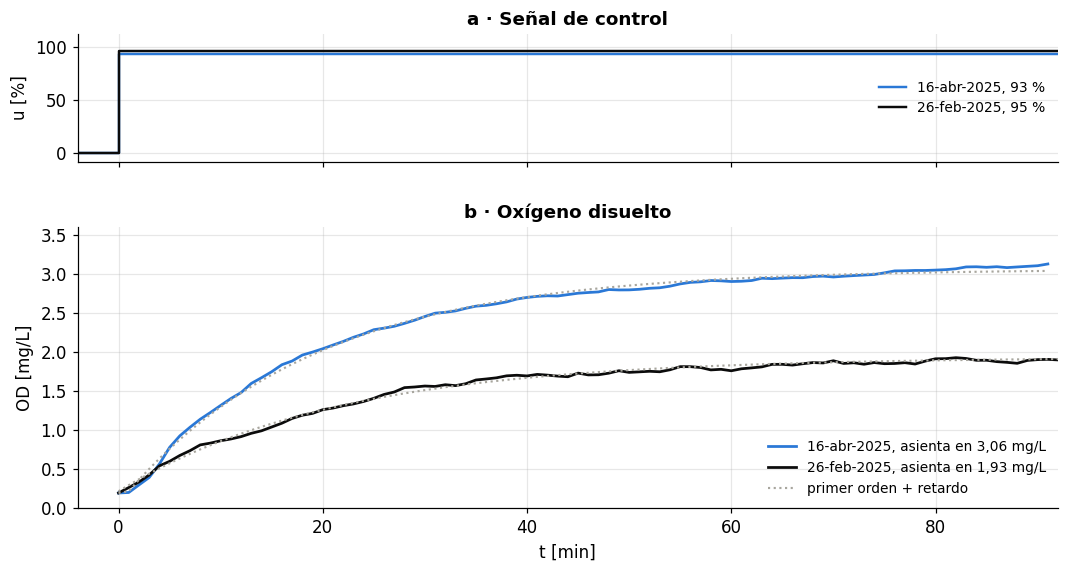

M2, 26-feb-2025 · ON 08:36 · potencia 101 kW → consigna reconstruida 95.5 %
   tau 21.4 min · retardo 0 s · dy +1.717 · estacionario 1.93 mg/L · K 0.01798 · R2 0.9936
16-abr frente a 26-feb: estacionario x1.58 · K x1.72 · tau 18.8 frente a 21.4 min


In [31]:
# c) el mismo modulo y la misma potencia, otro dia: M2 el 26-feb-2025, ajustado igual que el 16-abr
w26 = d.loc['2025-02-26 08:00':'2025-02-26 11:30', ['M2_od', 'M2_pot']].dropna()
on26 = w26.M2_pot.to_numpy() > 5
k26 = int(np.flatnonzero(on26)[0]); f26 = k26 + int(np.argmax(~on26[k26:]))
y26 = w26.M2_od.to_numpy()[k26:f26 + 1]; t26 = np.arange(len(y26), dtype=float)
p26, _ = curve_fit(foptd, t26, y26, p0=[y26[0], y26[-1] - y26[0], 20, 1],
                   bounds=([-1, 0, 1, 0], [5, 10, 150, 40]), maxfev=60000)
U26 = float(np.median(CAD_M2.u(w26.M2_pot.to_numpy()[k26:f26])))
r2_26 = 1 - ((y26 - foptd(t26, *p26))**2).sum() / ((y26 - y26.mean())**2).sum()
EST4, EST26 = AJ4['subida']['p'][0] + AJ4['subida']['p'][1], p26[0] + p26[1]
coma = lambda v: ('%.2f' % v).replace('.', ',')

r = AJ4['subida']
fig, ax, bx = figura_escalon(None, 'Señal de control')
ax.step([-4, 0, 92], [0, U4, U4], where='post', lw=1.6, color=AZUL, label='16-abr-2025, %.0f %%' % U4)
ax.step([-4, 0, 92], [0, U26, U26], where='post', lw=1.6, color=NEGRO, label='26-feb-2025, %.0f %%' % U26)
ax.set(ylim=(-8, 112), xlim=(-4, 92), ylabel='u [%]', yticks=[0, 50, 100])
ax.legend(frameon=False, fontsize=9, loc='center right')
bx.plot(r['t'], r['v'], lw=1.8, color=AZUL, label='16-abr-2025, asienta en %s mg/L' % coma(EST4))
bx.plot(t26, y26, lw=1.8, color=NEGRO, label='26-feb-2025, asienta en %s mg/L' % coma(EST26))
bx.plot(r['t'], foptd(r['t'], *r['p']), lw=1.4, ls=':', color=GRIS)
bx.plot(t26, foptd(t26, *p26), lw=1.4, ls=':', color=GRIS, label='primer orden + retardo')
bx.set(xlabel='t [min]', ylabel='OD [mg/L]', ylim=(0, 3.6))
bx.legend(frameon=False, fontsize=9, loc='lower right')
fig.savefig('../../Latex/Tesis/figuras/ident_16_escalon_3mgL.pdf', bbox_inches='tight'); plt.show()

print('M2, 26-feb-2025 · ON %s · potencia %.0f kW → consigna reconstruida %.1f %%'
      % (w26.index[k26].strftime('%H:%M'), np.median(w26.M2_pot.to_numpy()[k26:f26]), U26))
print('   tau %.1f min · retardo %.0f s · dy %+.3f · estacionario %.2f mg/L · K %.5f · R2 %.4f'
      % (p26[2], p26[3]*60, p26[1], EST26, p26[1]/U26, r2_26))
print('16-abr frente a 26-feb: estacionario x%.2f · K x%.2f · tau %.1f frente a %.1f min'
      % (EST4/EST26, AJ4['subida']['K']/(p26[1]/U26), AJ4['subida']['p'][2], p26[2]))


### La comprobación

| | 12-mar-2026 · M1 | 16-abr-2025 · M2 |
|---|---|---|
| Escalón de entrada | 0 → 95 % (**medido**) | 0 → 93 % (**reconstruido**) |
| **Estacionario** | 1,90 mg/L | **3,06 mg/L** |
| τ subida | 14,0 min | **18,8 min** |
| **K** | 0,0198 /%cmd | **0,0309** /%cmd |
| b₀ | 0,0849 | 0,0984 mg/L/(%·h) |
| R² | 0,9688 | **0,9976** · RMSE 0,037 |
| τ bajada | 4,1 min | 5,3 min |
| Respiración | 15,7 mg/(L·h) | 10,8 mg/(L·h) |

**Razón de estacionarios 1,61 · razón de ganancias 1,56.** Es `K ∝ OD`
confirmado con dos escalones sueltos, cada uno con su propio ajuste, sin que
intervenga la regresión ARX en ningún punto.

Y se ve en la **forma** de las curvas del panel c: la azul no es la verde
escalada en amplitud — es **más lenta además de más alta** (τ 18,8 contra 14,0).
Ganancia y constante de tiempo suben juntas, que es exactamente lo que dice la
figura de §5 al pasar del tramo «0,5–1,5» al de «1,5–3».

> **Dos avisos.** La consigna de M2 es **reconstruida** (M2 registra potencia, no
> consigna); la de M1 era **medida**, de la traza del ctrlX. Y son **módulos
> distintos**: comparables por ser gemelos —mismo diseño, mismo techo de
> tablero— pero no el mismo equipo.

---
# 11. Cómo se obtiene `f(t)` de los datos de Tunja

Hasta aquí `f` ha aparecido como un número agregado. El ADRC no necesita un modelo de la planta: necesita `b₀` y un observador que siga a `f`. Esta sección la construye **como señal en el tiempo**, que es lo que hace falta para simular y para elegir `ω_o`.

Hay dos caminos y los dos están medidos:

**Camino directo — invertir la ecuación del ADRC.** De `ẏ = f + b₀u`,

$$f(t) = \dot y(t) - b_0\,u(t)$$

con `ẏ` de la derivada centrada del OD, sin filtro, `ẏ[k] = (y[k+1] − y[k−1])/(2·Ts)`,
y `u` de la potencia medida. Da `f`
a 1 min. Es exactamente lo que el ESO va a estimar.

**Camino del barrido — el de §3.** Cada ventana ARX devuelve `δ` y `φ`, y de ahí
`f` evaluada en el punto de consigna: `f2 = c_h − a_h·2,0`. Da un valor cada
hora, más robusto porque no deriva la señal.

Los dos coinciden en lo que importa: mediana −8,5 (M2) y −5,9 (M3) mg/(L·h),
ciclo diario de 2,5–2,8 y deriva mensual de 7–9. **Se usa el segundo** para las
piezas del modelo, y el primero como comprobación.

### El modelo de perturbación que sale de ahí

$$f(t)=\underbrace{f_0}_{\text{nivel}}+\underbrace{\frac{df}{dQ}\big(Q(t)-\bar Q\big)}_{\text{ciclo diario, PREDECIBLE}}+\underbrace{m(t)}_{\text{deriva mensual}}+\underbrace{\xi(t)}_{\text{residuo, }\tau_f}$$

Todas las piezas están medidas, ninguna ajustada a ojo. `ξ` es un
Ornstein-Uhlenbeck con la constante de tiempo medida de `f` (78 min en M2,
149 en M3): el residuo **no es ruido blanco**, está correlacionado a una o dos
horas, y eso cambia lo que el observador puede hacer con él.

> **Un matiz que cambia lo que se puede prometer con prealimentación.** El ciclo
> diario es real, pero **existe en el promedio de 24 h, no en cada hora**: la
> correlación entre `f` y el caudal vale −0,68 sobre el perfil promediado y ~0,13
> hora a hora (§2.2 de `analisis_dinamica.ipynb`). Tanto es así que restar `a·(Q−Q̄)` de cada ventana
> individual **aumenta** la varianza un 57 % en M2 y un 85 % en M3. Así que la
> componente periódica es legítima como comportamiento medio —y por eso entra en
> el generador— pero **una prealimentación por caudal sólo puede quitar esa
> fracción media**, no la dispersión ventana a ventana, que es mayor.

> **Y una advertencia sobre la componente diaria del generador.** Es la pieza
> **peor sostenida** del modelo: §14.2b de `analisis_dinamica.ipynb` muestra que las dos rutas de cálculo de `f`
> ni siquiera coinciden en el signo de la correlación con el caudal. El nivel y la
> dispersión de `f` sí son robustos; el ciclo de 24 h descansa en el emparejamiento
> ventana-caudal de §10 de `analisis_dinamica.ipynb`. Para el barrido de robustez conviene simular **con y sin**
> esa componente (`con_deriva`, y poniendo `DFDQ` a cero) y comprobar que la
> conclusión no depende de ella.

pieza de f                               M2         M3
nivel f0 en y=2 [mg/(L·h)]            -8.49      -5.52
ciclo diario medido, p-p               3.46       2.34
df/dQ [mg/(L·h) por L/s]            -0.1108    -0.0189
correlación perfil f - perfil Q       -0.42      -0.06
vaivén diario del caudal [L/s]          9.4        7.3
parte del ciclo por el caudal          1.04       0.14
nivel del mes más bajo               -10.24      -6.77
nivel del mes más alto                -7.22      -0.48
cambio entre meses                     3.02       6.29
σ robusta de f entera                  4.07       3.19
σ robusta del residuo                  3.75       3.15
τ_f del residuo [min]                    58        139
b₀ de diseño                          0.150      0.179
b₀ medido, OD 1,5-3: mediana          0.134      0.179
b₀ medido, OD 1,5-3: Q1               0.103      0.091
b₀ medido, OD 1,5-3: Q3               0.170      0.243
τ en la consigna [h]                   0.31       0.43

M2 en pun

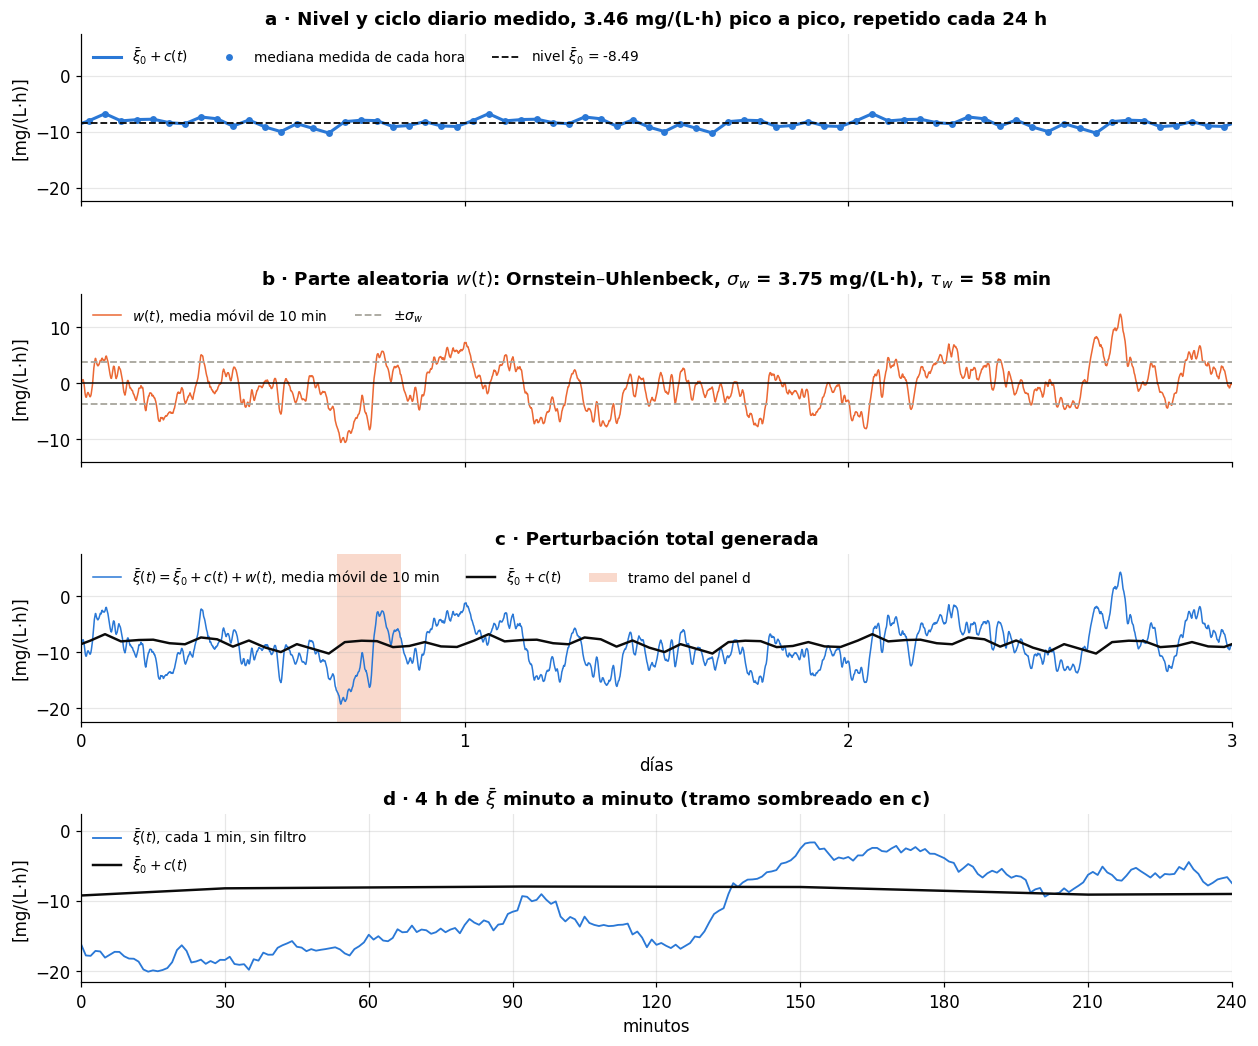

en 3 días: f va de -20.1 a 5.5; f0 + c(t) de -10.3 a -6.8; desviación de ξ 3.84 (σ del modelo 3.75) mg/(L·h)
panel d · sin filtro: -16.3 en el minuto 120 y -2.6 en el 150 → cambio 13.7 mg/(L·h) = 91 puntos de u (b0 = 0.15)
panel d · |Δf| entre minutos, sin filtro: mediana 0.46, p95 1.37 mg/(L·h)
escenarios de nivel: -10.24 (mes más bajo) y -7.22 (mes más alto)


In [32]:
import perturbacion as PT

PZ = {m: PT.medir(m, T=T, h=h) for m in ('M2','M3')}
FIL = [('nivel f0 en y=2 [mg/(L·h)]','f0','%+.2f'),
       ('ciclo diario medido, p-p','amp_ciclo','%.2f'),
       ('df/dQ [mg/(L·h) por L/s]','dfdQ','%+.4f'),
       ('correlación perfil f - perfil Q','corr_fQ','%+.2f'),
       ('vaivén diario del caudal [L/s]','vaiven_Q','%.1f'),
       ('parte del ciclo por el caudal','amp_caudal','%.2f'),
       ('nivel del mes más bajo','f_mes_min','%+.2f'),
       ('nivel del mes más alto','f_mes_max','%+.2f'),
       ('cambio entre meses','cambio_mes','%.2f'),
       ('σ robusta de f entera','sigma_f','%.2f'),
       ('σ robusta del residuo','sigma_res','%.2f'),
       ('τ_f del residuo [min]','tau_f_min','%.0f'),
       ('b₀ de diseño','b0','%.3f'),
       ('b₀ medido, OD 1,5-3: mediana','b0_medido','%.3f'),
       ('b₀ medido, OD 1,5-3: Q1','b0_q25','%.3f'),
       ('b₀ medido, OD 1,5-3: Q3','b0_q75','%.3f'),
       ('τ en la consigna [h]','tau_consigna_h','%.2f')]
print('%-32s %10s %10s' % ('pieza de f','M2','M3'))
for nom, k, fmt in FIL:
    print('%-32s %10s %10s' % (nom, fmt % PZ['M2'][k], fmt % PZ['M3'][k]))
z = PZ['M2']
print('\nM2 en puntos de señal de control (Δu = Δf/b₀) y en desvío de OD (Δf·τ):')
for nom, k in (('ciclo diario medido', 'amp_ciclo'), ('parte por el caudal', 'amp_caudal'),
               ('cambio entre meses', 'cambio_mes'), ('σ del residuo (±)', 'sigma_res')):
    print('  %-22s %5.2f mg/(L·h) = %3.0f pts = %.2f mg/L' % (nom, z[k], z[k]/z['b0'], z[k]*z['tau_consigna_h']))

# --- la figura: las piezas de f, su suma y un tramo de pocas horas
# semilla 0: son los 3 primeros dias de f_generada_M2_14d_1min.csv, la que usan las
# simulaciones de los controladores (exporta_perturbacion.py). Las simulaciones la usan
# SIN filtro; la media movil de 10 min de los paneles b y c es solo para verla.
DIAS_F, SPAN = 3, (-14, 16)                     # mismo alto en a, b y c: se comparan a ojo
ZOOM = (16, 20)                                 # h: el tramo con el cambio mas rapido de f
fs = PT.generar('M2', dias=DIAS_F, dt_min=1.0, semilla=0, z=PZ['M2'])
fc = PT.generar('M2', dias=DIAS_F, dt_min=1.0, semilla=0, z=PZ['M2'], con_residuo=False)   # f0 + c(t)
xi = fs - fc                                                                               # parte aleatoria
m10 = lambda x: x.rolling(10, center=True, min_periods=1).mean()                           # solo para ver
t  = fs.index.to_numpy()/24                                                                # dias
F0, SG = PZ['M2']['f0'], PZ['M2']['sigma_res']
fig = plt.figure(figsize=(13.5, 11.2))
gs = fig.add_gridspec(4, 1, hspace=.55)
axf = [fig.add_subplot(gs[0])]
axf += [fig.add_subplot(gs[k], sharex=axf[0]) for k in (1, 2)] + [fig.add_subplot(gs[3])]

ax = axf[0]
th = np.concatenate([k*24 + np.arange(24) + .5 for k in range(DIAS_F)])/24   # centro de cada hora
ax.plot(t, fc.to_numpy(), lw=2, color=AZUL, label=r'$\bar{\xi}_0 + c(t)$')
ax.plot(th, F0 + np.tile(PZ['M2']['ciclo'].to_numpy(), DIAS_F), 'o', ms=3.5, color=AZUL,
        label='mediana medida de cada hora')
ax.axhline(F0, color='#0b0b0b', lw=1.2, ls='--', label=r'nivel $\bar{\xi}_0$ = %.2f' % F0)
ax.set(ylabel='[mg/(L·h)]', ylim=(F0 + SPAN[0], F0 + SPAN[1]),
       title='a · Nivel y ciclo diario medido, %.2f mg/(L·h) pico a pico, repetido cada 24 h' % PZ['M2']['amp_ciclo'])
ax.legend(frameon=False, fontsize=9, ncol=3, loc='upper left')

ax = axf[1]
ax.plot(t, m10(xi).to_numpy(), lw=1, color=NARANJA, label=r'$w(t)$, media móvil de 10 min')
ax.axhline(0, color='#0b0b0b', lw=1)
ax.axhline(SG, color=GRIS, lw=1.2, ls='--', label=r'$\pm\sigma_w$')
ax.axhline(-SG, color=GRIS, lw=1.2, ls='--')
ax.set(ylabel='[mg/(L·h)]', ylim=SPAN,
       title=r'b · Parte aleatoria $w(t)$: Ornstein–Uhlenbeck, $\sigma_w$ = %.2f mg/(L·h), $\tau_w$ = %.0f min'
       % (SG, PZ['M2']['tau_f_min']))
ax.legend(frameon=False, fontsize=9, ncol=2, loc='upper left')

ax = axf[2]
ax.plot(t, m10(fs).to_numpy(), lw=1, color=AZUL, label=r'$\bar{\xi}(t) = \bar{\xi}_0 + c(t) + w(t)$, media móvil de 10 min')
ax.plot(t, fc.to_numpy(), lw=1.6, color='#0b0b0b', label=r'$\bar{\xi}_0 + c(t)$')
ax.axvspan(ZOOM[0]/24, ZOOM[1]/24, color=NARANJA, alpha=.25, lw=0, label='tramo del panel d')
ax.set(xlabel='días', ylabel='[mg/(L·h)]', ylim=(F0 + SPAN[0], F0 + SPAN[1]),
       xlim=(0, DIAS_F), xticks=range(DIAS_F + 1), title='c · Perturbación total generada')
ax.legend(frameon=False, fontsize=9, ncol=3, loc='upper left')
for ax in axf[:2]:
    plt.setp(ax.get_xticklabels(), visible=False)

# d) el tramo, minuto a minuto: lo que el lazo tiene que rechazar
ax = axf[3]
sel = (fs.index >= ZOOM[0]) & (fs.index <= ZOOM[1])
tz = (fs.index[sel].to_numpy() - ZOOM[0])*60                    # minutos desde el inicio del tramo
ax.plot(tz, fs[sel].to_numpy(), lw=1.2, color=AZUL, label=r'$\bar{\xi}(t)$, cada 1 min, sin filtro')
ax.plot(tz, fc[sel].to_numpy(), lw=1.6, color='#0b0b0b', label=r'$\bar{\xi}_0 + c(t)$')
ax.set(xlabel='minutos', ylabel='[mg/(L·h)]', xlim=(0, 60*(ZOOM[1] - ZOOM[0])),
       xticks=range(0, 60*(ZOOM[1] - ZOOM[0]) + 1, 30),
       ylim=(fs[sel].min() - 1.5, fs[sel].max() + 4),
       title=r'd · %d h de $\bar{\xi}$ minuto a minuto (tramo sombreado en c)' % (ZOOM[1] - ZOOM[0]))
ax.legend(frameon=False, fontsize=9, loc='upper left')
fig.savefig('../../Latex/Tesis/figuras/ident_17_perturbacion.pdf', bbox_inches='tight')
plt.show()
print('en %d días: f va de %.1f a %.1f; f0 + c(t) de %.1f a %.1f; desviación de ξ %.2f (σ del modelo %.2f) mg/(L·h)'
      % (DIAS_F, fs.min(), fs.max(), fc.min(), fc.max(), xi.std(), SG))
a18, b18 = fs.loc[18.0], fs.loc[18.5]
print('panel d · sin filtro: %.1f en el minuto 120 y %.1f en el 150 → cambio %.1f mg/(L·h) = %.0f puntos de u (b0 = %.2f)'
      % (a18, b18, b18 - a18, (b18 - a18)/PZ['M2']['b0'], PZ['M2']['b0']))
print('panel d · |Δf| entre minutos, sin filtro: mediana %.2f, p95 %.2f mg/(L·h)'
      % (fs[sel].diff().abs().median(), fs[sel].diff().abs().quantile(.95)))
print('escenarios de nivel: %.2f (mes más bajo) y %.2f (mes más alto)' % (PZ['M2']['f_mes_min'], PZ['M2']['f_mes_max']))

### El espectro de `f`, para ubicar `ω_o`

El observador tiene que **seguir** a `f`: su ancho de banda `ω_o` debe quedar por
encima de las frecuencias donde `f` tiene su energía. Aquí se calcula el espectro
de `f` **sin ningún filtro** (la f sintética a 1 min, 28 días, la misma que entra a
las simulaciones) con el método de Welch (FFT promediada en segmentos de 4.096
min ≈ 2,8 días, ventana de Hann).

El eje de frecuencia va en **rad/h**, las mismas unidades de `ω_o`
(ω = 2π·f·3600). El límite derecho es el Nyquist del muestreo de 1 min, 188 rad/h.

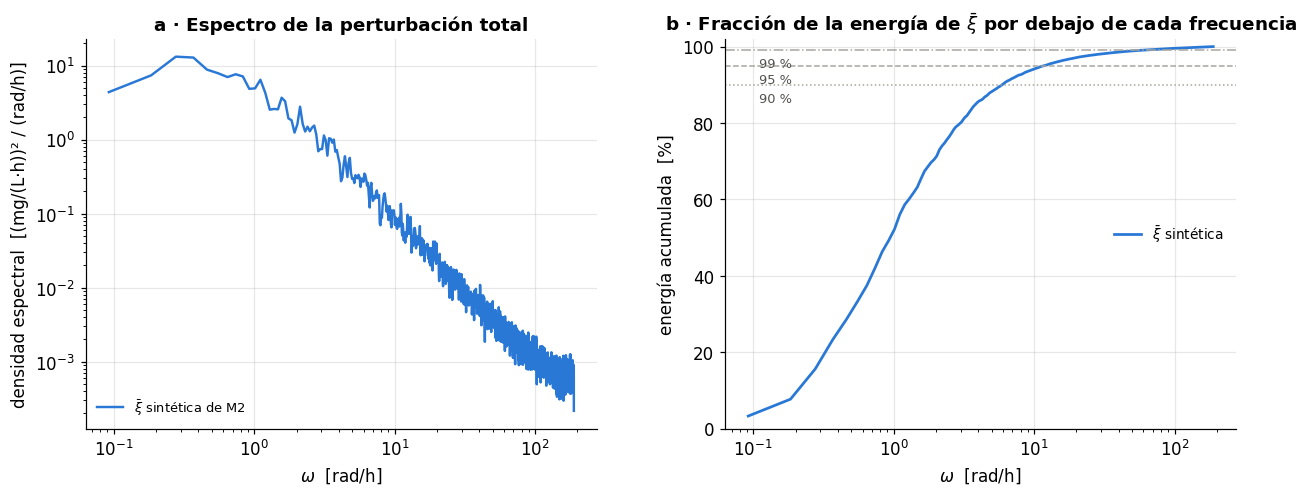

omega [rad/h] por debajo de la cual queda cada fraccion de la energia de f:
                   50 %     90 %     95 %     99 %
f sintética        1.01     5.98    11.78    55.78
1/tau_f de M2 = 1.03 rad/h  ·  Nyquist de 1 min = 188 rad/h


In [33]:
from scipy.signal import welch
FS_HZ = 1/60.0                                         # 1 muestra por minuto
fsint = PT.generar('M2', dias=28, dt_min=1.0, semilla=3).to_numpy()   # SIN filtro
fq, Psint = welch(fsint - fsint.mean(), fs=FS_HZ, nperseg=4096)
W = 2*np.pi*fq*3600                                    # rad/h, unidades de omega_o
HZ_A_RADH = 2*np.pi*3600                               # 1 Hz = 2*pi*3600 rad/h

def w_energia(P, q):                                   # omega bajo la cual queda la fraccion q
    c = np.cumsum(P)/np.sum(P); return W[np.searchsorted(c, q)]
TAU_F_M2 = PZ['M2']['tau_f_min']/60                    # h
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={'wspace': .25})
a = ax[0]
a.loglog(W[1:], Psint[1:]/HZ_A_RADH, lw=1.6, color=AZUL, label=r'$\bar{\xi}$ sintética de M2')
a.set(xlabel=r'$\omega$  [rad/h]', ylabel='densidad espectral  [(mg/(L·h))² / (rad/h)]',
      title='a · Espectro de la perturbación total')
a.legend(frameon=False, fontsize=8.5, loc='lower left')
a = ax[1]
for P, col, lab in ((Psint, AZUL, r'$\bar{\xi}$ sintética'),):
    a.semilogx(W[1:], 100*np.cumsum(P)[1:]/np.sum(P), lw=1.8, color=col, label=lab)
for q, ls in ((.90, ':'), (.95, '--'), (.99, '-.')):
    a.axhline(100*q, color=GRIS, lw=1, ls=ls)
    a.text(W[1]*1.2, 100*q-4.5, '%d %%' % (100*q), fontsize=8.5, color='#52514e')
a.set(xlabel=r'$\omega$  [rad/h]', ylabel='energía acumulada  [%]', ylim=(0, 102),
      title=r'b · Fracción de la energía de $\bar{\xi}$ por debajo de cada frecuencia')
a.legend(frameon=False, fontsize=9, loc='center right')
fig.savefig('../../Latex/Tesis/figuras/ident_19_espectro_f.pdf', bbox_inches='tight')
plt.show()

print('omega [rad/h] por debajo de la cual queda cada fraccion de la energia de f:')
print('%-14s %8s %8s %8s %8s' % ('', '50 %', '90 %', '95 %', '99 %'))
for lab, P in (('f sintética', Psint),):
    print('%-14s %8.2f %8.2f %8.2f %8.2f' % (lab, *(w_energia(P, q) for q in (.5, .9, .95, .99))))
print('1/tau_f de M2 = %.2f rad/h  ·  Nyquist de 1 min = %.0f rad/h' % (1/TAU_F_M2, W[-1]))

---
# 12. El ruido del sensor, medido a 50 ms

El σ de ruido que se ha venido usando (0,033 mg/L en M2, 0,459 en M3) sale del
**historiador a 1 min**: `std(diff(OD))/√2`. Ese estimador supone que el ruido es
blanco y que la planta no se mueve de una muestra a la siguiente. A 1 min la
segunda suposición es dudosa: en un minuto el proceso sí se mueve, y lo que se
mide mezcla ruido del sensor con variación real.

**Con la traza del ctrlX a 50 ms se puede separar.** Se buscan tramos donde la
consigna del soplador esté **quieta** y el oxígeno casi plano, y ahí se mide:

1. **σ a 50 ms** — `std(diff)/√2` sobre la señal cruda, muestra a muestra;
2. **el mismo estimador remuestreando** la misma señal a 1 s, 10 s y 1 min (media
   por intervalo, como haría un historiador que promedia): si el ruido fuera
   blanco, σ **bajaría** al promediar; si sube, lo que crece es variación lenta;
3. **el espectro** (Welch, 20 Hz, segmentos de 4.096 muestras ≈ 205 s), para ver
   en qué frecuencias vive la fluctuación y cuáles puede ver cada muestreo.

**Tramo usado: una sola medida, el ensayo del 12-mar-2026** (`data2/`, M1, el
único módulo con traza a 50 ms en planta). Toda la traza es un escalón con la
consigna del soplador fija en 95 %; el tramo quieto son sus **últimos 10 min**
(minutos 31 a 41), cerca de la asíntota (OD ≈ 1,7 mg/L), con 12.000 muestras.

El OD todavía sube despacio en ese tramo, pero `std(diff)` no ve una tendencia
lenta: solo mide el salto de una muestra a la siguiente.


In [34]:
from scipy.signal import welch

# --- una sola medida: el ensayo del 12-mar-2026 (data2), sus ultimos 10 min
import ensayos
_d2 = ensayos.cargar('data2')
_tf = _d2.index.max()
TRAMO = {'12-mar-2026, últimos 10 min': _d2.loc[_tf - 600 :]}
SENS  = {'Oxigeno_1': 'AIT-100-A', 'Oxigeno_2': 'AIT-100-B', 'OxigenoPromedio': 'promedio de ambos sensores'}
PER   = {'50 ms': None, '1 s': '1s', '10 s': '10s', '1 min': '1min'}

def sigma_diff(x):
    x = x.dropna(); return x.diff().dropna().std() / np.sqrt(2)

filas = []
for nom, g in TRAMO.items():
    for c, lab in SENS.items():
        x = g[c].copy(); x.index = pd.to_timedelta(x.index, unit='s')
        fila = dict(tramo=nom, senal=lab, n=len(x),
                    OD_medio=x.mean(), paso_cuantizacion=np.diff(np.unique(x.round(6))).min())
        for p, regla in PER.items():
            fila['σ ' + p] = sigma_diff(x if regla is None else x.resample(regla).mean())
        r = (x - x.rolling(100, center=True, min_periods=20).mean()).dropna().to_numpy()
        fila['acf 1 paso'] = np.corrcoef(r[:-1], r[1:])[0, 1]
        filas.append(fila)
RUIDO = pd.DataFrame(filas)
SIG_SCADA = {}
for m in ('M1', 'M2', 'M3'):
    dd_ = d[m+'_od'].dropna().diff().dropna(); dd_ = dd_[dd_.abs() < dd_.abs().quantile(.99)]
    SIG_SCADA[m] = dd_.std() / np.sqrt(2)

prom = RUIDO[RUIDO.senal == 'promedio de ambos sensores']
TABLA_RUIDO = pd.DataFrame([
    dict(Módulo='M1', Fuente='PLC ctrlX (traza)', Muestreo='50 ms',
         Datos='ensayo 12-mar-2026, últimos 10 min, %d muestras' % prom.n.sum(),
         **{'σ [mg/L]': prom['σ 50 ms'].mean()}),
    dict(Módulo='M2', Fuente='SCADA (historiador)', Muestreo='1 min', Datos='todo el registro',
         **{'σ [mg/L]': SIG_SCADA['M2']}),
    dict(Módulo='M3', Fuente='SCADA (historiador)', Muestreo='1 min', Datos='todo el registro',
         **{'σ [mg/L]': SIG_SCADA['M3']}),
    dict(Módulo='M1 (referencia)', Fuente='SCADA (historiador)', Muestreo='1 min', Datos='todo el registro',
         **{'σ [mg/L]': SIG_SCADA['M1']}),
]).set_index('Módulo')
print('σ = std(diff)/√2 del OD promedio del PLC  ·  en el SCADA se recorta el 1 % de saltos más grandes')
print('la misma traza de M1 promediada: 1 s %.4f · 10 s %.4f · 1 min %.4f mg/L'
      % tuple(prom['σ ' + p_].mean() for p_ in ('1 s', '10 s', '1 min')))
TABLA_RUIDO.style.format({'σ [mg/L]': '{:.4f}'})


σ = std(diff)/√2 del OD promedio del PLC  ·  en el SCADA se recorta el 1 % de saltos más grandes
la misma traza de M1 promediada: 1 s 0.0008 · 10 s 0.0059 · 1 min 0.0241 mg/L


,Fuente,Muestreo,Datos,σ [mg/L]
Módulo,,,,
M1,PLC ctrlX (traza),50 ms,"ensayo 12-mar-2026, últimos 10 min, 11999 muestras",0.0011
M2,SCADA (historiador),1 min,todo el registro,0.0326
M3,SCADA (historiador),1 min,todo el registro,0.4589
M1 (referencia),SCADA (historiador),1 min,todo el registro,0.0242


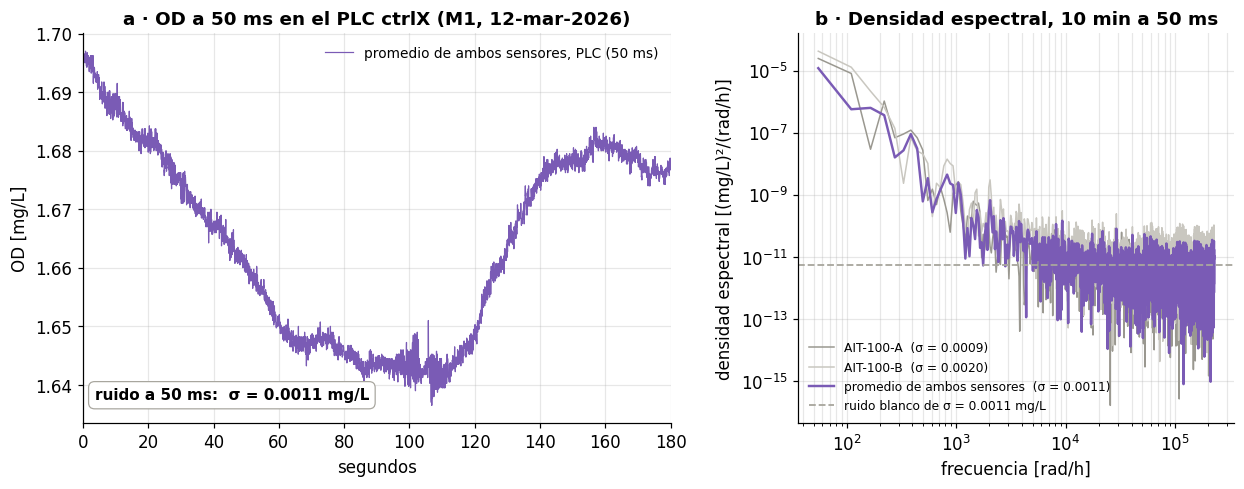

In [35]:
fig, (a, a2) = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={'width_ratios': [1.35, 1], 'wspace': .25})

# a) 3 minutos de los ultimos 10 min del ensayo: lo que ve el PLC a 50 ms
g = TRAMO['12-mar-2026, últimos 10 min']
t = g.index.to_numpy() - g.index[0]; v = t < 180
# (las dos sondas quedan fuera: difieren ~1 mg/L entre si y aplastarian la escala)
a.plot(t[v], g.OxigenoPromedio.to_numpy()[v], lw=.8, color=COL['M1'], label='promedio de ambos sensores, PLC (50 ms)')
sA = RUIDO[RUIDO.senal == 'promedio de ambos sensores']['σ 50 ms'].mean()
a.text(.02, .06, 'ruido a 50 ms:  σ = %.4f mg/L' % sA, transform=a.transAxes, fontsize=10,
       fontweight='bold', bbox=dict(boxstyle='round,pad=.4', fc='white', ec=GRIS, lw=.8))
a.set(xlabel='segundos', ylabel='OD [mg/L]', xlim=(0, 180), title='a · OD a 50 ms en el PLC ctrlX (M1, 12-mar-2026)')
a.legend(frameon=False, fontsize=9, loc='upper right')

# b) densidad espectral de los mismos 10 min, en rad/h: el piso plano es el ruido
#    blanco del sensor; por debajo domina la variacion real del OD
fs_ = 20.0                                              # 50 ms
for col_, lab_, c_, lw_ in (('Oxigeno_1', 'AIT-100-A', '#9a9890', 1.0), ('Oxigeno_2', 'AIT-100-B', '#c9c7c0', 1.0),
                            ('OxigenoPromedio', 'promedio de ambos sensores', COL['M1'], 1.6)):
    y = g[col_].interpolate().to_numpy()
    f_, P_ = welch(y - y.mean(), fs=fs_, nperseg=8192)
    W_, PW_ = 2 * np.pi * f_ * 3600, P_ / (2 * np.pi * 3600)       # Hz -> rad/h, densidad por rad/h
    a2.loglog(W_[1:], PW_[1:], lw=lw_, color=c_, label='%s  (σ = %.4f)' % (lab_, np.diff(y).std() / np.sqrt(2)))
a2.axhline(2 * sA**2 / fs_ / (2 * np.pi * 3600), color=GRIS, ls='--', lw=1.2, label='ruido blanco de σ = %.4f mg/L' % sA)
a2.set(xlabel='frecuencia [rad/h]', ylabel='densidad espectral [(mg/L)²/(rad/h)]', title='b · Densidad espectral, 10 min a 50 ms')
a2.legend(frameon=False, fontsize=8, loc='lower left')
a2.grid(True, which='both', alpha=.3)
fig.savefig('../../Latex/Tesis/figuras/ident_18_ruido_ctrlx.pdf', bbox_inches='tight')
plt.show()


### Lo que sale

Los números de los tres módulos están en la tabla de arriba; esta es la lectura.

**El ruido propio del sensor, muestra a muestra, es de unos 0,001–0,002 mg/L**
(sonda 1 ≈ 0,001, sonda 2 ≈ 0,002, promedio del PLC ≈ 0,001). Son apenas dos a
cuatro veces el paso de cuantización de la sonda (0,0005 mg/L). 

**Al bajar el muestreo, σ sube en vez de bajar**: la misma traza, promediada,
pasa de ≈ 0,001 a 50 ms a ≈ 0,006 a 10 s y ≈ 0,02 a 1 min (línea bajo la tabla). Si fuera ruido blanco, promediar lo reduciría.
Que crezca quiere decir que la fluctuación que domina **no es ruido del
sensor**: es una variación lenta, con periodos de minutos. El espectro (panel b)
lo confirma: casi toda la energía está por debajo de ~0,01 Hz, y a la derecha de
0,05 Hz queda un suelo plano cuatro o cinco órdenes de magnitud más bajo, que es
el ruido blanco de verdad.

**El σ de 1 min del SCADA para M1 (0,024) coincide con el de la traza
remuestreada a 1 min (0,02–0,024).** Ojo: en tramos de 8–10 min, el σ a 1 min
de la traza sale de solo 8–10 muestras, así que es un orden de magnitud, no una
cifra fina. Son la misma señal vista por dos
instrumentos: el historiador no está mal. Lo que pasa es que a 1 min el
estimador `std(diff)/√2` **no mide ruido del sensor**, mide la variación del
oxígeno en uno o dos minutos.

> **Qué cambia y qué no.**
>
> - Para M1, **el ruido del sensor es ~0,001 mg/L**, unas veinte veces menos que
>   lo que da el SCADA. Lo de 1 min es proceso (mezcla, burbujas, turbulencia a
>   escala de minutos), y para el observador eso es **perturbación que hay que
>   seguir**, no ruido que hay que filtrar.
> - **M2 y M3 no tienen traza a 50 ms.** El 0,033 de M2 está en el mismo orden
>   que el 0,024 de M1, y es razonable leerlo igual. El 0,459 de M3 es veinte
>   veces mayor que el de los otros dos módulos, con la misma planta y la misma
>   aireación: difícilmente es proceso, y apunta a la sonda (sus dos sensores
>   difieren más de 0,9 mg/L la mitad del tiempo, §10.7 de `analisis_dinamica.ipynb`). Con lo que hay
>   no se puede medir su ruido a 50 ms.
> - **Para elegir `ω_o`** lo que importa es el ruido **dentro del ancho de banda
>   del observador**. Con ω_o = 20–100 h⁻¹ (0,9–4,4 mHz) ese ancho de banda cae a
>   la izquierda de la línea de Nyquist de 1 min, en la zona donde el espectro
>   todavía es alto. Así que la sintonía de §14.3 de `analisis_dinamica.ipynb` no queda
>   invalidada por este resultado, pero **hay que dejar de llamar "ruido del
>   sensor" al σ de 1 min**: es la fluctuación del proceso en ese ancho de banda.

---
# 13. La planta nominal de diseño

El modelo con el que se diseñan los controladores es el primer orden con retardo

$$G_0(s) = \frac{k_{dc}}{\tau s + 1}\,e^{-\theta s},\qquad k_{dc} = 0{,}05\ \mathrm{mg/(L\cdot\%)},\quad \tau = 20\ \mathrm{min},\quad \theta = 50\ \mathrm{s}.$$

τ y k_dc se contrastan con las ventanas ARX de M2 en el rango de la referencia (OD entre 1,5 y 3 mg/L), el mismo
rango que justifica el b0 de diseño (§5); θ es el retardo observado en el ensayo de M1 (§7). Su cociente
k_dc/τ debe dar el b0 de diseño, 0,15 mg/(L·h·%).

M2, ventanas de lazo abierto con OD entre 1,5 y 3 mg/L: 208
             tau       K      b0
Q1       14.3174  0.0336  0.1028
mediana  18.6245  0.0425  0.1338
Q3       27.9624  0.0593  0.1703
planta de diseño: tau = 20 min, k_dc = 0.05, theta = 50 s  ->  b0 = k_dc/tau = 0.150 mg/(L·h·%)
u = 40 % -> y final = 2.00 mg/L   ·   63,2 % (1.264 mg/L) en t = 20.8 min   ·   t_s = theta + 4 tau = 80.8 min (98.2 %)


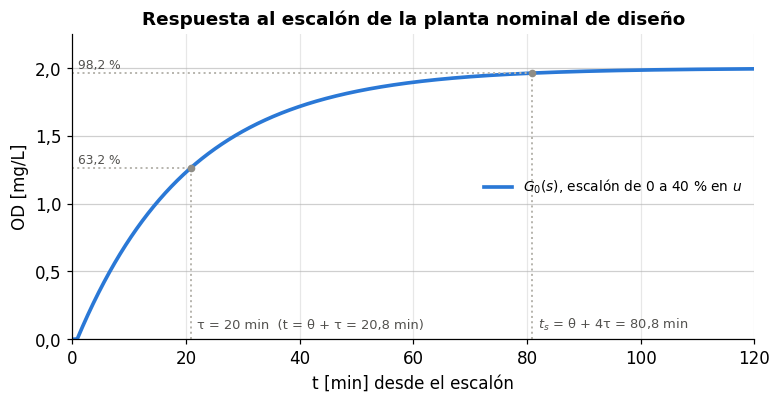

In [36]:
# Planta nominal de diseño:  G0(s) = k_dc e^{-theta s} / (tau s + 1)
KDC_D, TAU_D, THETA_D = 0.05, 20.0, 50/60          # mg/(L·%), min, min (50 s)

# de dónde salen: ventanas ARX de M2 en el rango de la referencia (OD 1,5-3 mg/L),
# el mismo rango que justifica el b0 de diseño (§5)
s_ref = ab[(ab.modulo == 'M2') & ab.y_med.between(1.5, 3)]
print('M2, ventanas de lazo abierto con OD entre 1,5 y 3 mg/L:', len(s_ref))
print(s_ref[['tau', 'K', 'b0']].quantile([.25, .5, .75]).rename(index={.25: 'Q1', .5: 'mediana', .75: 'Q3'}).round(4).to_string())
print('planta de diseño: tau = %.0f min, k_dc = %.2f, theta = %.0f s  ->  b0 = k_dc/tau = %.3f mg/(L·h·%%)'
      % (TAU_D, KDC_D, THETA_D * 60, KDC_D / (TAU_D / 60)))

# respuesta a un escalón de 0 a 40 % en la señal de control: el que sostiene la referencia de 2,0 mg/L
U_D = 40.0                                          # %
t = np.linspace(0, 120, 4801)                                                 # min
y = np.where(t >= THETA_D, KDC_D * U_D * (1 - np.exp(-(t - THETA_D) / TAU_D)), 0.0)
t_tau, y_tau = THETA_D + TAU_D, KDC_D * U_D * (1 - np.exp(-1))                      # 63,2 %
t_s, y_s = THETA_D + 4 * TAU_D, (1 - np.exp(-4)) * KDC_D * U_D                    # criterio 4 tau: 98,2 %
print('u = %.0f %% -> y final = %.2f mg/L   ·   63,2 %% (%.3f mg/L) en t = %.1f min   ·   t_s = theta + 4 tau = %.1f min (%.1f %%)'
      % (U_D, KDC_D * U_D, y_tau, t_tau, t_s, 100 * (1 - np.exp(-4))))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(t, y, lw=2.4, color=AZUL, label='$G_0(s)$, escalón de 0 a 40 % en $u$')
GRIS_CL = '#b8b6af'
for tc, yc, txt_h in ((t_tau, y_tau, '63,2 %'), (t_s, y_s, '98,2 %')):
    ax.plot([tc, tc], [0, yc], color=GRIS_CL, lw=1.3, ls=':')               # vertical hasta la curva
    ax.plot([0, tc], [yc, yc], color=GRIS_CL, lw=1.3, ls=':')                # horizontal hasta la curva
    ax.plot(tc, yc, 'o', ms=4, color='#8f8d86')
    ax.text(1, yc + 0.035, txt_h, fontsize=8, color='#52514e')
ax.text(t_tau + 1, 0.08, 'τ = 20 min  (t = θ + τ = %s min)' % ('%.1f' % t_tau).replace('.', ','),
        fontsize=8.5, color='#52514e')
ax.text(t_s + 1, 0.08, '$t_s$ = θ + 4τ = %s min' % ('%.1f' % t_s).replace('.', ','),
        fontsize=8.5, color='#52514e')
ax.set(xlabel='t [min] desde el escalón', ylabel='OD [mg/L]', xlim=(0, 120), ylim=(0, 2.25),
       title='Respuesta al escalón de la planta nominal de diseño')
ax.set_yticks(np.arange(0, 2.01, 0.5))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: ('%.1f' % v).replace('.', ',')))
ax.legend(frameon=False, fontsize=9, loc='center right')
ax.grid(axis='y', alpha=.6); ax.set_axisbelow(True)

fig.savefig('../../Latex/Tesis/figuras/ident_20_planta_diseno.pdf', bbox_inches='tight')
plt.show()


---
# 14. Un escalón alrededor de la referencia (M3, 13-jun-2025)

Casi todos los escalones de lazo abierto van de soplador apagado a plena carga y el OD
recorre de ~0 a más de 4 mg/L. Cerca de la referencia hay pocos registros limpios: en M2
ninguno; en M3, el del 13-jun-2025. Con 40 kW el OD se asienta en ~1,1 mg/L; a las 04:16 la
potencia sube a 60 kW y el OD vuelve a ~2,5 mg/L, el mismo valor que tenía con 60 kW antes de
bajar la potencia (01:30–03:15). Desde las 06:00 el OD sigue subiendo con la potencia fija:
es la perturbación, no el escalón, así que el estacionario se toma en 05:00–06:00.

`K = Δy/Δu`, con `u` en % de plena carga (`cruce.pct`, P_max = 110,1 kW en M3).

potencia 40.1 -> 59.9 kW  ·  u 36.4 -> 54.4 %  ->  Du = 18.1 %
OD 1.08 -> 2.50 mg/L  ->  Dy = 1.42 mg/L
K = Dy/Du = 0.079 mg/(L·%)   ·   63,2 % del salto (1.98 mg/L) a los 18 min
pendiente en la meseta 05:00-06:00: -0.11 mg/(L·h)


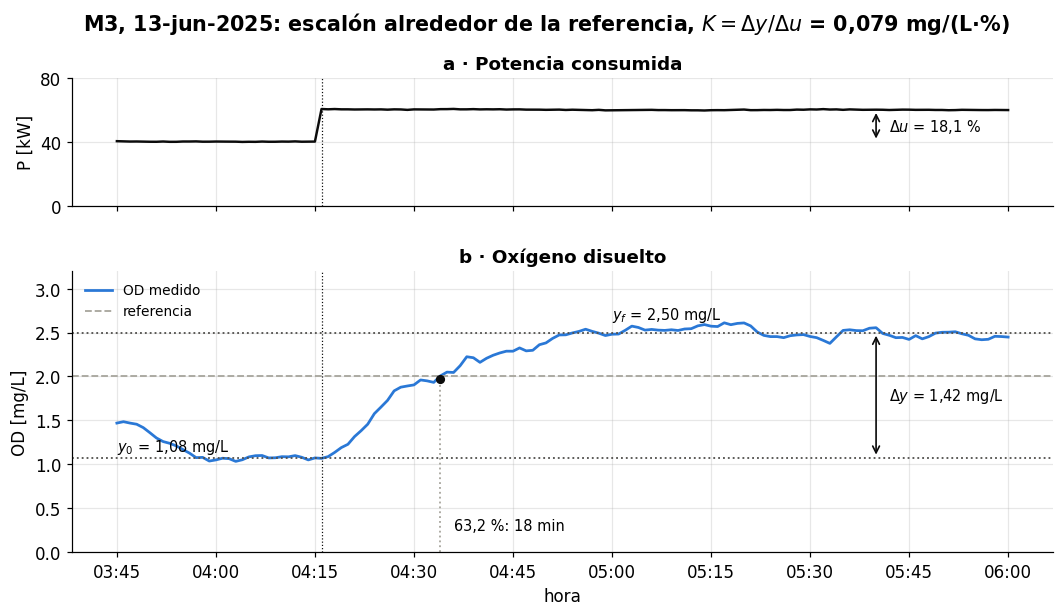

In [37]:
# Escalon de subida de M3 alrededor de la referencia: K = Dy/Du leido directamente en el dato
T_ESC = pd.Timestamp('2025-06-13 04:16')                       # la potencia pasa de 40 a 60 kW
VENT = ('2025-06-13 03:45', '2025-06-13 06:00')                 # de la figura: hasta el estacionario
EST = ('2025-06-13 05:00', '2025-06-13 06:00')                  # meseta final (luego deriva la perturbacion)
w = d.loc[VENT[0]:VENT[1], ['M3_od', 'M3_pot']].copy()
w['u'] = cruce.pct('M3', w.M3_pot)                              # % de plena carga
antes = w.loc[T_ESC - pd.Timedelta('15min'): T_ESC - pd.Timedelta('1min')]
fin = w.loc[EST[0]:EST[1]]
y0, yf, u0, uf = antes.M3_od.mean(), fin.M3_od.mean(), antes.u.mean(), fin.u.mean()
P0, Pf = antes.M3_pot.mean(), fin.M3_pot.mean()
dy, du = yf - y0, uf - u0
K_esc = dy / du
post = w.loc[T_ESC:]
y63 = y0 + 0.632 * dy
t63 = (post.index[np.flatnonzero(post.M3_od.to_numpy() >= y63)[0]] - T_ESC).seconds / 60
print('potencia %.1f -> %.1f kW  ·  u %.1f -> %.1f %%  ->  Du = %.1f %%' % (P0, Pf, u0, uf, du))
print('OD %.2f -> %.2f mg/L  ->  Dy = %.2f mg/L' % (y0, yf, dy))
print('K = Dy/Du = %.3f mg/(L·%%)   ·   63,2 %% del salto (%.2f mg/L) a los %.0f min' % (K_esc, y63, t63))
print('pendiente en la meseta 05:00-06:00: %+.2f mg/(L·h)'
      % (np.polyfit(np.arange(len(fin)), fin.M3_od.to_numpy(), 1)[0] * 60))

coma = lambda v, f='%.2f': (f % v).replace('.', ',')
fig, ax, bx = figura_escalon('M3, 13-jun-2025: escalón alrededor de la referencia, $K = \\Delta y/\\Delta u$ = %s mg/(L·%%)'
                             % coma(K_esc, '%.3f'), 'Potencia consumida')
tf = pd.Timestamp('2025-06-13 05:40')
ax.plot(w.index, w.M3_pot, color=NEGRO, lw=1.6)
ax.annotate('', xy=(tf, Pf), xytext=(tf, P0), arrowprops=dict(arrowstyle='<->', color=NEGRO, lw=1.1))
ax.text(tf + pd.Timedelta('2min'), (P0 + Pf) / 2, '$\\Delta u$ = %s %%' % coma(du, '%.1f'), fontsize=9.5, va='center')
ax.set(ylabel='P [kW]', ylim=(0, 80), yticks=[0, 40, 80])
bx.plot(w.index, w.M3_od, lw=1.8, color=AZUL, label='OD medido')
bx.axhline(2.0, ls='--', lw=1.2, color=GRIS, label='referencia')
for v_ in (y0, yf): bx.axhline(v_, ls=':', lw=1.2, color='#52514e')
bx.text(w.index[0], y0 + .08, '$y_0$ = %s mg/L' % coma(y0), fontsize=9.5)
bx.text(pd.Timestamp(EST[0]), yf + .15, '$y_f$ = %s mg/L' % coma(yf), fontsize=9.5)
bx.annotate('', xy=(tf, yf), xytext=(tf, y0), arrowprops=dict(arrowstyle='<->', color=NEGRO, lw=1.1))
bx.text(tf + pd.Timedelta('2min'), (y0 + yf) / 2, '$\\Delta y$ = %s mg/L' % coma(dy), fontsize=9.5, va='center')
t_63 = T_ESC + pd.Timedelta(minutes=t63)
bx.plot([t_63, t_63], [0, y63], ls=':', lw=1.2, color=GRIS); bx.plot(t_63, y63, 'o', ms=5, color=NEGRO)
bx.text(t_63 + pd.Timedelta('2min'), 0.25, '63,2 %%: %s min' % coma(t63, '%.0f'), fontsize=9.5)
bx.set(ylabel='OD [mg/L]', ylim=(0, 3.2), xlabel='hora')
bx.legend(frameon=False, fontsize=9, loc='upper left')
for x in (ax, bx): x.axvline(T_ESC, color=NEGRO, lw=.8, ls=':')
bx.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
fig.savefig('../../Latex/Tesis/figuras/ident_21_escalon_referencia.pdf', bbox_inches='tight'); plt.show()


## 10.6 El segundo soplador

La señal de control de 0 a 100 % se reparte entre los dos sopladores: el primer 50 % lleva el primero a su
máximo y el otro 50 % enciende y lleva el segundo. En M3, el 26-abr-2025, la potencia pasa por
apagado → 1 soplador (50 kW) → 2 sopladores (115 kW) → 1 soplador (60 kW), y se ve cuánto aporta el segundo
al OD con la misma carga de esa tarde (figura `ident_22_segundo_soplador.pdf` de la tesis).

tramo            inicio  fin    P [kW]  OD al final [mg/L]
apagado          15:55  16:28     0.0    0.61
1 soplador       16:29  18:27    50.1    1.58
2 sopladores     18:28  19:11   114.6    4.55
1 soplador       19:12  20:10    60.0    2.65


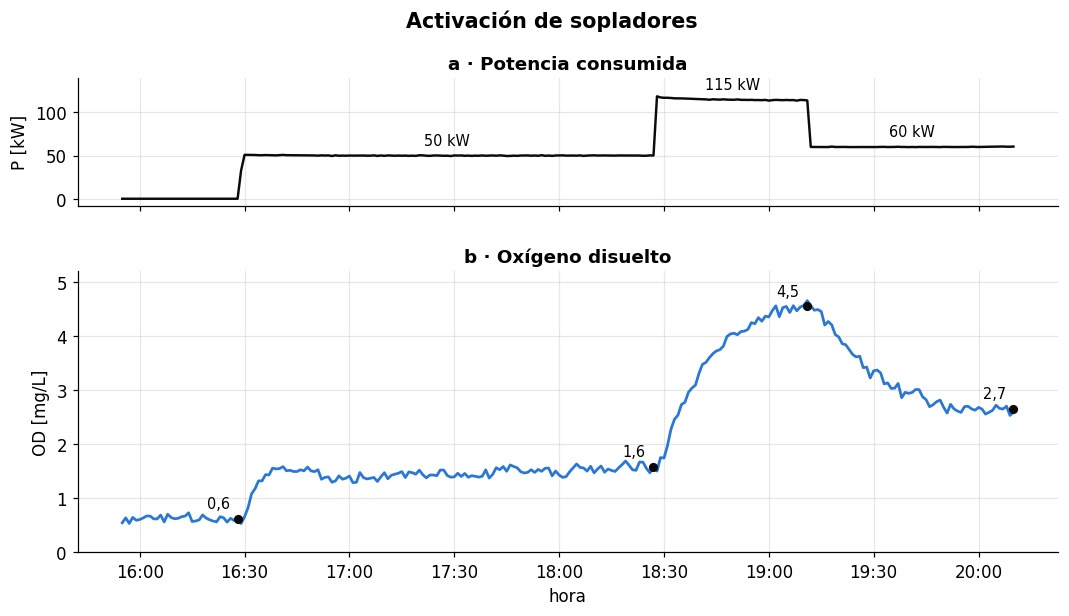

In [38]:
# Figura de la tesis: entrada del segundo soplador en M3 el 26-abr-2025
# La señal de control de 0 a 100 % se reparte entre los dos sopladores: el primer 50 % lleva
# el primero hasta su máximo y el otro 50 % al segundo. Aquí la potencia consumida (el dato
# medido) pasa por: apagado -> 1 soplador -> 2 sopladores -> 1 soplador.
coma = lambda v, f='%.2f': (f % v).replace('.', ',')
w2 = d.loc['2025-04-26 15:55':'2025-04-26 20:10', ['M3_od', 'M3_pot']]
P2, Y2 = w2.M3_pot.interpolate(limit=3), w2.M3_od
niv2 = np.where(P2 < 5, 0, np.where(P2 < 80, 1, 2))
tramos2, i0 = [], 0
for i in range(1, len(niv2) + 1):
    if i == len(niv2) or niv2[i] != niv2[i0]:
        tramos2.append((P2.index[i0], P2.index[i - 1], int(niv2[i0]))); i0 = i
fig, ax, bx = figura_escalon('Activación de sopladores', 'Potencia consumida')
ax.plot(P2.index, P2, color=NEGRO, lw=1.6); bx.plot(Y2.index, Y2, color=AZUL, lw=1.8)
print('tramo            inicio  fin    P [kW]  OD al final [mg/L]')
for x0, x1, n in tramos2:
    pm = P2.loc[x0 + pd.Timedelta(minutes=3):x1].median(); yf_ = Y2.loc[x1 - pd.Timedelta(minutes=5):x1].median()
    bx.plot(x1, yf_, 'o', color=NEGRO, ms=5)
    bx.annotate(coma(yf_, '%.1f'), (x1, yf_), xytext=(-5, 7), textcoords='offset points', ha='right', fontsize=9.5)
    print('%-16s %s  %s  %6.1f  %6.2f' % (['apagado', '1 soplador', '2 sopladores'][n], x0.strftime('%H:%M'), x1.strftime('%H:%M'), pm, yf_))
    if n > 0:
        ax.annotate('%.0f kW' % pm, (x0 + (x1 - x0) / 2, pm), xytext=(0, 5), textcoords='offset points', ha='center', va='bottom', fontsize=9.5)
ax.set(ylabel='P [kW]', ylim=(-8, 140), yticks=[0, 50, 100])
bx.set(ylabel='OD [mg/L]', ylim=(0, 5.2), xlabel='hora')
bx.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
fig.savefig('../../Latex/Tesis/figuras/ident_22_segundo_soplador.pdf', bbox_inches='tight'); plt.show()
